# Next Bill Amount Prediction

Predicting the next bill of each customer from historical usage and billing data.


## 1. Problem Statement

Companies that bill customers on usage or subscriptions need an early view of the next expected bill.
A sudden increase leads to bill shock, support calls and late investigation of abnormal usage.

The task is to explore historical usage and billing patterns, find the main cost drivers, predict the next bill amount
of every customer, explain what drives the prediction, test the accuracy on a **later (chronological) hold-out period**
and flag customers whose predicted bill is unusually high.

## 2. Project Objective

- Understand billing patterns, seasonality and the variables linked to the next bill.
- Predict `next_bill_amount` (regression) using only information available before the forecast point.
- Validate in time order: train on earlier months, test on later months (no future data in training).
- Compare practical baselines (previous bill, recent averages) with several ML models and tune the promising ones.
- Report overall and segment-wise errors, explain predictions, and flag unusually high predicted bills with an uncertainty range.

## 3. Dataset Description

`next_bill_dataset.csv` has **2000 rows and 35 columns**. Each row is one billing record of a customer (1222 customers, 1 to 3 records each),
from Jan 2024 to Aug 2026. The data is synthetic, so the billing rules below were checked in the notebook rather than assumed.

| Group | Columns |
|---|---|
| Identifier and time | `customer_id`, `billing_month`, `billing_year` |
| Customer profile | `customer_tenure_months`, `customer_segment`, `region` |
| Plan | `plan_type`, `plan_price`, `plan_changed`, `previous_plan_price` |
| Usage | `data_usage_gb`, `voice_usage_minutes`, `sms_count`, `roaming_usage_gb`, `overage_data_gb`, `overage_call_minutes`, `average_usage_last_3_months` |
| Charges of the latest bill | `base_charge`, `data_overage_charge`, `call_overage_charge`, `roaming_charge`, `addon_charge`, `discount_amount`, `tax_amount`, `late_payment_fee` |
| Billing history | `previous_bill_amount`, `bill_2_months_ago`, `bill_3_months_ago`, `average_bill_last_3_months`, `average_bill_last_6_months`, `maximum_bill_last_6_months`, `bill_change_percentage` |
| Other | `billing_period_days`, `payment_delay_days` |
| **Target** | `next_bill_amount` |

**Assumptions:** the forecast horizon is one bill ahead. Every input column describes the latest completed billing cycle or earlier,
so it is available at the forecast point. The target is the amount of the following bill.

## 4. Importing Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
import warnings
warnings.filterwarnings('ignore')

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score)

## 5. Loading the Dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    pass   # not running in Colab, the csv is already in the working folder

df = pd.read_csv('next_bill_dataset.csv')

print("Dataset loaded successfully!")
print(df.shape)

Saving next_bill_dataset.csv to next_bill_dataset.csv
Dataset loaded successfully!
(2000, 35)


## 6. Data Preprocessing

First the basic checks: shape, data types, summary statistics, duplicates and missing values.

In [3]:
df.shape

(2000, 35)

In [4]:
df.sample(5)

,customer_id,billing_month,billing_year,customer_tenure_months,customer_segment,region,plan_type,plan_price,plan_changed,previous_plan_price,...,bill_2_months_ago,bill_3_months_ago,average_bill_last_3_months,average_bill_last_6_months,maximum_bill_last_6_months,average_usage_last_3_months,bill_change_percentage,billing_period_days,payment_delay_days,next_bill_amount
1236,CUST-002404,7,2025,29,Senior,Central,Lite 199,199.0,0,199.0,...,234.82,234.82,234.82,234.82,234.82,5.46,0.00,31,0,410.64
1530,CUST-002929,9,2025,70,Small Business,North,Plus 451,451.0,0,451.0,...,681.39,716.79,693.19,696.93,739.21,46.56,0.00,30,0,681.39
1126,CUST-002200,3,2024,20,Family,South,Family 449,449.0,0,449.0,...,706.82,706.82,706.82,706.82,706.82,15.34,0.00,31,0,706.82
971,CUST-001838,4,2025,50,Youth,South,Unlimited 649,649.0,1,349.0,...,509.23,509.23,555.84,548.27,698.03,36.71,27.46,30,0,727.53
47,CUST-000093,1,2026,73,Senior,West,Unlimited 549,549.0,0,549.0,...,529.82,529.82,549.09,648.46,747.82,14.59,10.91,31,1,705.64


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   customer_id                  2000 non-null   object 
 1   billing_month                2000 non-null   int64  
 2   billing_year                 2000 non-null   int64  
 3   customer_tenure_months       2000 non-null   int64  
 4   customer_segment             2000 non-null   object 
 5   region                       2000 non-null   object 
 6   plan_type                    2000 non-null   object 
 7   plan_price                   2000 non-null   float64
 8   plan_changed                 2000 non-null   int64  
 9   previous_plan_price          2000 non-null   float64
 10  data_usage_gb                2000 non-null   float64
 11  voice_usage_minutes          2000 non-null   int64  
 12  sms_count                    2000 non-null   int64  
 13  roaming_usage_gb  

In [6]:
df.describe()

,billing_month,billing_year,customer_tenure_months,plan_price,plan_changed,previous_plan_price,data_usage_gb,voice_usage_minutes,sms_count,roaming_usage_gb,...,bill_2_months_ago,bill_3_months_ago,average_bill_last_3_months,average_bill_last_6_months,maximum_bill_last_6_months,average_usage_last_3_months,bill_change_percentage,billing_period_days,payment_delay_days,next_bill_amount
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,5.990500,2024.88000,52.136500,521.463000,0.029000,520.764000,32.056065,614.00400,75.534000,0.139155,...,769.758055,773.048820,791.045940,778.597565,1067.787620,31.526945,14.528915,30.441000,1.711500,829.322355
std,3.323392,0.77904,30.995116,273.586667,0.167848,276.136165,31.602617,485.60959,93.356513,0.754627,...,452.694071,464.892011,420.199288,393.528016,679.248377,29.414284,57.525081,0.824536,4.640909,515.048672
min,1.000000,2024.00000,5.000000,199.000000,0.000000,199.000000,1.160000,32.00000,0.000000,0.000000,...,152.630000,152.630000,152.630000,190.200000,216.030000,1.030000,-87.640000,28.000000,0.000000,152.630000
25%,3.000000,2024.00000,29.000000,349.000000,0.000000,349.000000,9.480000,258.00000,20.000000,0.000000,...,489.610000,470.820000,501.422500,505.570000,615.350000,9.817500,0.000000,30.000000,0.000000,505.570000
50%,6.000000,2025.00000,50.000000,451.000000,0.000000,451.000000,22.370000,471.00000,42.000000,0.000000,...,681.390000,681.390000,708.090000,713.110000,852.715000,22.125000,0.000000,31.000000,0.000000,708.000000
75%,8.000000,2026.00000,70.000000,649.000000,0.000000,649.000000,43.895000,843.25000,96.000000,0.000000,...,911.152500,926.212500,1002.702500,975.117500,1360.600000,44.422500,15.250000,31.000000,2.000000,1016.630000
max,12.000000,2026.00000,163.000000,1549.000000,1.000000,1549.000000,300.000000,4683.00000,988.000000,9.600000,...,3363.000000,6429.820000,3403.020000,2587.840000,6429.820000,243.730000,845.280000,31.000000,45.000000,5284.570000


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(2000, 35)

In [10]:
df.isnull().sum()

,0
customer_id,0
billing_month,0
billing_year,0
customer_tenure_months,0
customer_segment,0
region,0
plan_type,0
plan_price,0
plan_changed,0
previous_plan_price,0


There are no duplicates and no missing values, so nothing had to be dropped or imputed.

### Billing date and data validation

`billing_year` and `billing_month` are combined into a billing date. The data is sorted in time order because the whole
project depends on a chronological split.

In [11]:
df['billing_date'] = pd.to_datetime(
    df['billing_year'].astype(str) + '-' +
    df['billing_month'].astype(str) + '-01'
)

print(df['billing_date'].value_counts().sort_index())

billing_date
2024-01-01    63
2024-02-01    64
2024-03-01    63
2024-04-01    61
2024-05-01    61
2024-06-01    60
2024-07-01    61
2024-08-01    63
2024-09-01    61
2024-10-01    61
2024-11-01    63
2024-12-01    60
2025-01-01    65
2025-02-01    61
2025-03-01    64
2025-04-01    63
2025-05-01    62
2025-06-01    63
2025-07-01    64
2025-08-01    62
2025-09-01    65
2025-10-01    63
2025-11-01    61
2025-12-01    65
2026-01-01    64
2026-02-01    62
2026-03-01    62
2026-04-01    60
2026-05-01    63
2026-06-01    64
2026-07-01    61
2026-08-01    65
Name: count, dtype: int64


In [12]:
# Sort chronologically
df = df.sort_values('billing_date').reset_index(drop=True)

print("Billing period:", df['billing_date'].min().date(), "to", df['billing_date'].max().date())
print("Customers:", df['customer_id'].nunique(), "| Records:", len(df))

Billing period: 2024-01-01 to 2026-08-01
Customers: 1222 | Records: 2000


In [13]:
# Validate the billing rules: is the latest bill equal to its components plus tax?
bill_from_components = (
    df['base_charge'] + df['data_overage_charge'] + df['call_overage_charge'] +
    df['roaming_charge'] + df['addon_charge'] - df['discount_amount'] +
    df['late_payment_fee'] + df['tax_amount']
)

print("Max difference between previous_bill_amount and sum of its components:",
      round((bill_from_components - df['previous_bill_amount']).abs().max(), 6))

# average of the last 3 bills should include the previous bill
avg3_check = (df['previous_bill_amount'] + df['bill_2_months_ago'] + df['bill_3_months_ago']) / 3
print("Max difference between average_bill_last_3_months and the mean of the 3 bills:",
      round((avg3_check - df['average_bill_last_3_months']).abs().max(), 4))

Max difference between previous_bill_amount and sum of its components: 0.0
Max difference between average_bill_last_3_months and the mean of the 3 bills: 0.0033


The previous bill is exactly the sum of its charges plus tax, and the history columns are built from earlier bills.
So all input columns belong to the past and none of them contains the target (no target leakage).

### Separating features and target

In [14]:
# Separate independent and dependent variables

X = df.drop(['customer_id', 'next_bill_amount', 'billing_date'], axis=1)
y = df['next_bill_amount']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2000, 33)
Target shape: (2000,)


In [15]:
# Identify categorical columns
categorical_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()

# Identify numerical columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: ['customer_segment', 'region', 'plan_type']
Numerical Columns: ['billing_month', 'billing_year', 'customer_tenure_months', 'plan_price', 'plan_changed', 'previous_plan_price', 'data_usage_gb', 'voice_usage_minutes', 'sms_count', 'roaming_usage_gb', 'overage_data_gb', 'overage_call_minutes', 'base_charge', 'data_overage_charge', 'call_overage_charge', 'roaming_charge', 'addon_charge', 'discount_amount', 'tax_amount', 'late_payment_fee', 'previous_bill_amount', 'bill_2_months_ago', 'bill_3_months_ago', 'average_bill_last_3_months', 'average_bill_last_6_months', 'maximum_bill_last_6_months', 'average_usage_last_3_months', 'bill_change_percentage', 'billing_period_days', 'payment_delay_days']


## 7. Exploratory Data Analysis

The EDA below is descriptive and uses the full data. No cleaning threshold or feature decision is learned from it;
all of those are computed later on the training months only.

### Target variable

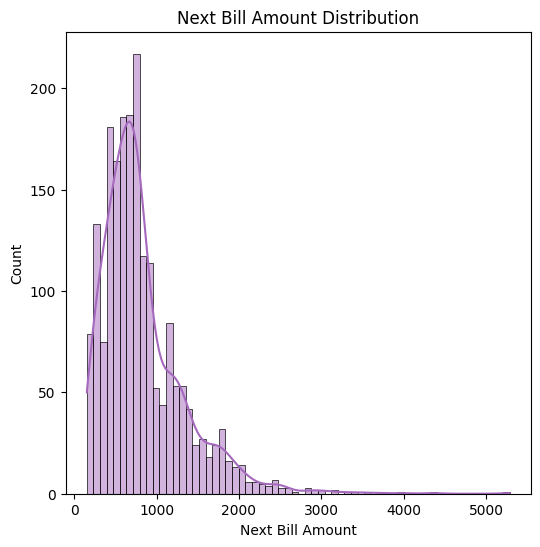

In [16]:
plt.figure(figsize=(6,6))

sns.histplot(
    df['next_bill_amount'],
    kde=True,
    color='#a569bd'
)

plt.title('Next Bill Amount Distribution')
plt.xlabel('Next Bill Amount')
plt.ylabel('Count')
plt.show()

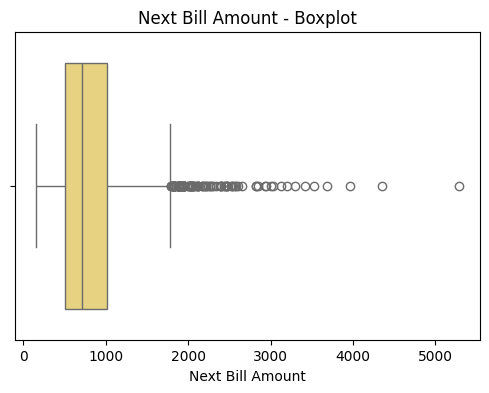

In [17]:
plt.figure(figsize=(6,4))

sns.boxplot(
    x=df['next_bill_amount'],
    color='#f7dc6f'
)

plt.title('Next Bill Amount - Boxplot')
plt.xlabel('Next Bill Amount')
plt.show()

### Univariate Analysis Of Numerical Feature

In [18]:
numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Total Numerical Columns:", len(numerical_cols))
print("\nNumerical Columns:")
print(numerical_cols)

Total Numerical Columns: 31

Numerical Columns:
['billing_month', 'billing_year', 'customer_tenure_months', 'plan_price', 'plan_changed', 'previous_plan_price', 'data_usage_gb', 'voice_usage_minutes', 'sms_count', 'roaming_usage_gb', 'overage_data_gb', 'overage_call_minutes', 'base_charge', 'data_overage_charge', 'call_overage_charge', 'roaming_charge', 'addon_charge', 'discount_amount', 'tax_amount', 'late_payment_fee', 'previous_bill_amount', 'bill_2_months_ago', 'bill_3_months_ago', 'average_bill_last_3_months', 'average_bill_last_6_months', 'maximum_bill_last_6_months', 'average_usage_last_3_months', 'bill_change_percentage', 'billing_period_days', 'payment_delay_days', 'next_bill_amount']


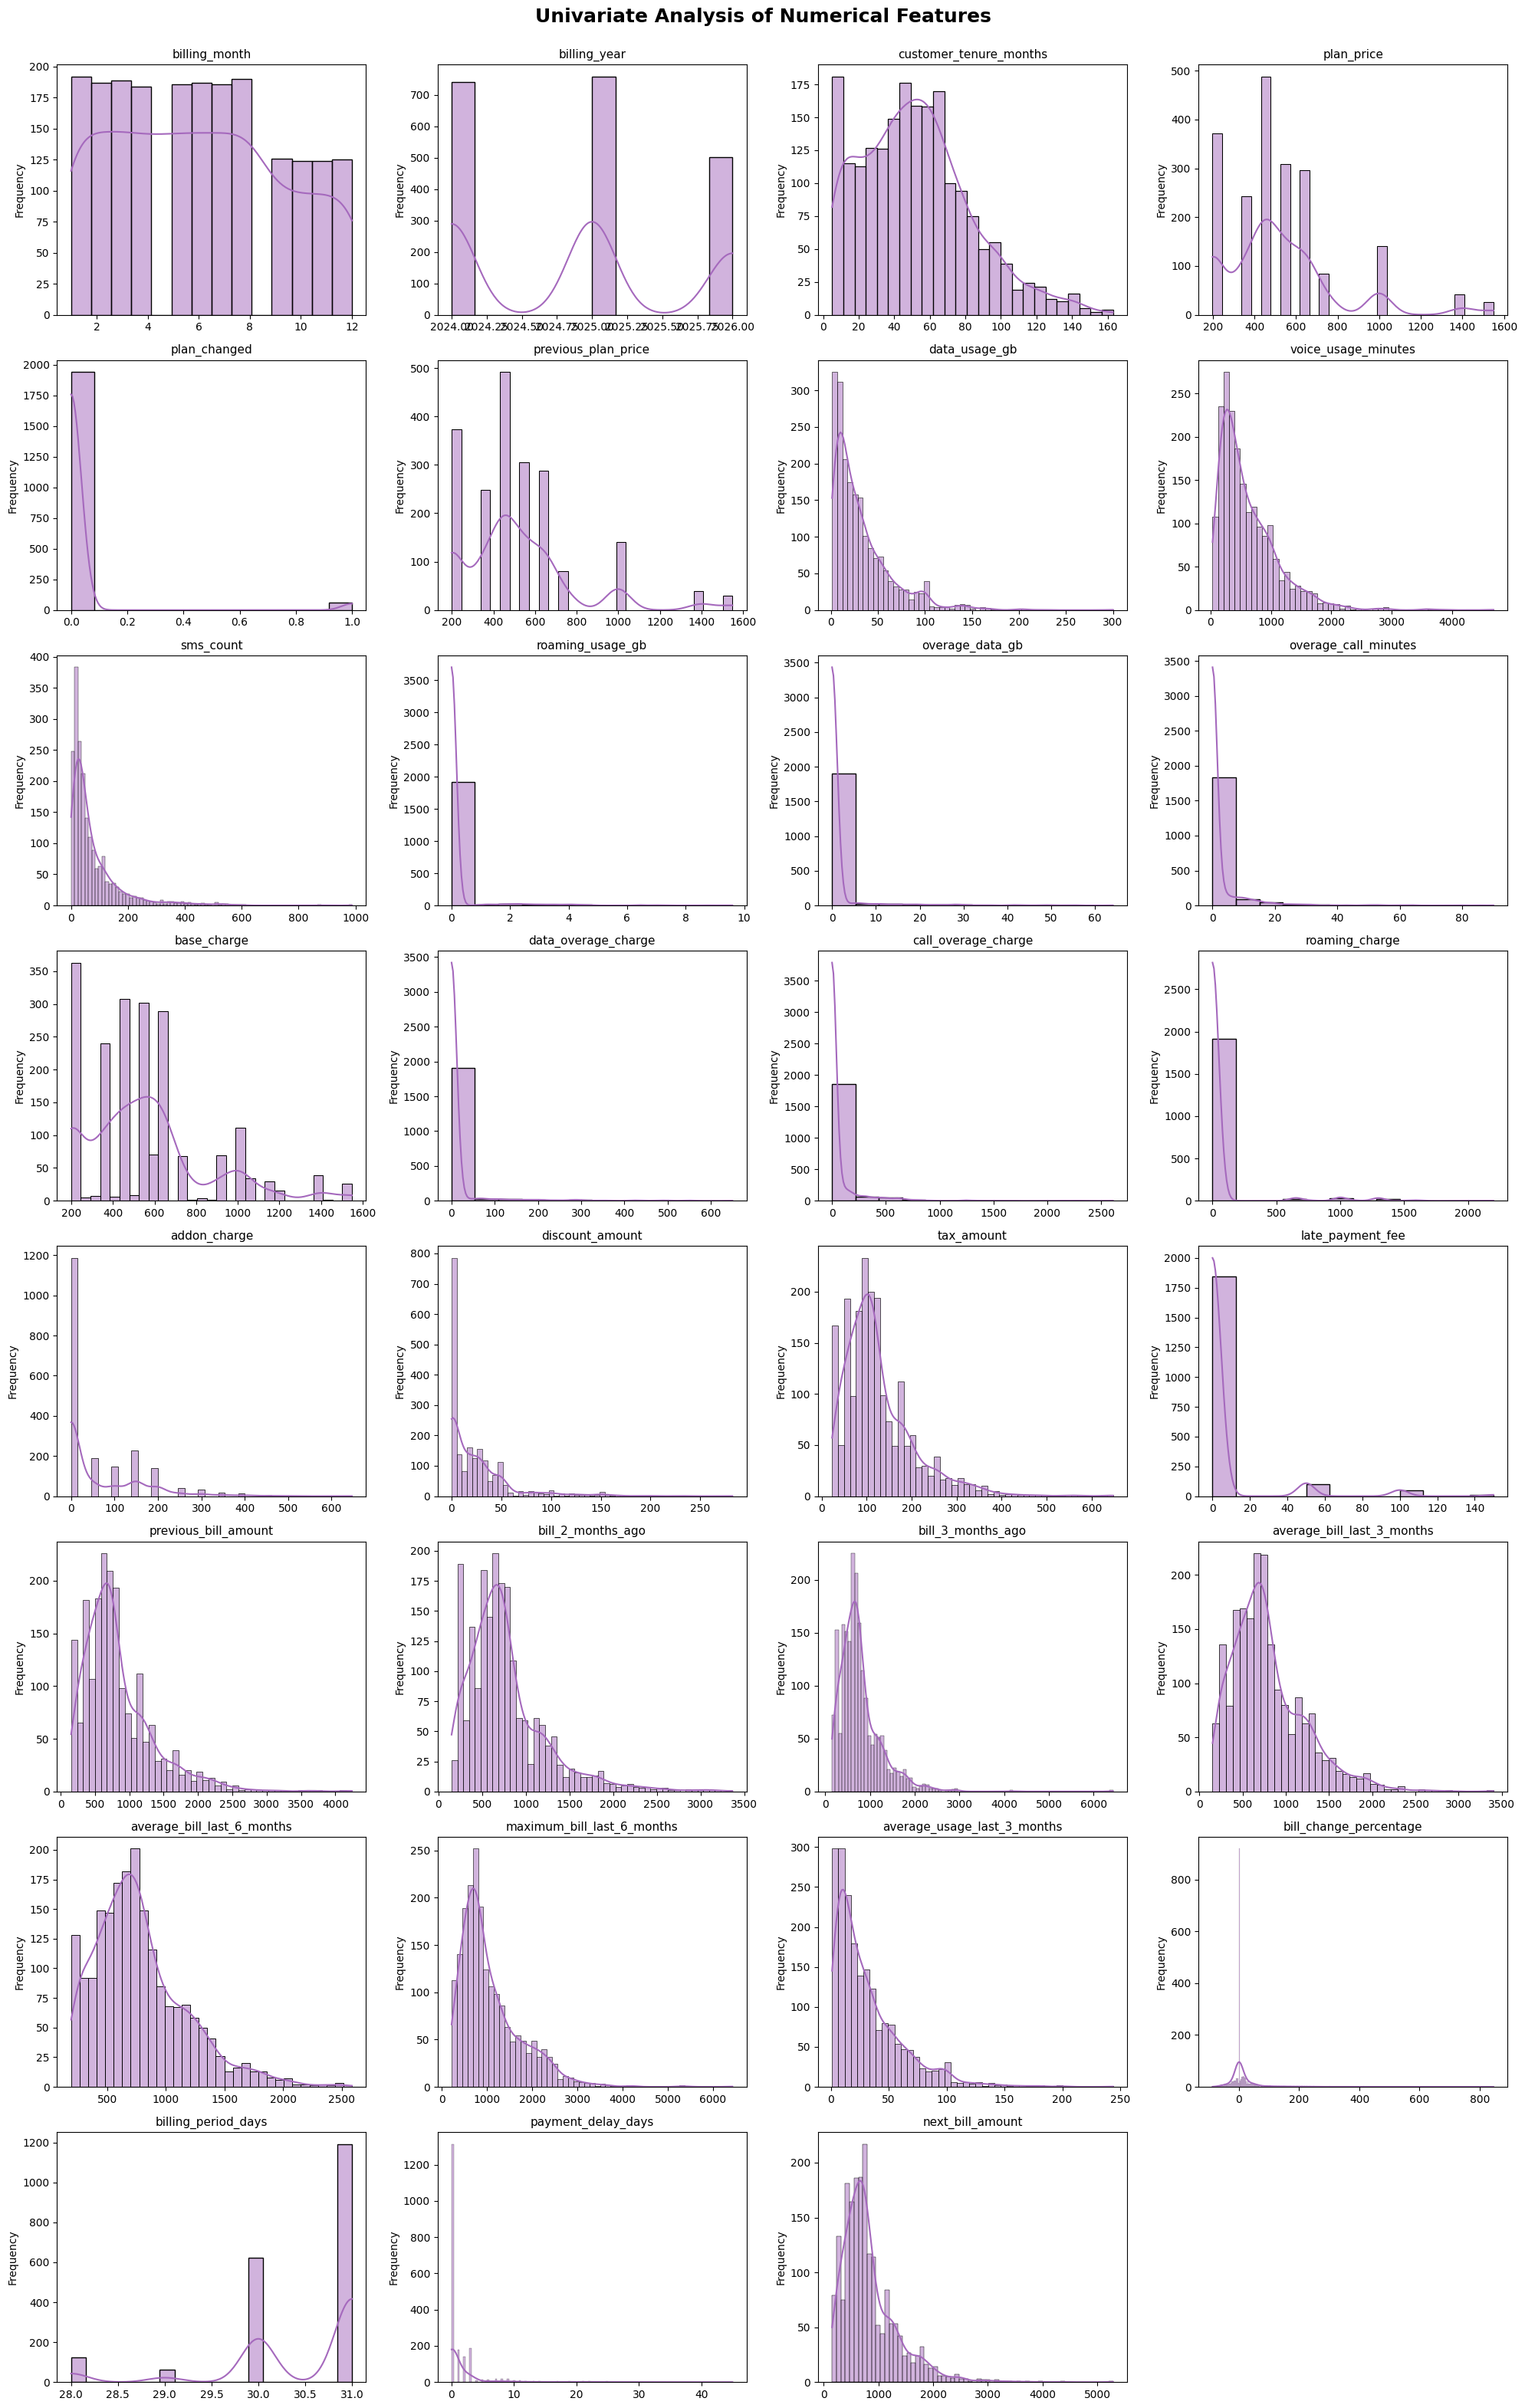

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Set grid dimensions
n_cols = 4
n_rows = math.ceil(len(numerical_cols) / n_cols)

# Create one figure
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 4)
)

axes = axes.flatten()

# Plot each numerical feature
for i, col in enumerate(numerical_cols):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        color='#a569bd',
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequency')

# Hide unused subplots
for j in range(len(numerical_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    'Univariate Analysis of Numerical Features',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [20]:
skew_values = df[numerical_cols].skew()

skew_df = pd.DataFrame({
    'Feature': skew_values.index,
    'Skewness': skew_values.values
})

skew_df = skew_df.sort_values(
    by='Skewness',
    ascending=False
)

print(skew_df.to_string(index=False))

                    Feature  Skewness
        call_overage_charge  6.899118
           roaming_usage_gb  6.880166
            overage_data_gb  6.831167
        data_overage_charge  6.743616
       overage_call_minutes  6.322511
               plan_changed  5.617825
             roaming_charge  5.279876
     bill_change_percentage  4.925216
         payment_delay_days  4.821268
           late_payment_fee  4.216493
                  sms_count  3.043579
            discount_amount  2.547833
          bill_3_months_ago  2.328679
              data_usage_gb  2.078793
           next_bill_amount  1.965195
        voice_usage_minutes  1.951853
average_usage_last_3_months  1.814040
                 tax_amount  1.724518
       previous_bill_amount  1.718075
          bill_2_months_ago  1.706764
               addon_charge  1.682624
 maximum_bill_last_6_months  1.621675
        previous_plan_price  1.494674
                 plan_price  1.459666
 average_bill_last_3_months  1.193627
            

### univariate Analysis on Categorical Column

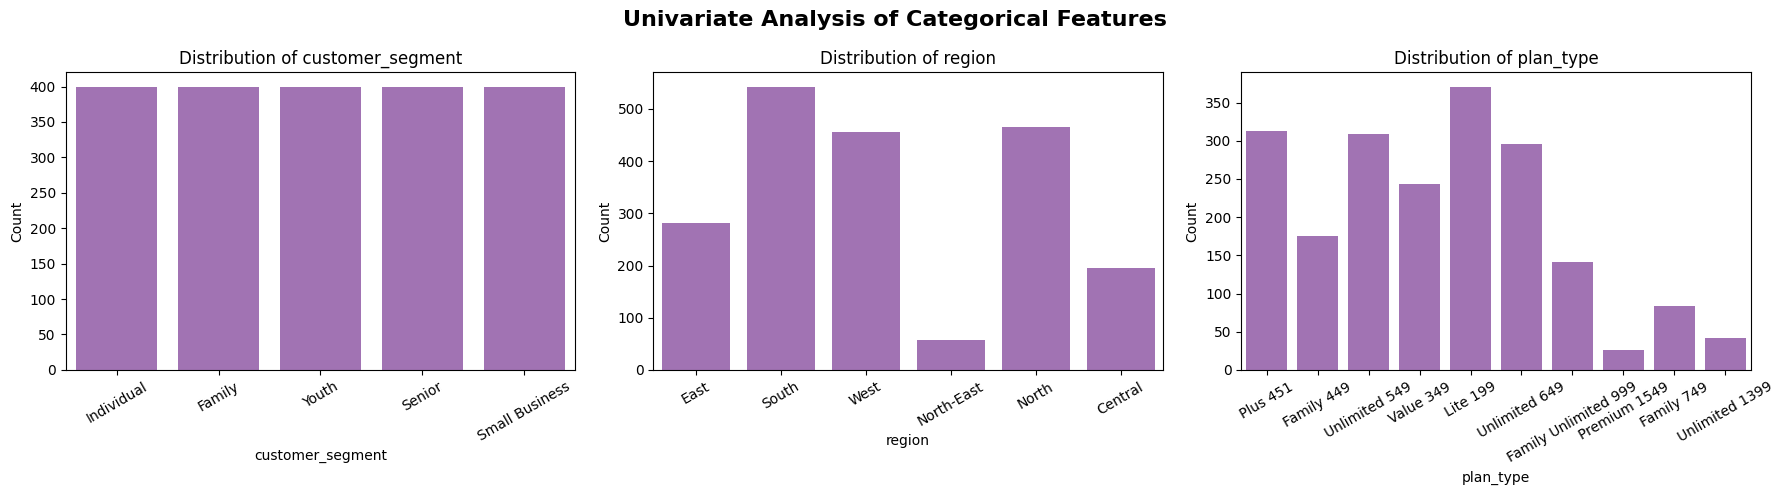

In [21]:
# Select meaningful categorical columns
categorical_cols = [
    'customer_segment',
    'region',
    'plan_type'
]

# Create 1 row with 3 plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(categorical_cols):

    sns.countplot(
        data=df,
        x=col,
        ax=axes[i],
        color='#a569bd'
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle(
    'Univariate Analysis of Categorical Features',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### Bivariate and Multivariate Analysis

### Numerical vs Numerical plots

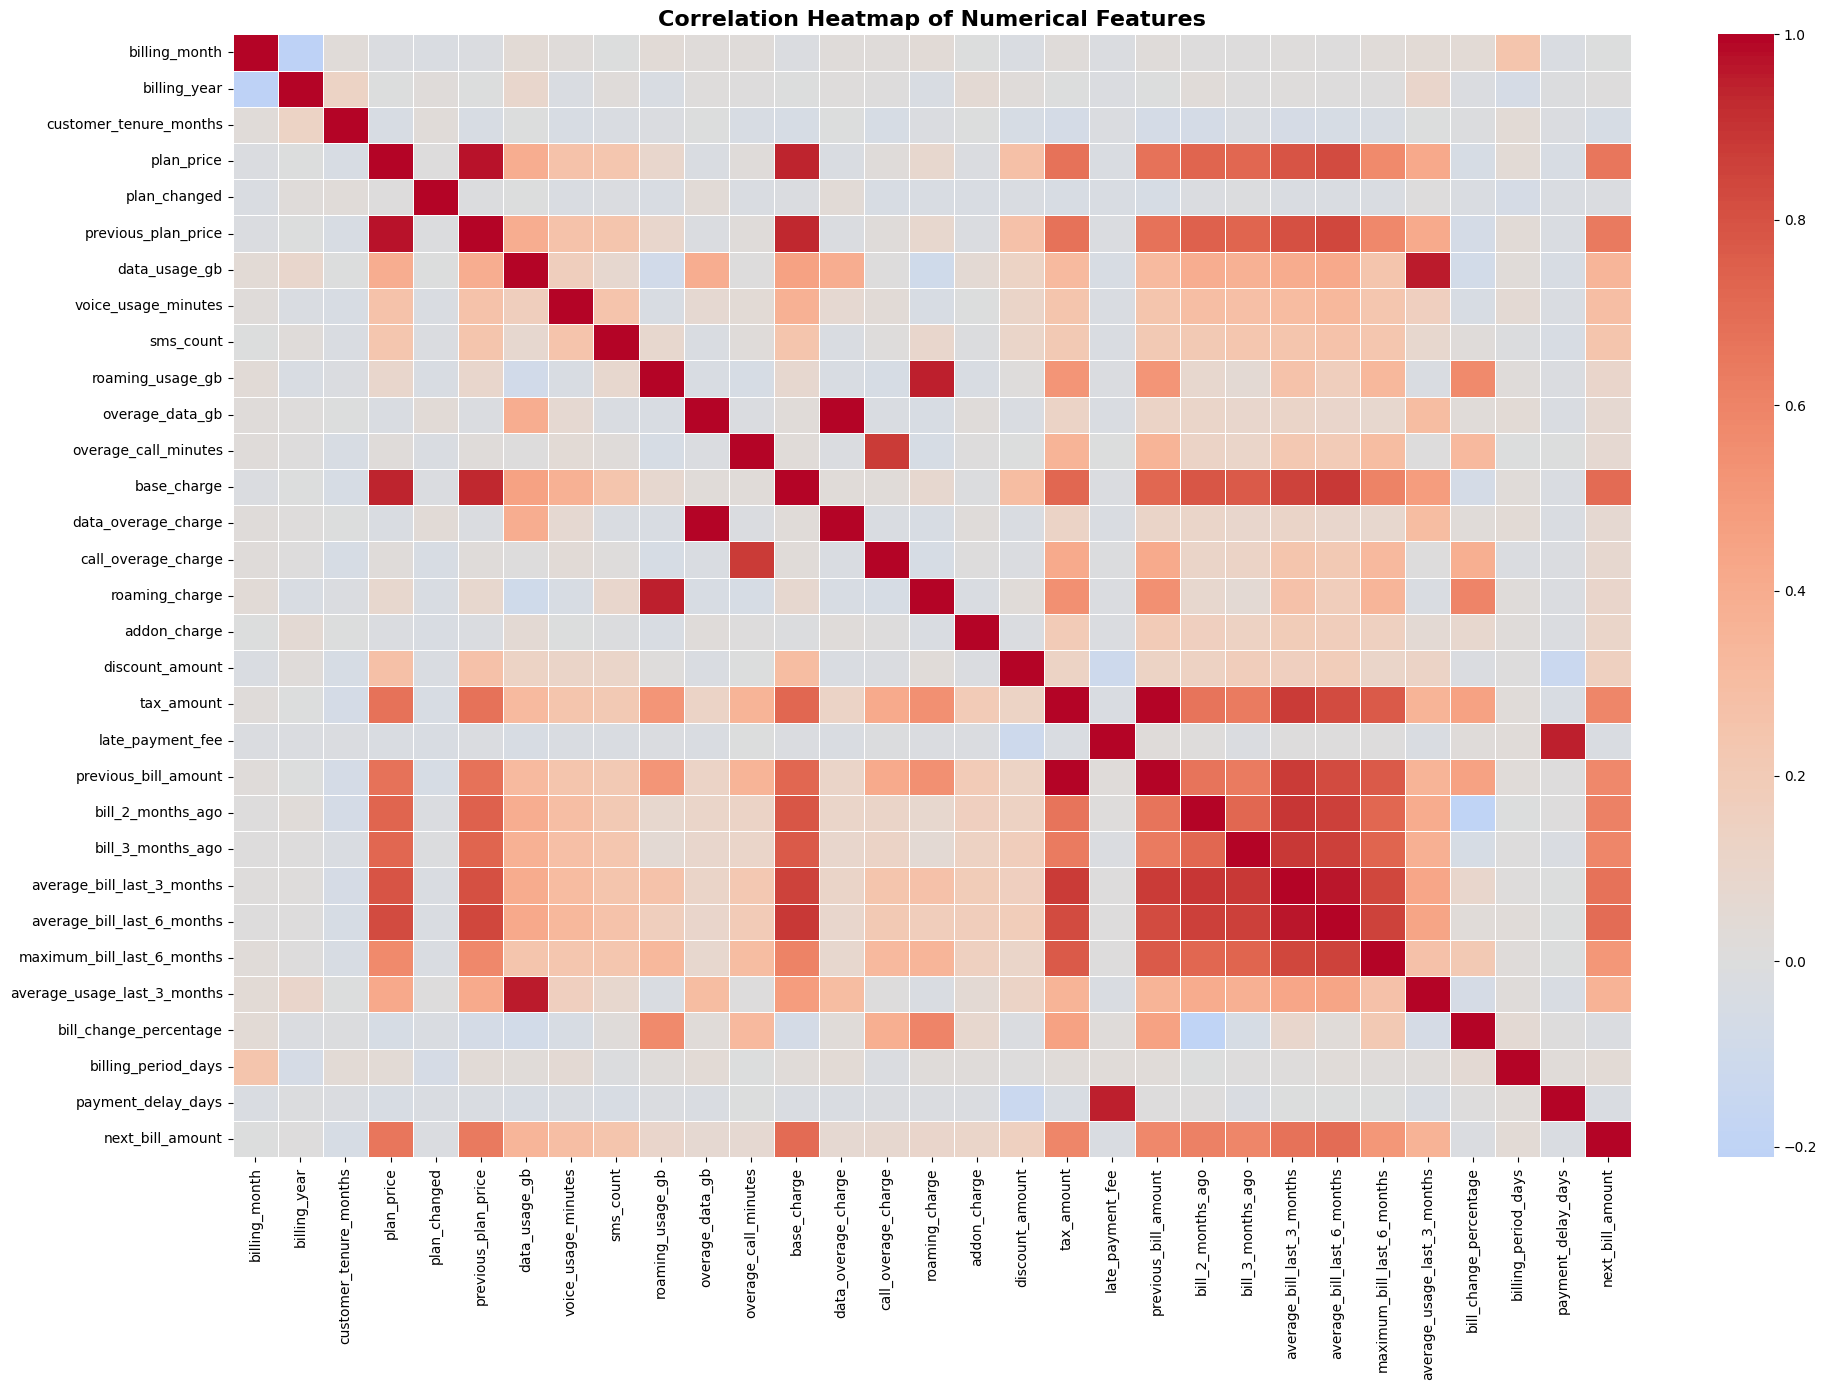

In [22]:
plt.figure(figsize=(20, 14))

correlation = df[numerical_cols].corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5,
    center=0
)

plt.title(
    'Correlation Heatmap of Numerical Features',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

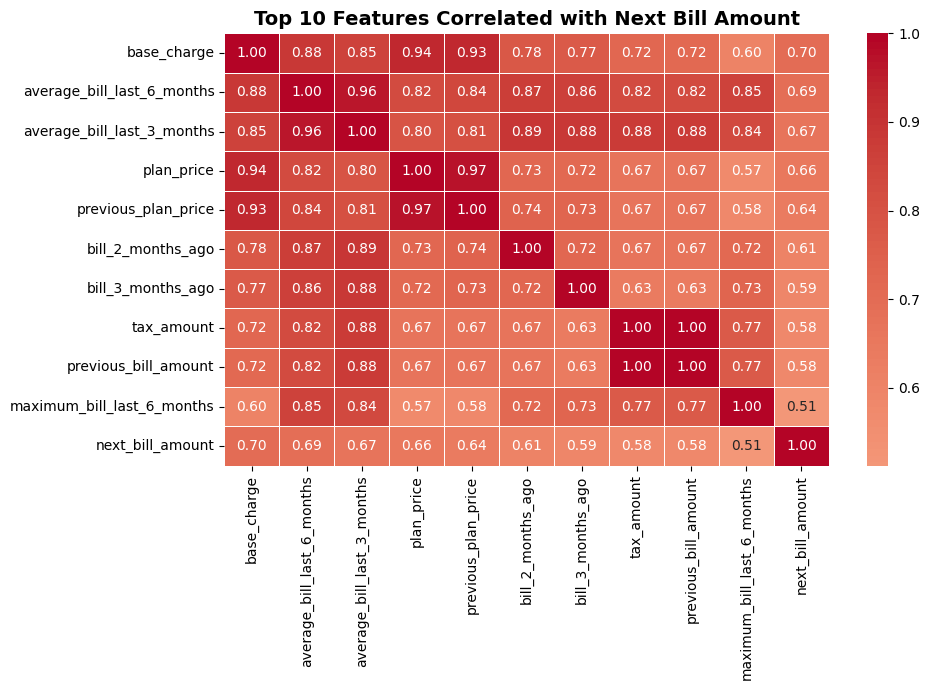

In [23]:
# Calculate correlation with target
target_corr = df[numerical_cols].corr()['next_bill_amount']

# Remove target itself
target_corr = target_corr.drop('next_bill_amount')

# Select top 10 features by absolute correlation
top_features = target_corr.abs().sort_values(
    ascending=False
).head(10).index

# Create correlation dataframe
corr_matrix = df[
    list(top_features) + ['next_bill_amount']
].corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title(
    'Top 10 Features Correlated with Next Bill Amount',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()
#Which historical billing variables have strong relationships with the next bill.
#Whether usage and charges are related to the target.
#Which features deserve further investigation.

In [24]:
# Check customer records
print("Total customers:", df['customer_id'].nunique())

print("\nRecords per customer:")
print(df.groupby('customer_id').size().describe())

# Display customers with multiple billing records
print("\nSample customers:")
print(
    df.groupby('customer_id')
      .size()
      .sort_values(ascending=False)
      .head(10)
)
#his determines whether we can visualize a customer's billing changes over time.

Total customers: 1222

Records per customer:
count    1222.000000
mean        1.636661
std         0.810798
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         3.000000
dtype: float64

Sample customers:
customer_id
CUST-000722    3
CUST-000710    3
CUST-001624    3
CUST-001638    3
CUST-002958    3
CUST-001661    3
CUST-000679    3
CUST-000674    3
CUST-002800    3
CUST-002931    3
dtype: int64


In [25]:
# Find customer with maximum billing records
customer_counts = df['customer_id'].value_counts()

customer_id = customer_counts.idxmax()

# Filter selected customer's records
customer_df = df[
    df['customer_id'] == customer_id
].sort_values(['billing_year', 'billing_month'])

# Display customer details
print("Selected Customer:", customer_id)

print("\nBilling History:")

columns = [
    'billing_year',
    'billing_month',
    'plan_price',
    'data_usage_gb',
    'voice_usage_minutes',
    'data_overage_charge',
    'call_overage_charge',
    'roaming_charge',
    'addon_charge',
    'tax_amount',
    'previous_bill_amount',
    'next_bill_amount'
]

print(customer_df[columns].to_string(index=False))

Selected Customer: CUST-001981

Billing History:
 billing_year  billing_month  plan_price  data_usage_gb  voice_usage_minutes  data_overage_charge  call_overage_charge  roaming_charge  addon_charge  tax_amount  previous_bill_amount  next_bill_amount
         2024              1       349.0          28.09                  223                  0.0                  0.0             0.0           0.0       62.82                461.82            411.82
         2024              8       349.0          36.60                  229                 70.0                  0.0             0.0           0.0       75.42                494.42            411.82
         2025              4       349.0          19.79                  196                  0.0                  0.0             0.0           0.0       62.82                561.82            461.82


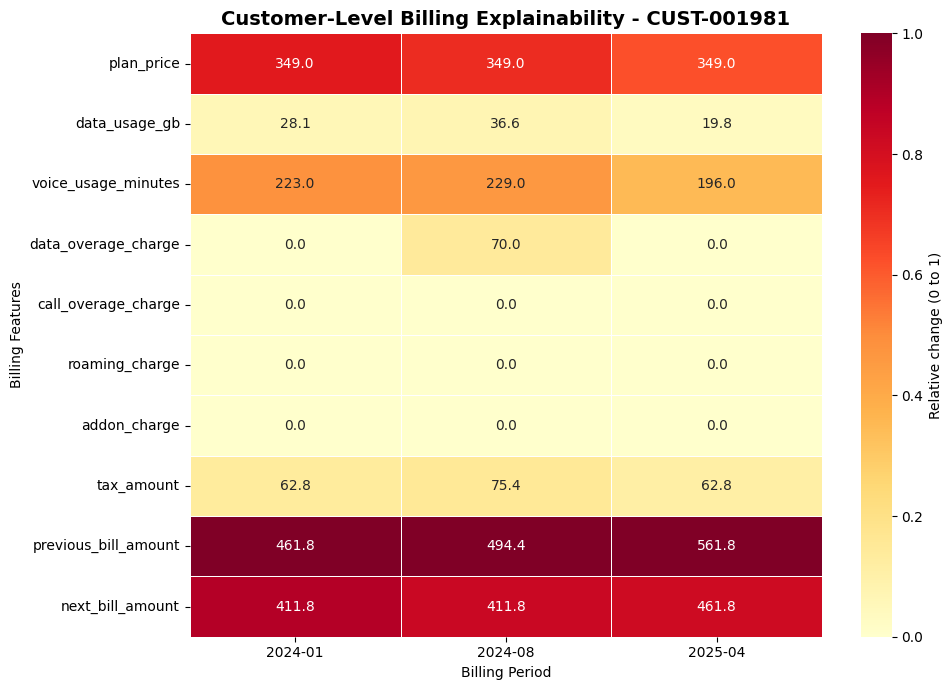

In [26]:
# Select important billing features
customer_features = [
    'plan_price',
    'data_usage_gb',
    'voice_usage_minutes',
    'data_overage_charge',
    'call_overage_charge',
    'roaming_charge',
    'addon_charge',
    'tax_amount',
    'previous_bill_amount',
    'next_bill_amount'
]

# Create readable billing period labels
customer_df['billing_period'] = (
    customer_df['billing_year'].astype(str) + '-' +
    customer_df['billing_month'].astype(str).str.zfill(2)
)

# Prepare data
heatmap_data = customer_df.set_index(
    'billing_period'
)[customer_features].T

# Normalize each feature for visual comparison
normalized_data = heatmap_data.apply(
    lambda x: (x - x.min()) / (x.max() - x.min())
    if x.max() != x.min()
    else x * 0
)

# Plot heatmap with original values as annotations
plt.figure(figsize=(10, 7))

sns.heatmap(
    normalized_data,
    annot=heatmap_data,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Relative change (0 to 1)'}
)

plt.title(
    f'Customer-Level Billing Explainability - {customer_id}',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Billing Period')
plt.ylabel('Billing Features')
plt.tight_layout()
plt.show()

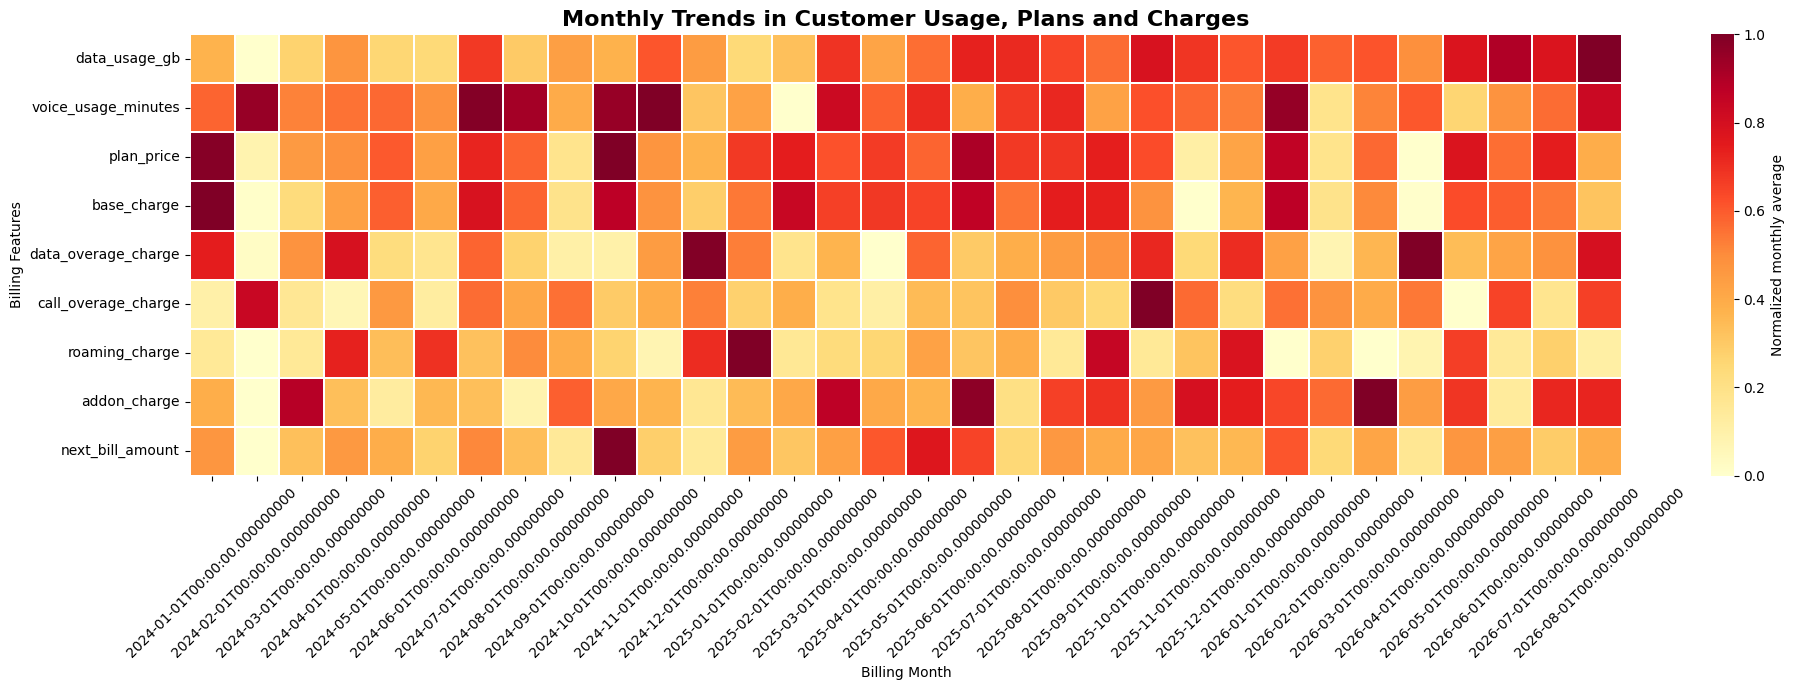

In [27]:
# Select important features for trend analysis
trend_features = [
    'data_usage_gb',
    'voice_usage_minutes',
    'plan_price',
    'base_charge',
    'data_overage_charge',
    'call_overage_charge',
    'roaming_charge',
    'addon_charge',
    'next_bill_amount'
]

# Calculate monthly averages
monthly_trends = df.groupby('billing_date')[
    trend_features
].mean()

# Normalize each feature for comparison
monthly_normalized = monthly_trends.T

monthly_normalized = monthly_normalized.apply(
    lambda x: (x - x.min()) / (x.max() - x.min())
    if x.max() != x.min()
    else x * 0,
    axis=1
)

# Plot heatmap
plt.figure(figsize=(20, 7))

sns.heatmap(
    monthly_normalized,
    cmap='YlOrRd',
    linewidths=0.3,
    annot=False,
    cbar_kws={'label': 'Normalized monthly average'}
)

plt.title(
    'Monthly Trends in Customer Usage, Plans and Charges',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Billing Month')
plt.ylabel('Billing Features')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

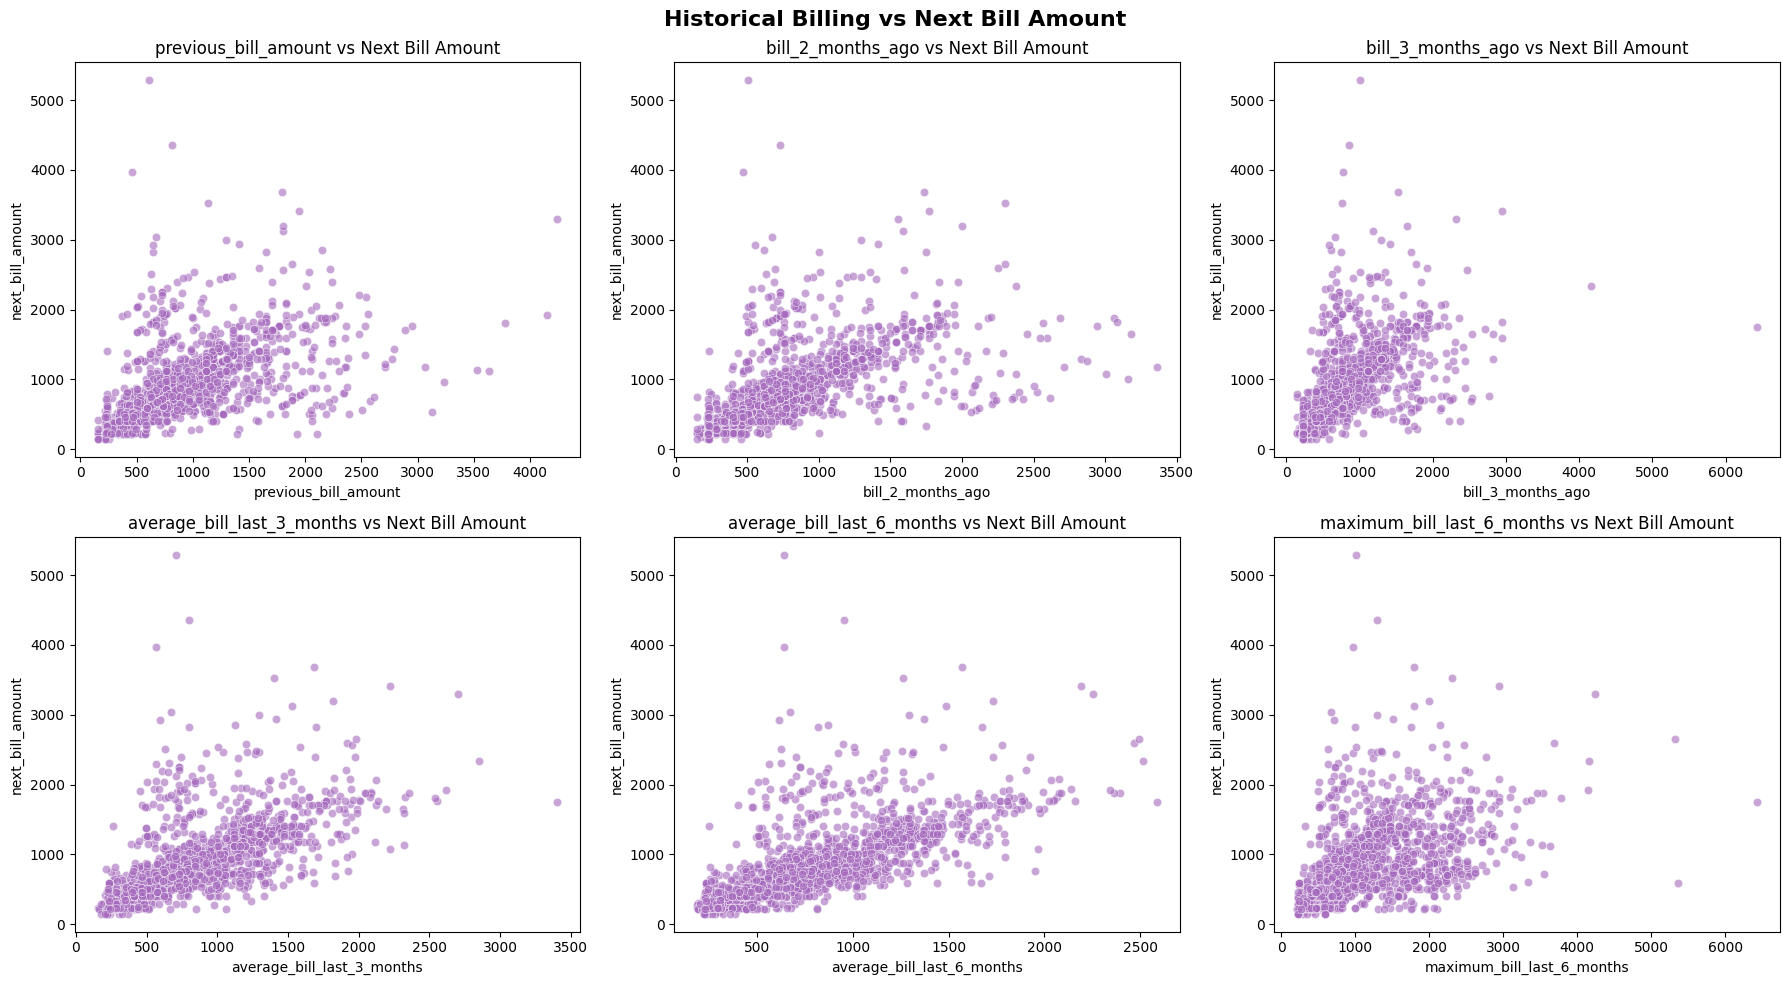

In [28]:
features = [
    'previous_bill_amount',
    'bill_2_months_ago',
    'bill_3_months_ago',
    'average_bill_last_3_months',
    'average_bill_last_6_months',
    'maximum_bill_last_6_months'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(features):

    sns.scatterplot(
        data=df,
        x=col,
        y='next_bill_amount',
        ax=axes.flatten()[i],
        color='#a569bd',
        alpha=0.6
    )

    axes.flatten()[i].set_title(
        f'{col} vs Next Bill Amount'
    )

plt.suptitle(
    'Historical Billing vs Next Bill Amount',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

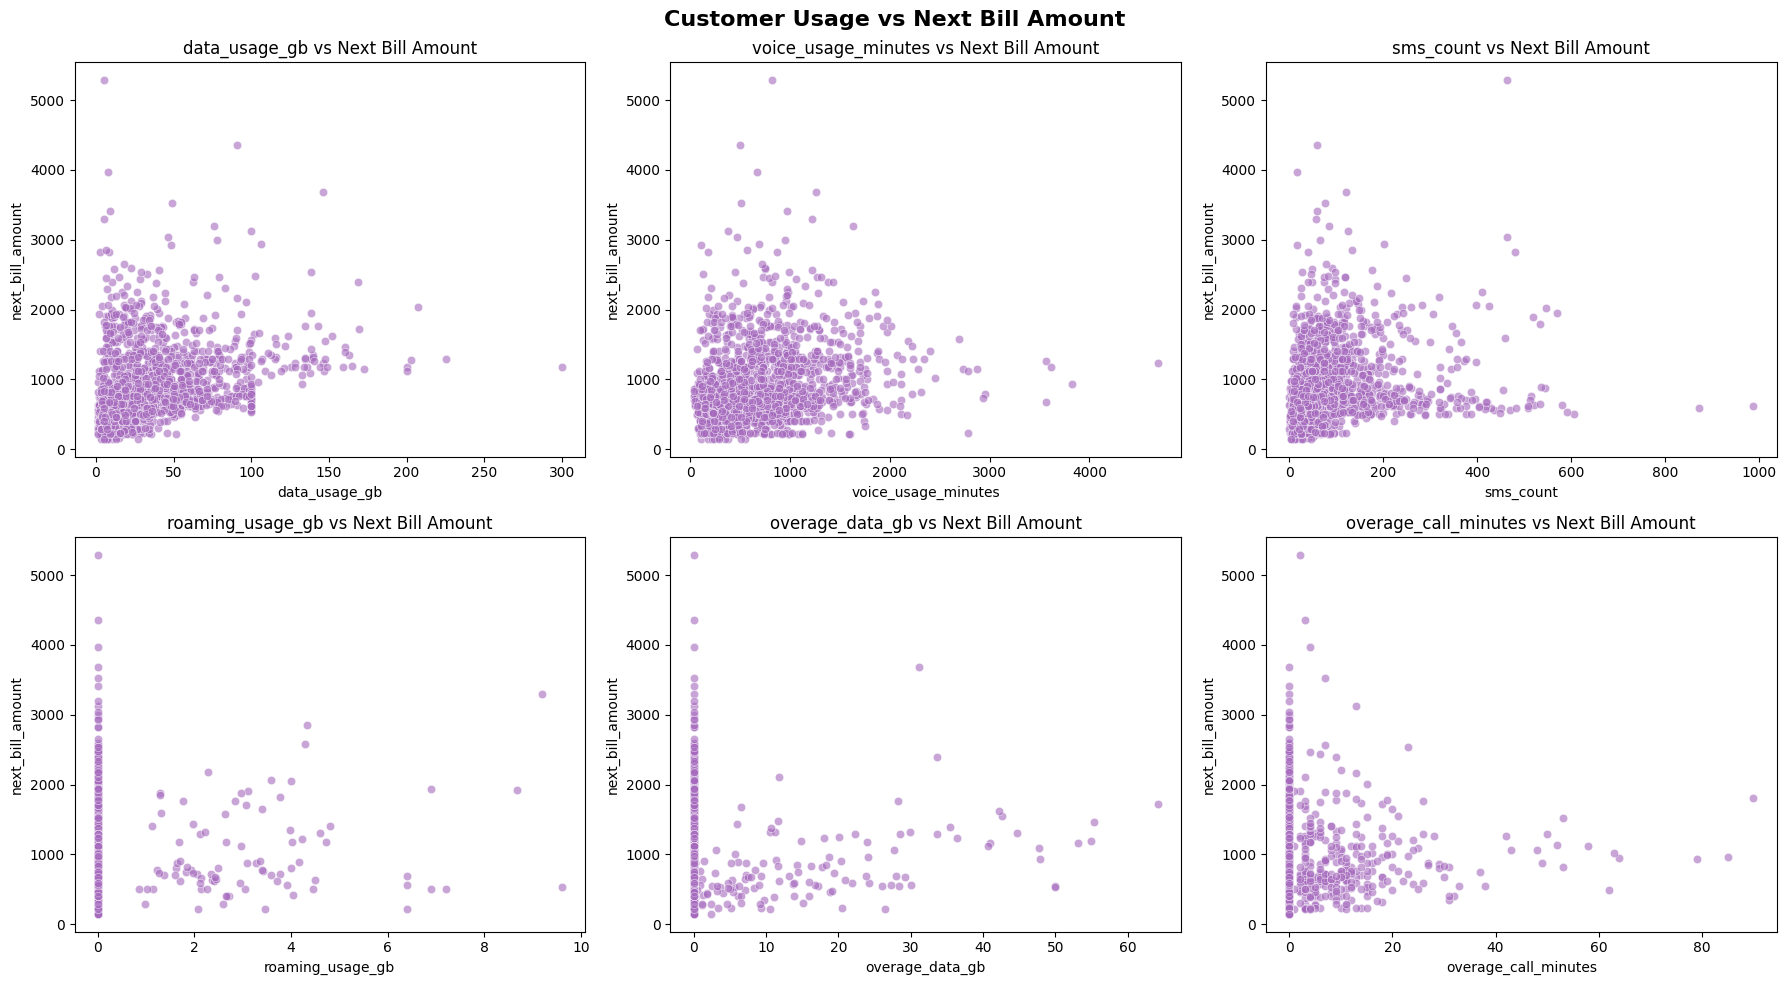

In [29]:
features = [
    'data_usage_gb',
    'voice_usage_minutes',
    'sms_count',
    'roaming_usage_gb',
    'overage_data_gb',
    'overage_call_minutes'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(features):

    sns.scatterplot(
        data=df,
        x=col,
        y='next_bill_amount',
        ax=axes.flatten()[i],
        color='#a569bd',
        alpha=0.6
    )

    axes.flatten()[i].set_title(
        f'{col} vs Next Bill Amount'
    )

plt.suptitle(
    'Customer Usage vs Next Bill Amount',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

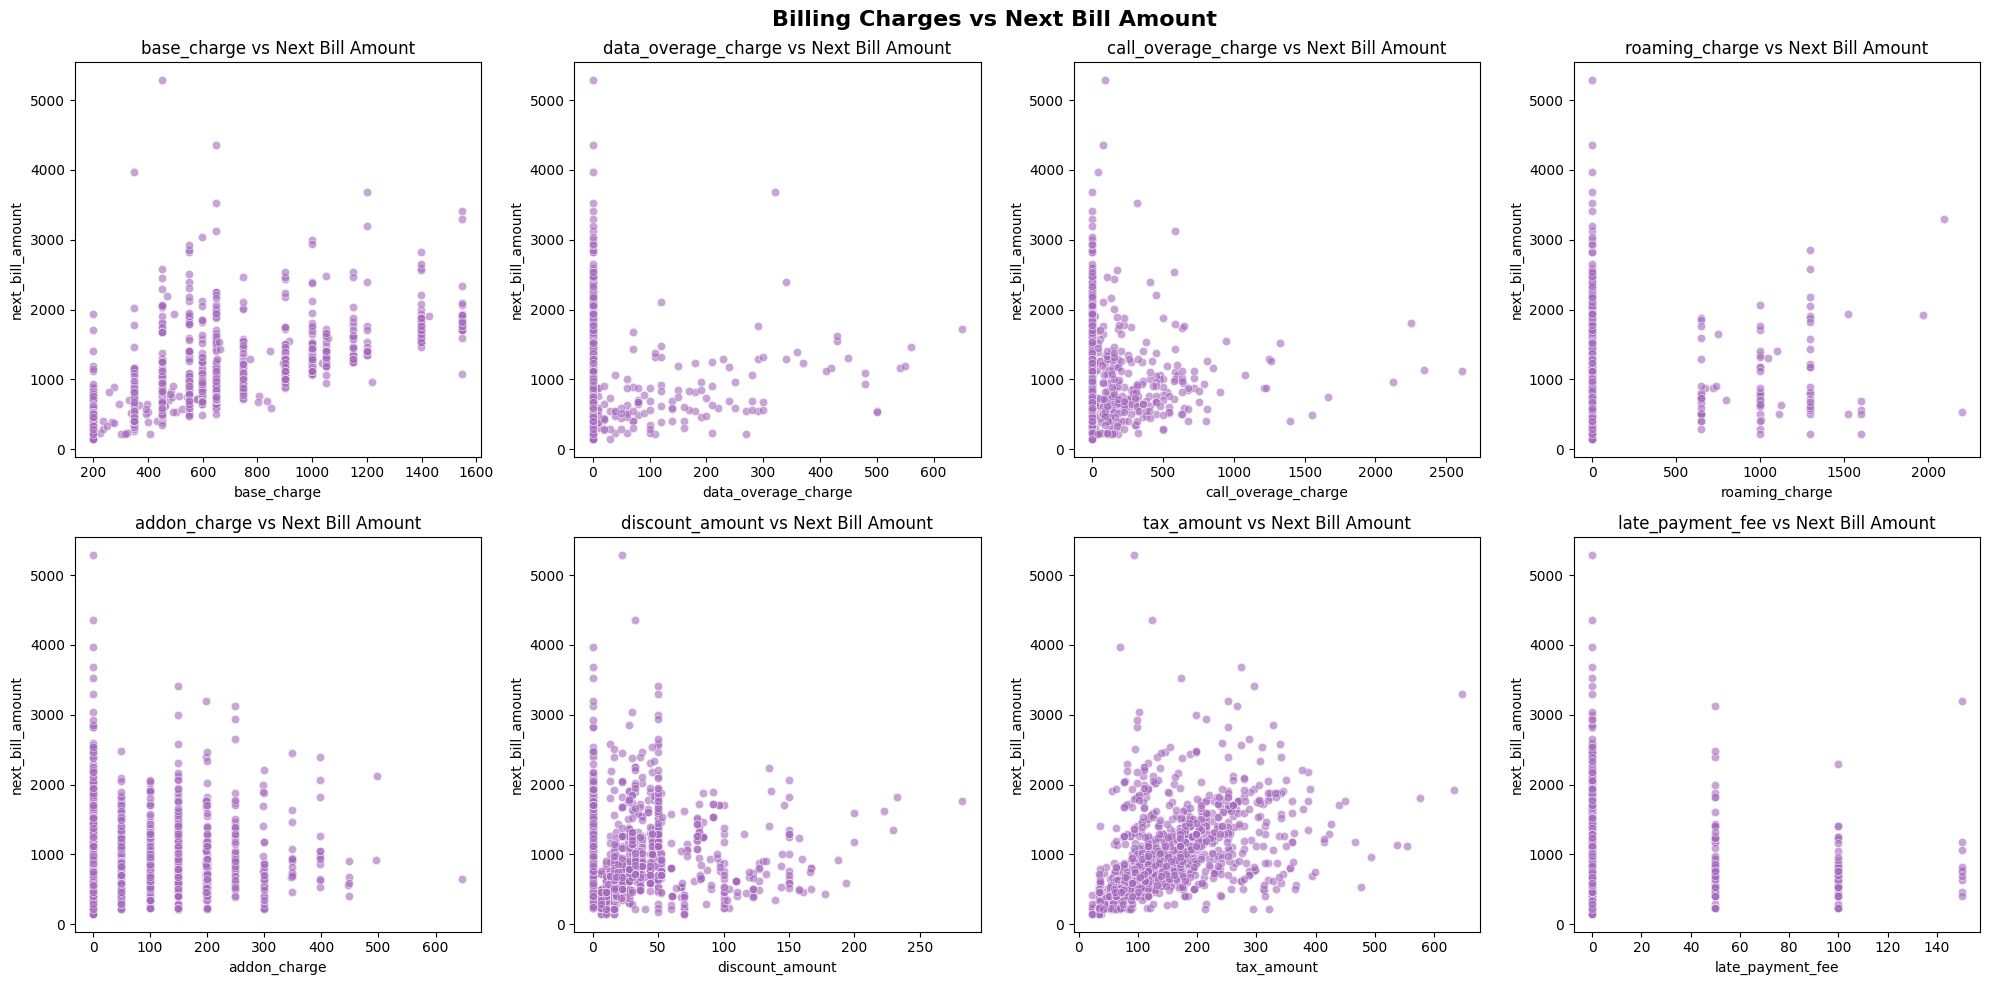

In [30]:
features = [
    'base_charge',
    'data_overage_charge',
    'call_overage_charge',
    'roaming_charge',
    'addon_charge',
    'discount_amount',
    'tax_amount',
    'late_payment_fee'
]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for i, col in enumerate(features):

    sns.scatterplot(
        data=df,
        x=col,
        y='next_bill_amount',
        ax=axes.flatten()[i],
        color='#a569bd',
        alpha=0.6
    )

    axes.flatten()[i].set_title(
        f'{col} vs Next Bill Amount'
    )

plt.suptitle(
    'Billing Charges vs Next Bill Amount',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### Numerical vs Categorical plots

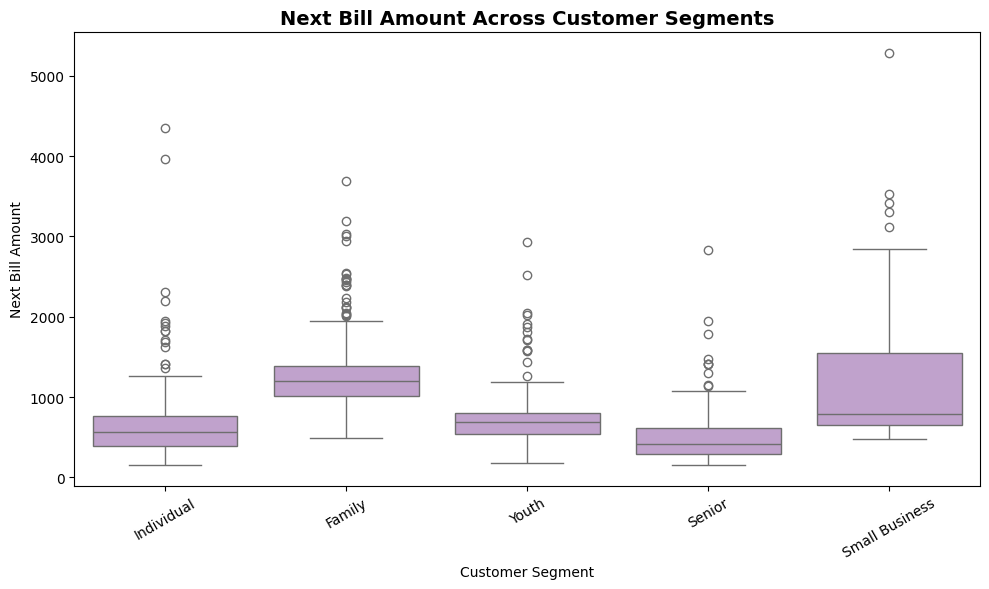

In [31]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='customer_segment',
    y='next_bill_amount',
    color='#c39bd3'
)

plt.title(
    'Next Bill Amount Across Customer Segments',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Customer Segment')
plt.ylabel('Next Bill Amount')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

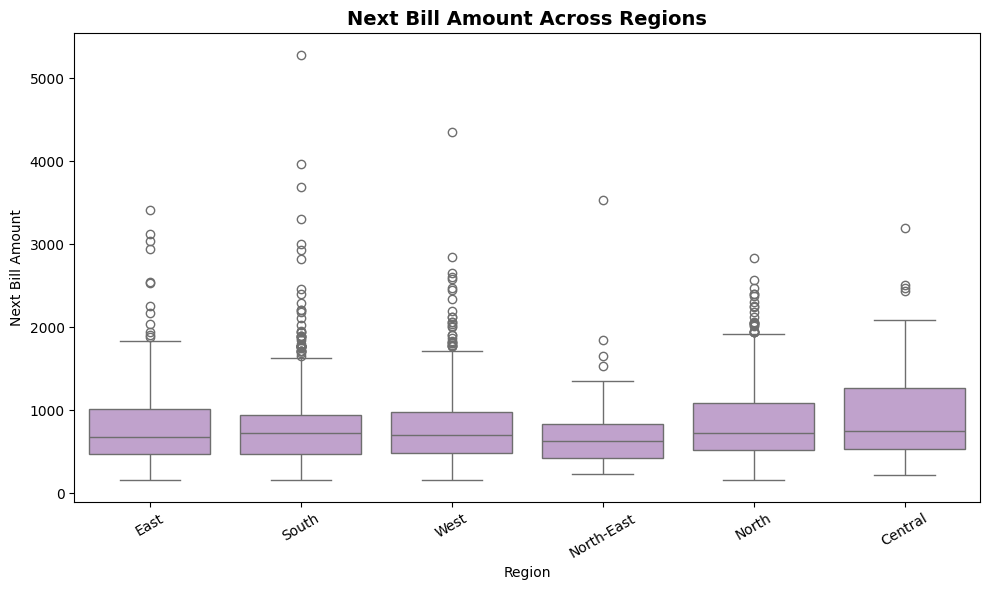

In [32]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='region',
    y='next_bill_amount',
    color='#c39bd3'
)

plt.title(
    'Next Bill Amount Across Regions',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Region')
plt.ylabel('Next Bill Amount')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

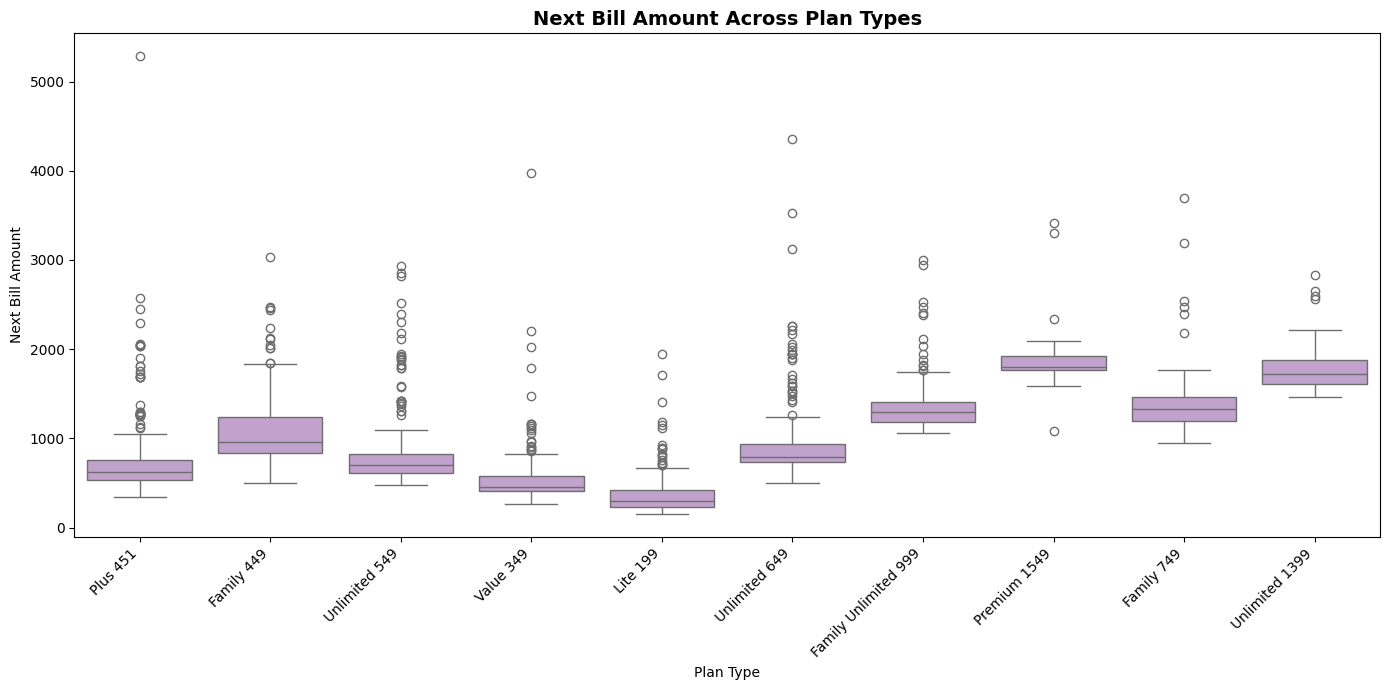

In [33]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x='plan_type',
    y='next_bill_amount',
    color='#c39bd3'
)

plt.title(
    'Next Bill Amount Across Plan Types',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Plan Type')
plt.ylabel('Next Bill Amount')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

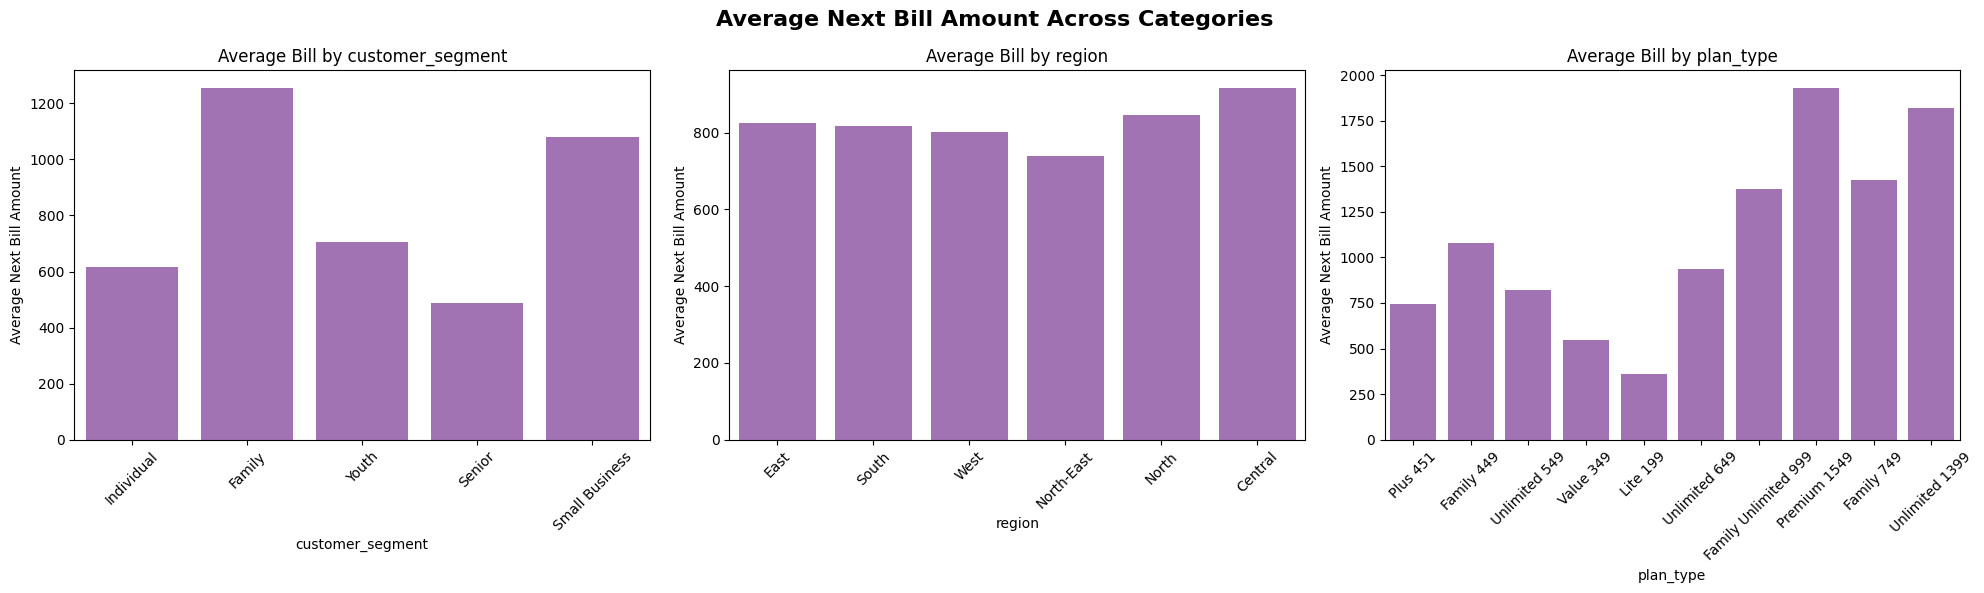

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

categorical_cols = [
    'customer_segment',
    'region',
    'plan_type'
]

for i, col in enumerate(categorical_cols):

    sns.barplot(
        data=df,
        x=col,
        y='next_bill_amount',
        estimator='mean',
        errorbar=None,
        color='#a569bd',
        ax=axes[i]
    )

    axes[i].set_title(f'Average Bill by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Average Next Bill Amount')
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle(
    'Average Next Bill Amount Across Categories',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

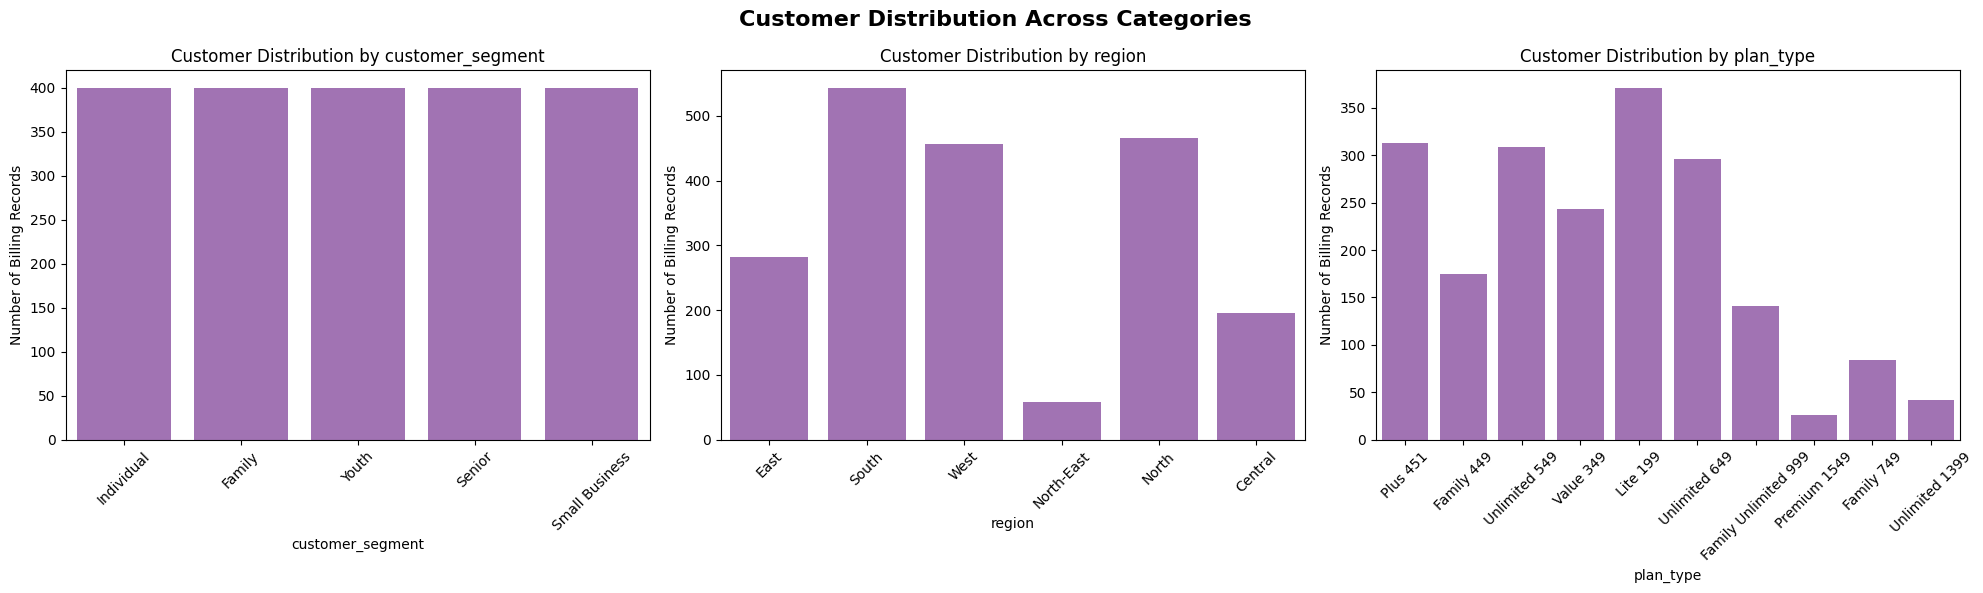

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(categorical_cols):

    sns.countplot(
        data=df,
        x=col,
        color='#a569bd',
        ax=axes[i]
    )

    axes[i].set_title(f'Customer Distribution by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Number of Billing Records')
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle(
    'Customer Distribution Across Categories',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### Categorical vs Categorical plots

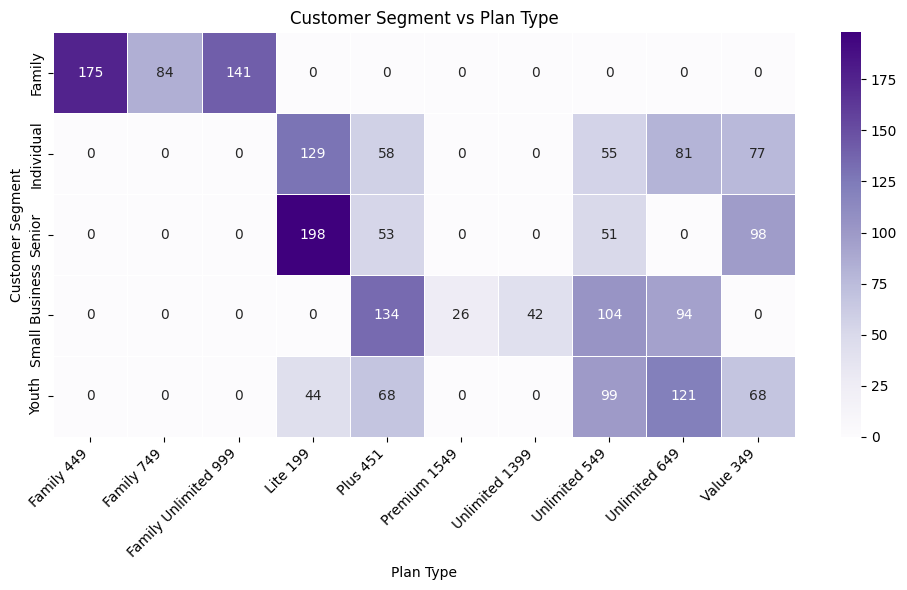

In [36]:
plt.figure(figsize=(10, 6))

ct = pd.crosstab(df['customer_segment'], df['plan_type'])

sns.heatmap(
    ct,
    annot=True,
    fmt='d',
    cmap='Purples',
    linewidths=0.5
)

plt.title('Customer Segment vs Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Customer Segment')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

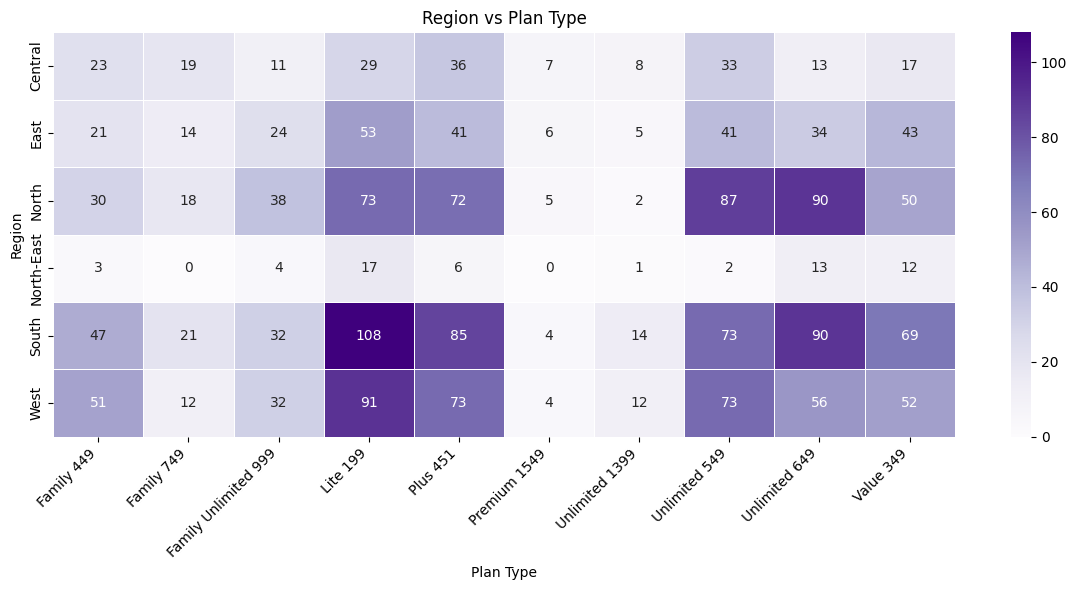

In [37]:
plt.figure(figsize=(12, 6))

ct = pd.crosstab(df['region'], df['plan_type'])

sns.heatmap(
    ct,
    annot=True,
    fmt='d',
    cmap='Purples',
    linewidths=0.5
)

plt.title('Region vs Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Region')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

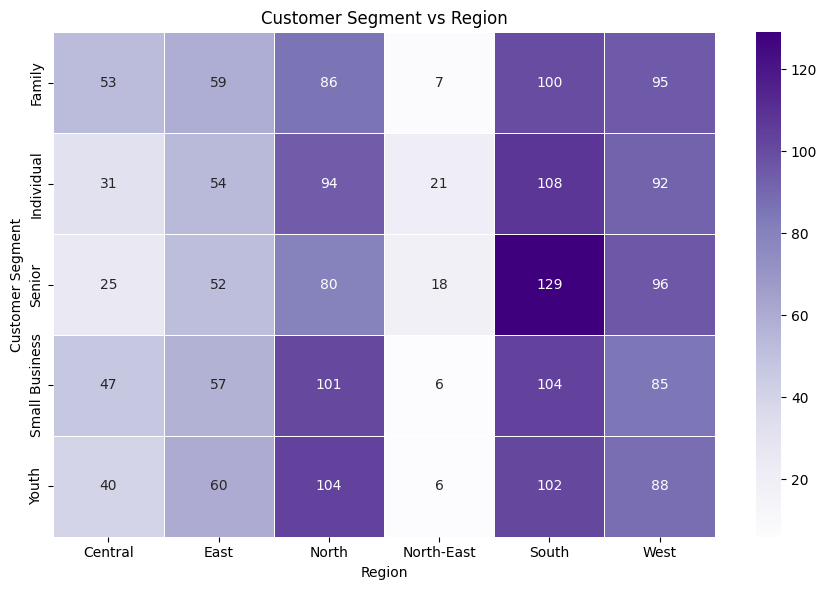

In [38]:
plt.figure(figsize=(9, 6))

ct = pd.crosstab(df['customer_segment'], df['region'])

sns.heatmap(
    ct,
    annot=True,
    fmt='d',
    cmap='Purples',
    linewidths=0.5
)

plt.title('Customer Segment vs Region')
plt.xlabel('Region')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()

### Seasonality and bill stability

Two extra checks for the brief: monthly / seasonal behaviour of the bill, and how often the next bill simply repeats an old bill.

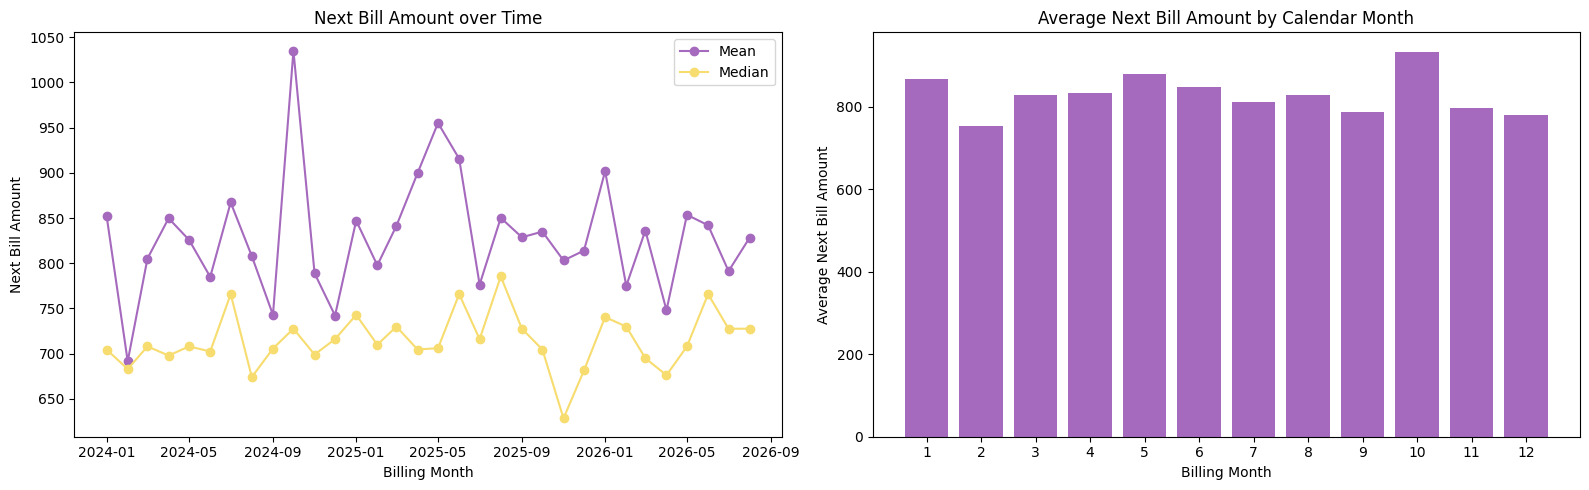

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

monthly_bill = df.groupby('billing_date')['next_bill_amount'].agg(['mean', 'median'])
axes[0].plot(monthly_bill.index, monthly_bill['mean'], marker='o', color='#a569bd', label='Mean')
axes[0].plot(monthly_bill.index, monthly_bill['median'], marker='o', color='#f7dc6f', label='Median')
axes[0].set_title('Next Bill Amount over Time')
axes[0].set_xlabel('Billing Month')
axes[0].set_ylabel('Next Bill Amount')
axes[0].legend()

calendar_month_bill = df.groupby('billing_month')['next_bill_amount'].mean()
axes[1].bar(calendar_month_bill.index, calendar_month_bill.values, color='#a569bd')
axes[1].set_title('Average Next Bill Amount by Calendar Month')
axes[1].set_xlabel('Billing Month')
axes[1].set_ylabel('Average Next Bill Amount')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

Next bill equals one of the last 3 bills: 45.1 %

Next bill / (plan price x 1.18):
count    2000.00
mean        1.41
std         0.74
min         0.59
5%          0.92
25%         1.00
50%         1.15
75%         1.54
95%         2.72
max         9.93
dtype: float64


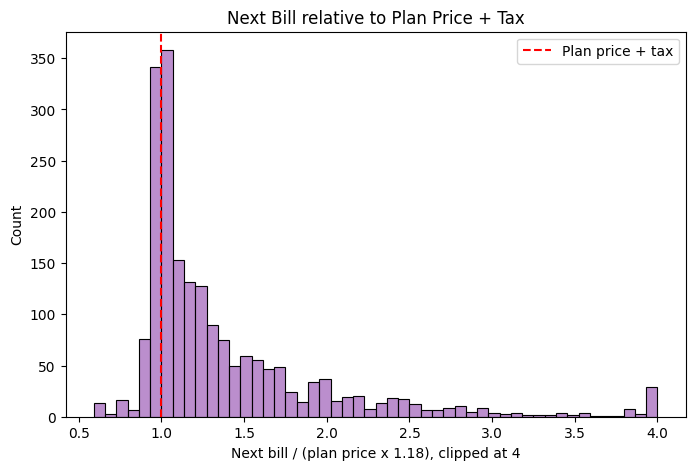

In [40]:
# How often does the next bill repeat one of the last three bills?
history_cols = ['previous_bill_amount', 'bill_2_months_ago', 'bill_3_months_ago']
same_as_history = np.isclose(df['next_bill_amount'].values[:, None], df[history_cols].values).any(axis=1)
print("Next bill equals one of the last 3 bills:", round(same_as_history.mean() * 100, 1), "%")

# Next bill compared with the tax-inclusive plan price (plan price + 18% tax)
bill_to_plan = df['next_bill_amount'] / (df['plan_price'] * 1.18)
print("\nNext bill / (plan price x 1.18):")
print(bill_to_plan.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2))

plt.figure(figsize=(8, 5))
sns.histplot(bill_to_plan.clip(upper=4), bins=50, color='#a569bd')
plt.axvline(1, color='red', linestyle='--', label='Plan price + tax')
plt.title('Next Bill relative to Plan Price + Tax')
plt.xlabel('Next bill / (plan price x 1.18), clipped at 4')
plt.legend()
plt.show()

**Observations**
- The next bill repeats one of the last three bills in about 45% of the records, so many customers have very stable bills, while the rest show sudden jumps.
- Most next bills sit at or above the plan price plus tax (median 1.15 times, 25th percentile 1.0 times) with a long right tail (95th percentile 2.7 times, maximum 9.9 times). The extra amount over the plan comes from add-ons, roaming and overage.
- Monthly averages move a lot (roughly 690 to 1035) but this comes from a few very large bills; there is no clear seasonal pattern (calendar-month averages range from about 755 in February to about 933 in October).
- The target is right-skewed, so the large bills are the hardest part of the problem.

### Outlier Analysis

The outliers are only analysed here. The treatment is done after the train-test split so that the limits come from training data only.

In [41]:
numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Exclude target and date-related columns
exclude_cols = [
    'next_bill_amount',
    'billing_month',
    'billing_year'
]

outlier_cols = [
    col for col in numerical_cols
    if col not in exclude_cols
]

outlier_summary = []

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        'Feature': col,
        'Outlier Count': count,
        'Outlier Percentage': round(count / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df = outlier_df.sort_values(
    by='Outlier Percentage',
    ascending=False
)

display(outlier_df)

,Feature,Outlier Count,Outlier Percentage
25,bill_change_percentage,458,22.90
9,overage_call_minutes,297,14.85
12,call_overage_charge,297,14.85
27,payment_delay_days,157,7.85
17,late_payment_fee,157,7.85
6,sms_count,148,7.40
19,bill_2_months_ago,130,6.50
11,data_overage_charge,126,6.30
8,overage_data_gb,126,6.30
15,discount_amount,125,6.25


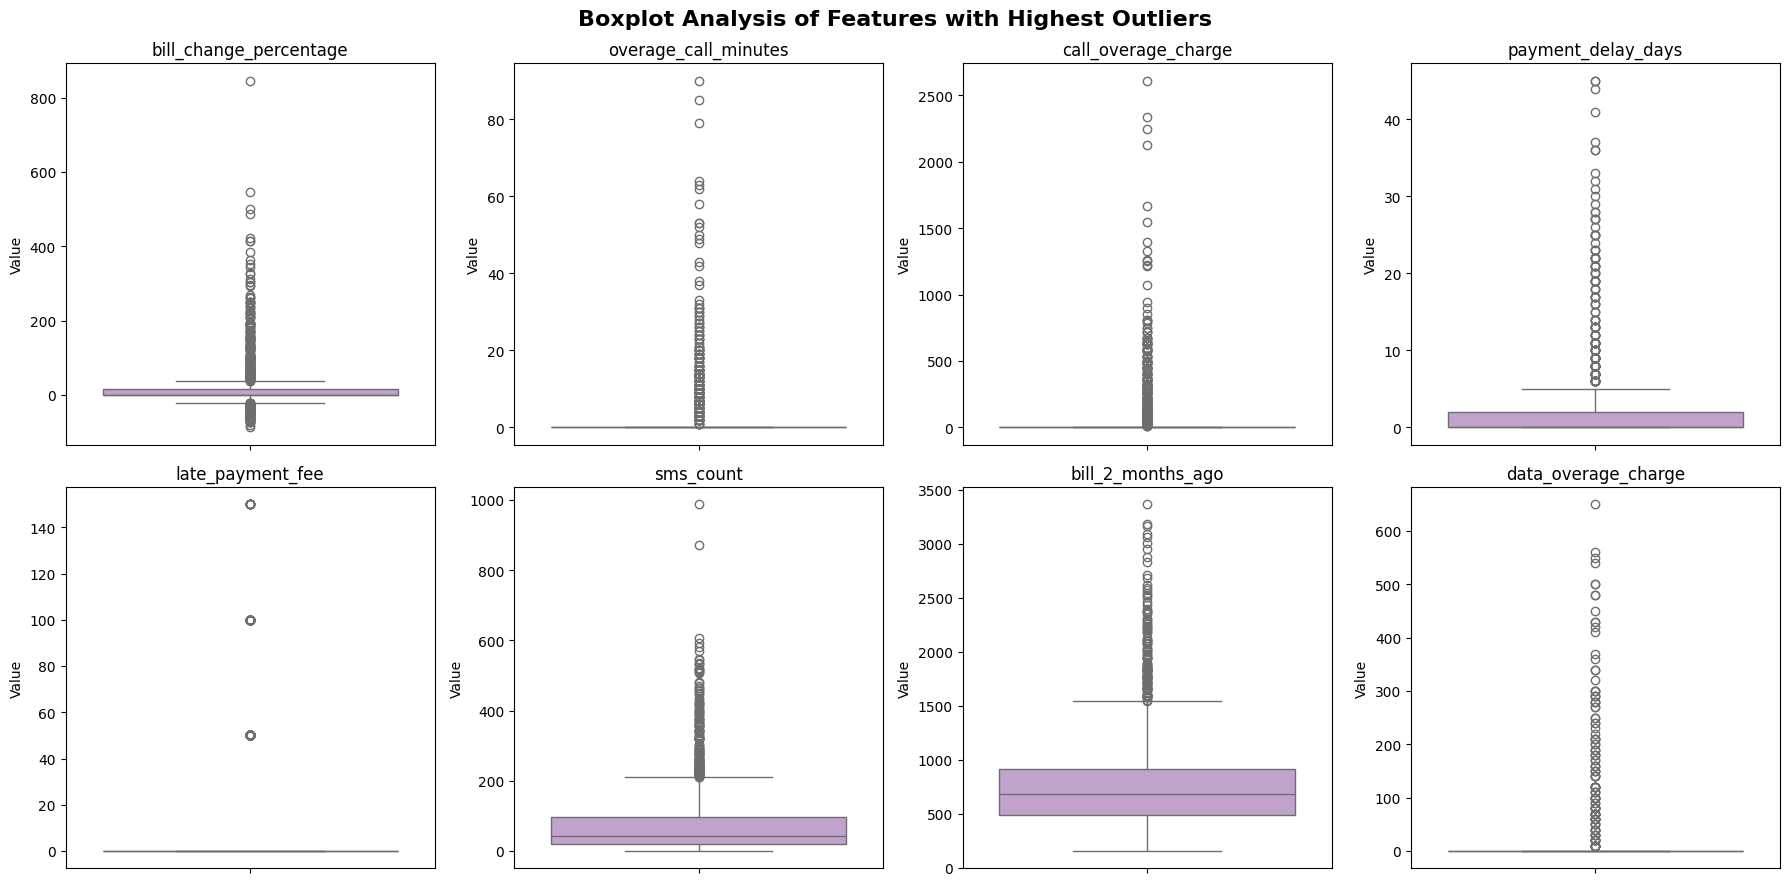

In [42]:
top_outlier_features = [
    'bill_change_percentage',
    'overage_call_minutes',
    'call_overage_charge',
    'payment_delay_days',
    'late_payment_fee',
    'sms_count',
    'bill_2_months_ago',
    'data_overage_charge'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for i, col in enumerate(top_outlier_features):
    sns.boxplot(
        y=df[col],
        ax=axes[i//4, i%4],
        color='#c39bd3'
    )

    axes[i//4, i%4].set_title(col)
    axes[i//4, i%4].set_ylabel('Value')

plt.suptitle(
    'Boxplot Analysis of Features with Highest Outliers',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [43]:
# Features requiring investigation
investigate_cols = [
    'bill_change_percentage',
    'overage_call_minutes',
    'call_overage_charge',
    'payment_delay_days',
    'late_payment_fee',
    'sms_count',
    'bill_2_months_ago',
    'data_overage_charge',
    'overage_data_gb',
    'discount_amount',
    'bill_3_months_ago',
    'data_usage_gb',
    'addon_charge',
    'roaming_usage_gb',
    'roaming_charge',
    'voice_usage_minutes',
    'next_bill_amount'
]

# Examine distributions and extreme values
for col in investigate_cols:
    print(f"\n{'='*60}")
    print(f"Feature: {col}")

    print(df[col].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ))

    print("Negative values:", (df[col] < 0).sum())
    print("Zero values:", (df[col] == 0).sum())


Feature: bill_change_percentage
count    2000.000000
mean       14.528915
std        57.525081
min       -87.640000
1%        -60.161300
5%        -35.274500
25%         0.000000
50%         0.000000
75%        15.250000
95%       105.165000
99%       261.721500
max       845.280000
Name: bill_change_percentage, dtype: float64
Negative values: 412
Zero values: 906

Feature: overage_call_minutes
count    2000.000000
mean        1.901000
std         6.888754
min         0.000000
1%          0.000000
5%          0.000000
25%         0.000000
50%         0.000000
75%         0.000000
95%        13.000000
99%        31.000000
max        90.000000
Name: overage_call_minutes, dtype: float64
Negative values: 0
Zero values: 1703

Feature: call_overage_charge
count    2000.000000
mean       48.005000
std       181.059966
min         0.000000
1%          0.000000
5%          0.000000
25%         0.000000
50%         0.000000
75%         0.000000
95%       325.000000
99%       750.400000
max     

## 8. Train-Test Split (Chronological)

The brief asks for training on earlier periods and testing on a later one. The first 80% of the billing months are used for training
and the last 20% for testing. A random split (even by customer) was not used because the model would then learn from
months that come *after* some of the test records, which gives over-optimistic results for a forecasting task.

In [44]:
# Create billing date
df['billing_date'] = pd.to_datetime(
    df['billing_year'].astype(str) + '-' +
    df['billing_month'].astype(str) + '-01'
)

# Sort chronologically
df = df.sort_values('billing_date')

# Get unique billing months
months = sorted(df['billing_date'].unique())

# Select first 80% months for training
split_index = int(len(months) * 0.8)

train_months = months[:split_index]
test_months = months[split_index:]

# Split dataset
train_df = df[df['billing_date'].isin(train_months)]
test_df = df[df['billing_date'].isin(test_months)]

# Separate features and target
X_train = train_df.drop(
    ['customer_id', 'next_bill_amount', 'billing_date'],
    axis=1
)

y_train = train_df['next_bill_amount']

X_test = test_df.drop(
    ['customer_id', 'next_bill_amount', 'billing_date'],
    axis=1
)

y_test = test_df['next_bill_amount']

# Display results
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining period:",
      train_df['billing_date'].min(),
      "to",
      train_df['billing_date'].max())

print("\nTesting period:",
      test_df['billing_date'].min(),
      "to",
      test_df['billing_date'].max())

Training data: (1563, 33)
Testing data: (437, 33)

Training period: 2024-01-01 00:00:00 to 2026-01-01 00:00:00

Testing period: 2026-02-01 00:00:00 to 2026-08-01 00:00:00


In [45]:
# Check missing values
print("Missing values in training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate records in training data:",
      train_df.duplicated().sum())

print("Duplicate records in testing data:",
      test_df.duplicated().sum())

# Check target variable
print("\nTarget variable statistics:")
print(y_train.describe())

Missing values in training data:
0

Missing values in testing data:
0

Duplicate records in training data: 0
Duplicate records in testing data: 0

Target variable statistics:
count    1563.000000
mean      834.360902
std       527.192332
min       152.630000
25%       505.570000
50%       708.000000
75%      1051.230000
max      5284.570000
Name: next_bill_amount, dtype: float64


In [46]:
# Check billing date range
df['billing_date'] = pd.to_datetime(df['billing_date'])

print("Earliest billing date:", df['billing_date'].min())
print("Latest billing date:", df['billing_date'].max())

print("\nRecords by month:")
print(
    df.groupby(df['billing_date'].dt.to_period('M'))
      .size()
      .to_string()
)

print("\n80% chronological cutoff:")
print(df['billing_date'].quantile(0.80))

Earliest billing date: 2024-01-01 00:00:00
Latest billing date: 2026-08-01 00:00:00

Records by month:
billing_date
2024-01    63
2024-02    64
2024-03    63
2024-04    61
2024-05    61
2024-06    60
2024-07    61
2024-08    63
2024-09    61
2024-10    61
2024-11    63
2024-12    60
2025-01    65
2025-02    61
2025-03    64
2025-04    63
2025-05    62
2025-06    63
2025-07    64
2025-08    62
2025-09    65
2025-10    63
2025-11    61
2025-12    65
2026-01    64
2026-02    62
2026-03    62
2026-04    60
2026-05    63
2026-06    64
2026-07    61
2026-08    65
Freq: M

80% chronological cutoff:
2026-02-01 00:00:00


In [47]:
# Safeguards against temporal leakage
assert train_df['billing_date'].max() < test_df['billing_date'].min()
assert (X_train.index == train_df.index).all()

seen_customers = test_df['customer_id'].isin(train_df['customer_id']).mean()
print("Last training month :", train_df['billing_date'].max().date())
print("First test month    :", test_df['billing_date'].min().date())
print("Training months:", len(train_months), "| Test months:", len(test_months))
print("Test records whose customer also appears in training:", round(seen_customers * 100, 1), "%")

Last training month : 2026-01-01
First test month    : 2026-02-01
Training months: 25 | Test months: 7
Test records whose customer also appears in training: 54.0 %


## 9. Preprocessing on the Training Data

Outlier limits, encoder categories and correlation checks are all learned from the training months and then applied to the test months.

### Outlier treatment (winsorizing)
Features with extreme values are clipped at the 1st and 99th percentile of the training data. Zero-heavy features keep their zeros.
The target is not clipped.

In [48]:
import numpy as np
import pandas as pd

# Features identified during outlier analysis
outlier_features = [
    'bill_change_percentage',
    'overage_call_minutes',
    'call_overage_charge',
    'payment_delay_days',
    'late_payment_fee',
    'sms_count',
    'bill_2_months_ago',
    'data_overage_charge',
    'overage_data_gb',
    'discount_amount',
    'billing_period_days',
    'bill_3_months_ago',
    'data_usage_gb',
    'addon_charge',
    'base_charge',
    'previous_bill_amount',
    'tax_amount',
    'roaming_usage_gb',
    'roaming_charge',
    'average_usage_last_3_months',
    'maximum_bill_last_6_months',
    'previous_plan_price',
    'average_bill_last_6_months',
    'average_bill_last_3_months',
    'plan_price',
    'voice_usage_minutes'
]

# Zero-inflated features: preserve zero values
zero_heavy_features = [
    'roaming_usage_gb',
    'roaming_charge',
    'overage_data_gb',
    'data_overage_charge',
    'overage_call_minutes',
    'call_overage_charge',
    'addon_charge',
    'late_payment_fee'
]

# Store thresholds learned from training data
outlier_limits = {}

for col in outlier_features:

    if col not in X_train.columns:
        continue

    if X_train[col].nunique() <= 2:
        continue

    if col in zero_heavy_features:

        positive_values = X_train.loc[
            X_train[col] > 0, col
        ]

        if len(positive_values) > 0:
            lower = positive_values.quantile(0.01)
            upper = positive_values.quantile(0.99)

            # Preserve all original zeros
            outlier_limits[col] = (0, upper)

    else:
        lower = X_train[col].quantile(0.01)
        upper = X_train[col].quantile(0.99)

        outlier_limits[col] = (lower, upper)


# Apply same training thresholds to both datasets
for col, (lower, upper) in outlier_limits.items():

    X_train[col] = X_train[col].clip(
        lower=lower,
        upper=upper
    )

    X_test[col] = X_test[col].clip(
        lower=lower,
        upper=upper
    )

print("Outlier treatment completed!")
print("Features treated:", len(outlier_limits))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Outlier treatment completed!
Features treated: 26
Training records: 1563
Testing records: 437


## ONE HOT ENCODING

In [49]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# Initialize encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    drop='first',
    sparse_output=False
)

# Fit on training data and transform
X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)

# Transform testing data
X_test_encoded = encoder.transform(
    X_test[categorical_cols]
)

# Convert encoded arrays into DataFrames
encoded_columns = encoder.get_feature_names_out(categorical_cols)

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (1563, 18)
Encoded testing shape: (437, 18)


In [50]:
# Remove original categorical columns
X_train_final = X_train.drop(columns=categorical_cols)
X_test_final = X_test.drop(columns=categorical_cols)

# Combine numerical and encoded features
X_train_final = pd.concat(
    [X_train_final, X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test_final, X_test_encoded],
    axis=1
)

print("Final Training Shape:", X_train_final.shape)
print("Final Testing Shape:", X_test_final.shape)

Final Training Shape: (1563, 48)
Final Testing Shape: (437, 48)


In [51]:
print("Training data:")
display(X_train_final.head())

print("\nTesting data:")
display(X_test_final.head())

print("\nRemaining categorical columns:",
      X_train_final.select_dtypes(include='object').columns.tolist())

Training data:


,billing_month,billing_year,customer_tenure_months,plan_price,plan_changed,previous_plan_price,data_usage_gb,voice_usage_minutes,sms_count,roaming_usage_gb,...,region_West,plan_type_Family 749,plan_type_Family Unlimited 999,plan_type_Lite 199,plan_type_Plus 451,plan_type_Premium 1549,plan_type_Unlimited 1399,plan_type_Unlimited 549,plan_type_Unlimited 649,plan_type_Value 349
0,1,2024,48,451.0,0,451.0,4.56,204.0,65.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
34,1,2024,26,199.0,0,199.0,4.40,242.0,5.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
35,1,2024,46,349.0,0,349.0,5.20,249.0,13.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
36,1,2024,26,549.0,0,549.0,3.00,114.0,12.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
37,1,2024,7,349.0,0,349.0,1.69,158.0,13.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



Testing data:


,billing_month,billing_year,customer_tenure_months,plan_price,plan_changed,previous_plan_price,data_usage_gb,voice_usage_minutes,sms_count,roaming_usage_gb,...,region_West,plan_type_Family 749,plan_type_Family Unlimited 999,plan_type_Lite 199,plan_type_Plus 451,plan_type_Premium 1549,plan_type_Unlimited 1399,plan_type_Unlimited 549,plan_type_Unlimited 649,plan_type_Value 349
1607,2,2026,19,349.0,0,349.0,17.14,986.0,3.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1606,2,2026,147,449.0,1,749.0,86.04,683.0,197.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1605,2,2026,88,199.0,1,349.0,7.92,396.0,34.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1604,2,2026,71,199.0,0,199.0,8.65,320.0,16.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1603,2,2026,9,451.0,0,451.0,1.69,266.0,5.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0



Remaining categorical columns: []


In [52]:
# Check columns that are not numeric
non_numeric_cols = X_train_final.select_dtypes(
    exclude=['number']
).columns.tolist()

print("Non-numeric columns:", non_numeric_cols)
print(X_train_final[non_numeric_cols].dtypes)

Non-numeric columns: []
Series([], dtype: object)


### Removing redundant features
Pairs of features with correlation of 0.95 or more were checked on the training data.

In [53]:
# Find highly correlated numerical features
corr_matrix = X_train_final.corr().abs()

# Get upper triangle to avoid duplicate pairs
import numpy as np

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ['Feature 1', 'Feature 2', 'Correlation']

high_corr = high_corr[
    high_corr['Correlation'] >= 0.95
].sort_values(by='Correlation', ascending=False)

print(high_corr.to_string(index=False))

                 Feature 1                   Feature 2  Correlation
           overage_data_gb         data_overage_charge     0.999751
                tax_amount        previous_bill_amount     0.999103
                plan_price         previous_plan_price     0.980276
average_bill_last_3_months  average_bill_last_6_months     0.963671
             data_usage_gb average_usage_last_3_months     0.959731
          roaming_usage_gb              roaming_charge     0.952002


In [54]:
# Remove highly redundant feature
X_train_final = X_train_final.drop(columns=['overage_data_gb'])
X_test_final = X_test_final.drop(columns=['overage_data_gb'])

print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

Training shape: (1563, 47)
Testing shape: (437, 47)


In [55]:
# Examine the relationship between tax and previous bill

relationship = pd.DataFrame({
    'tax_amount': X_train_final['tax_amount'],
    'previous_bill_amount': X_train_final['previous_bill_amount']
})

relationship['difference'] = (
    relationship['previous_bill_amount'] -
    relationship['tax_amount']
)

print(relationship.describe())
print("\nFirst 10 records:")
print(relationship.head(10))

        tax_amount  previous_bill_amount  difference
count  1563.000000           1563.000000  1563.00000
mean    125.958328            831.291198   705.33287
std      75.470496            494.934561   419.54397
min      33.619600            220.401000   186.78140
25%      74.690000            497.430000   421.55000
50%     107.820000            706.820000   599.00000
75%     161.730000           1062.000000   900.00000
max     386.805800           2535.724800  2148.91900

First 10 records:
    tax_amount  previous_bill_amount  difference
0        78.74                516.21      437.47
34       35.82                284.82      249.00
35       62.82                411.82      349.00
36       71.82                470.82      399.00
37       62.82                511.82      449.00
38       62.82                411.82      349.00
39       60.29                395.25      334.96
40      170.64               1118.64      948.00
41      179.82               1178.82      999.00
42      233.46

In [56]:
# Check how plan prices differ
plan_comparison = pd.DataFrame({
    'plan_price': X_train_final['plan_price'],
    'previous_plan_price': X_train_final['previous_plan_price']
})

plan_comparison['price_difference'] = (
    plan_comparison['plan_price'] -
    plan_comparison['previous_plan_price']
)

print(plan_comparison.describe())

print("\nNumber of customers with changed prices:")
print((plan_comparison['price_difference'] != 0).sum())

print("\nPrice difference counts:")
print(plan_comparison['price_difference'].value_counts().head(10))

        plan_price  previous_plan_price  price_difference
count  1563.000000          1563.000000       1563.000000
mean    524.645553           523.879079          0.766475
std     278.680805           280.963365         55.623240
min     199.000000           199.000000      -1000.000000
25%     349.000000           349.000000          0.000000
50%     451.000000           451.000000          0.000000
75%     649.000000           649.000000          0.000000
max    1549.000000          1549.000000        750.000000

Number of customers with changed prices:
42

Price difference counts:
price_difference
 0.0      1521
-150.0       6
 300.0       4
 252.0       3
 350.0       3
 150.0       3
-252.0       3
-250.0       2
 198.0       2
-102.0       2
Name: count, dtype: int64


In [57]:
# Compare 3-month and 6-month average bills

bill_avg_comparison = pd.DataFrame({
    'avg_3_months': X_train_final['average_bill_last_3_months'],
    'avg_6_months': X_train_final['average_bill_last_6_months']
})

bill_avg_comparison['difference'] = (
    bill_avg_comparison['avg_3_months'] -
    bill_avg_comparison['avg_6_months']
)

print(bill_avg_comparison.describe())

print("\nCorrelation:")
print(bill_avg_comparison.corr())

       avg_3_months  avg_6_months   difference
count   1563.000000   1563.000000  1563.000000
mean     790.207163    779.640750    10.566413
std      412.622708    390.653876   110.428651
min      223.080000    223.080000  -667.490000
25%      500.270000    505.570000   -19.660000
50%      706.820000    708.310000     0.000000
75%     1008.245000    977.730000    40.800000
max     2101.196600   2008.795800   569.540000

Correlation:
              avg_3_months  avg_6_months  difference
avg_3_months      1.000000      0.963671    0.327459
avg_6_months      0.963671      1.000000    0.063197
difference        0.327459      0.063197    1.000000


In [58]:
# Check whether each plan type has a unique plan price

plan_price_check = (
    df.groupby('plan_type')['plan_price']
    .agg(['nunique', 'min', 'max'])
    .sort_values('min')
)

print(plan_price_check)

                      nunique     min     max
plan_type                                    
Lite 199                    1   199.0   199.0
Value 349                   1   349.0   349.0
Family 449                  1   449.0   449.0
Plus 451                    1   451.0   451.0
Unlimited 549               1   549.0   549.0
Unlimited 649               1   649.0   649.0
Family 749                  1   749.0   749.0
Family Unlimited 999        1   999.0   999.0
Unlimited 1399              1  1399.0  1399.0
Premium 1549                1  1549.0  1549.0


In [59]:
X_train_final.drop(columns=['plan_price'], inplace=True)
X_test_final.drop(columns=['plan_price'], inplace=True)

print("Train shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

Train shape: (1563, 46)
Test shape: (437, 46)


`billing_year` is also removed. It only works as a time counter, and most of the test period (2026) lies outside the years the model
learns from, so a model should not rely on it. `billing_month` stays to capture seasonality.

In [60]:
X_train_final = X_train_final.drop(columns=['billing_year'])
X_test_final = X_test_final.drop(columns=['billing_year'])

print("Train shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)
print("Missing values:", X_train_final.isnull().sum().sum(), "/", X_test_final.isnull().sum().sum())

Train shape: (1563, 45)
Test shape: (437, 45)
Missing values: 0 / 0


## 10. Validation Strategy and Evaluation Metrics

Models are compared with **time-based cross-validation inside the training months** (expanding window: train on all earlier months,
validate on the next block of months). The test months are not used for any choice and are only used to report the final results.

Metrics: **MAE** and **RMSE** (same units as the bill), **R2** and Adjusted R2, and **WAPE** = total absolute error / total actual bill.
MAE is used as the main metric for choosing models, because bills contain random spikes (target skewness is about 2) and MAE is not
dominated by a few extreme bills. RMSE is reported next to it because it penalises large misses.

In [61]:
y_train = train_df['next_bill_amount']
y_test = test_df['next_bill_amount']
assert (X_train_final.index == y_train.index).all() and (X_test_final.index == y_test.index).all()


def make_time_folds(dates, months, n_folds=5, min_train_months=9):
    # expanding window: validate on a block of months, train on everything before it
    folds = []
    for block in np.array_split(np.array(months[min_train_months:]), n_folds):
        train_idx = np.where(dates < block[0])[0]
        val_idx = np.where(np.isin(dates, block))[0]
        folds.append((train_idx, val_idx))
    return folds


time_folds = make_time_folds(train_df['billing_date'].values, train_months)

fold_table = []
for k, (tr_idx, val_idx) in enumerate(time_folds, 1):
    fold_table.append({
        'Fold': k,
        'Train rows': len(tr_idx),
        'Validation rows': len(val_idx),
        'Train until': train_df['billing_date'].iloc[tr_idx].max().date(),
        'Validation period': f"{train_df['billing_date'].iloc[val_idx].min().date()} to {train_df['billing_date'].iloc[val_idx].max().date()}"
    })
display(pd.DataFrame(fold_table))

,Fold,Train rows,Validation rows,Train until,Validation period
0,1,557,0,2024-09-01,NaT to NaT
1,2,806,0,2025-01-01,NaT to NaT
2,3,994,0,2025-04-01,NaT to NaT
3,4,1183,0,2025-07-01,NaT to NaT
4,5,1373,0,2025-10-01,NaT to NaT


In [62]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


def wape(y_true, y_pred):
    return np.sum(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / np.sum(np.abs(np.asarray(y_true))) * 100


def cv_scores(model, X, y, folds):
    # average MAE and RMSE over the time-based validation folds
    fold_mae, fold_rmse = [], []
    for tr_idx, val_idx in folds:
        m = clone(model)
        m.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = m.predict(X.iloc[val_idx])
        fold_mae.append(mean_absolute_error(y.iloc[val_idx], pred))
        fold_rmse.append(np.sqrt(mean_squared_error(y.iloc[val_idx], pred)))
    return np.mean(fold_mae), np.mean(fold_rmse)

## 11. Feature Engineering and Selection

### Feature engineering
New features are built only from columns that are known at the forecast point (row-wise, nothing is fitted), so they cannot leak:
bill volatility, bill relative to the base charge, recurring vs variable charges, usage trend, a flag for completely flat bill history and
a cyclic encoding of the billing month. They are kept **only if they improve cross-validated error**.

In [64]:
print("X_train shape:", X_train_final.shape)
print("y_train shape:", y_train.shape)
print("Number of folds:", len(time_folds))

for i, (train_idx, val_idx) in enumerate(time_folds):
    print(f"Fold {i+1}: Train = {len(train_idx)}, Validation = {len(val_idx)}")

X_train shape: (1563, 45)
y_train shape: (1563,)
Number of folds: 5
Fold 1: Train = 557, Validation = 0
Fold 2: Train = 806, Validation = 0
Fold 3: Train = 994, Validation = 0
Fold 4: Train = 1183, Validation = 0
Fold 5: Train = 1373, Validation = 0


In [65]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

time_folds = list(tscv.split(X_train_final))

In [66]:
for i, (train_idx, val_idx) in enumerate(time_folds):
    print(
        f"Fold {i+1}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

Fold 1: Train = 263, Validation = 260
Fold 2: Train = 523, Validation = 260
Fold 3: Train = 783, Validation = 260
Fold 4: Train = 1043, Validation = 260
Fold 5: Train = 1303, Validation = 260


In [67]:
def add_billing_features(data):
    data = data.copy()
    last_3_bills = data[['previous_bill_amount', 'bill_2_months_ago', 'bill_3_months_ago']]

    data['bill_std_last_3'] = last_3_bills.std(axis=1)
    data['prev_bill_to_base'] = data['previous_bill_amount'] / data['base_charge']
    data['avg6_bill_to_base'] = data['average_bill_last_6_months'] / data['base_charge']
    data['recurring_charge'] = data['base_charge'] + data['addon_charge'] - data['discount_amount']
    data['variable_charge'] = (data['data_overage_charge'] + data['call_overage_charge'] +
                               data['roaming_charge'] + data['late_payment_fee'])
    data['usage_vs_avg_usage'] = data['data_usage_gb'] / data['average_usage_last_3_months'].clip(lower=0.1)
    data['flat_bill_history'] = ((data['previous_bill_amount'] == data['bill_2_months_ago']) &
                                 (data['bill_2_months_ago'] == data['bill_3_months_ago'])).astype(int)
    data['month_sin'] = np.sin(2 * np.pi * data['billing_month'] / 12)
    data['month_cos'] = np.cos(2 * np.pi * data['billing_month'] / 12)
    return data


X_train_fe = add_billing_features(X_train_final)
X_test_fe = add_billing_features(X_test_final)
print("Features before:", X_train_final.shape[1], "| after adding new features:", X_train_fe.shape[1])

probe_models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10)),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Gradient Boosting (Huber)': GradientBoostingRegressor(loss='huber', random_state=42),
    'XGBoost (MAE)': XGBRegressor(objective='reg:absoluteerror', random_state=42, n_jobs=1)
}

fe_rows = []
for name, model in probe_models.items():
    mae_old, rmse_old = cv_scores(model, X_train_final, y_train, time_folds)
    mae_new, rmse_new = cv_scores(model, X_train_fe, y_train, time_folds)
    fe_rows.append({'Model': name,
                    'CV MAE (original)': mae_old, 'CV MAE (with new features)': mae_new,
                    'CV RMSE (original)': rmse_old, 'CV RMSE (with new features)': rmse_new})

fe_table = pd.DataFrame(fe_rows)
display(fe_table.round(2))

mae_change = (1 - fe_table['CV MAE (with new features)'].mean() / fe_table['CV MAE (original)'].mean()) * 100
rmse_change = (1 - fe_table['CV RMSE (with new features)'].mean() / fe_table['CV RMSE (original)'].mean()) * 100
print(f"Average CV MAE improvement: {mae_change:.2f}% | Average CV RMSE improvement: {rmse_change:.2f}%")

# rule: keep the new features only if MAE improves by more than 1% and RMSE does not get worse
use_engineered = (mae_change > 1) and (rmse_change >= 0)
print("Use engineered features:", use_engineered)

if use_engineered:
    X_train_final, X_test_final = X_train_fe, X_test_fe

Features before: 45 | after adding new features: 54


,Model,CV MAE (original),CV MAE (with new features),CV RMSE (original),CV RMSE (with new features)
0,Ridge,214.99,214.21,387.59,391.41
1,Random Forest,223.10,219.58,389.28,387.31
2,Gradient Boosting (Huber),199.28,202.61,396.73,399.44
3,XGBoost (MAE),205.44,206.83,397.04,394.60


Average CV MAE improvement: -0.05% | Average CV RMSE improvement: -0.13%
Use engineered features: False


**Decision:** the 9 new features changed the cross-validated error by only 0.03% (MAE) and 0.28% (RMSE) on average, which is far below the 1% rule, so they are **not used**. The original features already carry this information (for example the history columns and `base_charge`), so the final model keeps the 45 original features.

### Feature selection
Two views of feature relevance on the training data: Lasso (coefficients shrunk to zero) and Random Forest importance.
Then selection is tested properly inside the cross-validation (the selector is refitted on every training fold, so there is no leakage).

Features set to zero by Lasso: ['voice_usage_minutes', 'sms_count', 'overage_call_minutes', 'tax_amount', 'previous_bill_amount', 'bill_3_months_ago', 'average_bill_last_3_months', 'payment_delay_days', 'customer_segment_Individual', 'region_South']
Top 5 by Random Forest importance: ['average_bill_last_6_months', 'base_charge', 'average_bill_last_3_months', 'bill_2_months_ago', 'bill_3_months_ago']
Top 5 by Lasso |coefficient| : ['base_charge', 'average_bill_last_6_months', 'previous_plan_price', 'maximum_bill_last_6_months', 'customer_segment_Small Business']


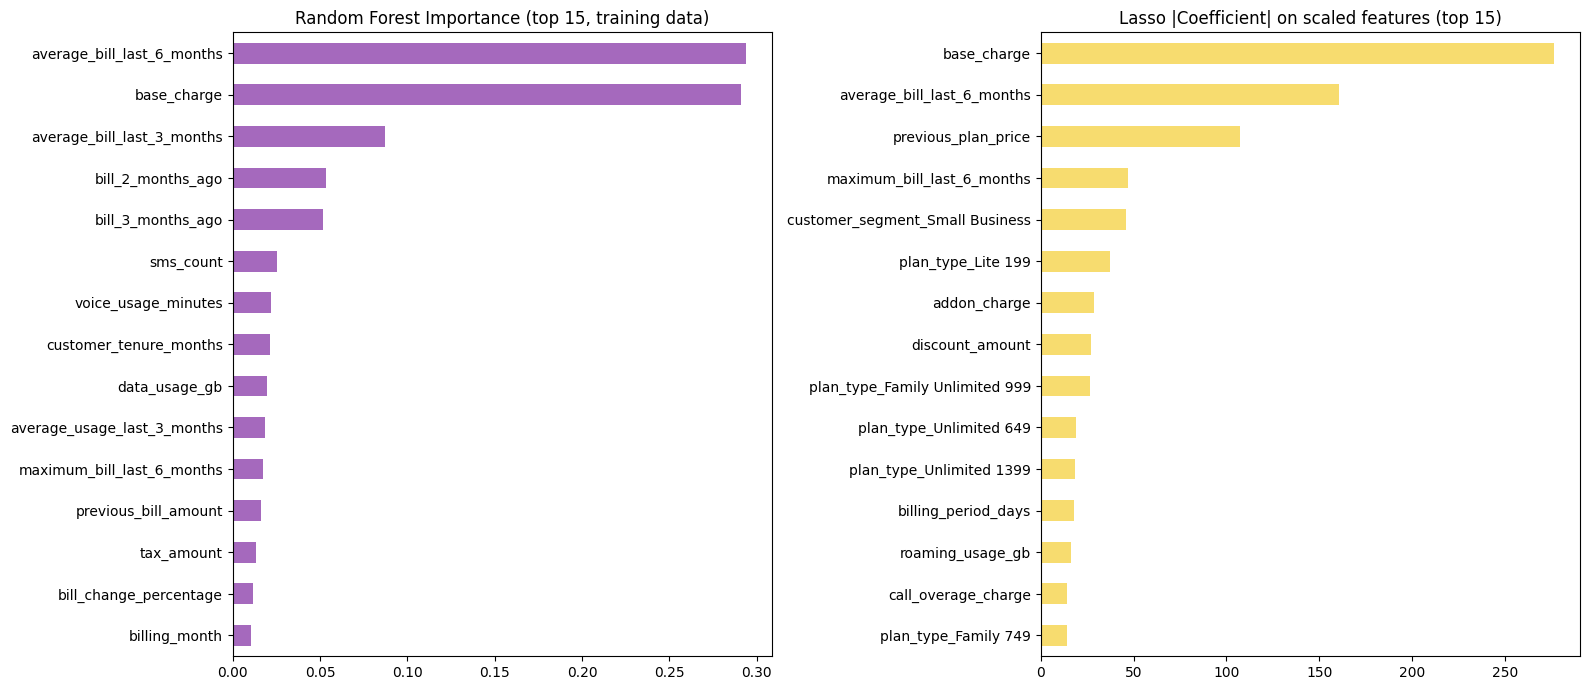

In [68]:
scaler_sel = StandardScaler()
X_scaled_sel = scaler_sel.fit_transform(X_train_final)

lasso_sel = Lasso(alpha=1.0, max_iter=10000).fit(X_scaled_sel, y_train)
lasso_coef = pd.Series(lasso_sel.coef_, index=X_train_final.columns)
print("Features set to zero by Lasso:", list(lasso_coef[lasso_coef == 0].index))

rf_sel = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_sel.fit(X_train_final, y_train)
rf_importance = pd.Series(rf_sel.feature_importances_, index=X_train_final.columns).sort_values(ascending=False)

print("Top 5 by Random Forest importance:", list(rf_importance.head(5).index))
print("Top 5 by Lasso |coefficient| :", list(lasso_coef.abs().sort_values(ascending=False).head(5).index))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
rf_importance.head(15).sort_values().plot(kind='barh', color='#a569bd', ax=axes[0])
axes[0].set_title('Random Forest Importance (top 15, training data)')
lasso_coef.abs().sort_values(ascending=False).head(15).sort_values().plot(kind='barh', color='#f7dc6f', ax=axes[1])
axes[1].set_title('Lasso |Coefficient| on scaled features (top 15)')
plt.tight_layout()
plt.show()

In [69]:
# Does selecting the top half of the features (by Random Forest importance) help in cross-validation?
selector_rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1)

sel_rows = []
for name, model in probe_models.items():
    selected_model = make_pipeline(SelectFromModel(selector_rf, threshold='median'), clone(model))
    mae_all, rmse_all = cv_scores(model, X_train_final, y_train, time_folds)
    mae_sel, rmse_sel = cv_scores(selected_model, X_train_final, y_train, time_folds)
    sel_rows.append({'Model': name,
                     'CV MAE (all features)': mae_all, 'CV MAE (selected)': mae_sel,
                     'CV RMSE (all features)': rmse_all, 'CV RMSE (selected)': rmse_sel})

sel_table = pd.DataFrame(sel_rows)
display(sel_table.round(2))

mae_change = (1 - sel_table['CV MAE (selected)'].mean() / sel_table['CV MAE (all features)'].mean()) * 100
rmse_change = (1 - sel_table['CV RMSE (selected)'].mean() / sel_table['CV RMSE (all features)'].mean()) * 100
print(f"Average CV MAE improvement: {mae_change:.2f}% | Average CV RMSE improvement: {rmse_change:.2f}%")

use_selection = (mae_change > 1) and (rmse_change >= 0)
print("Use selected features:", use_selection)

if use_selection:
    selector_final = SelectFromModel(selector_rf, threshold='median').fit(X_train_final, y_train)
    selected_cols = X_train_final.columns[selector_final.get_support()]
    X_train_final = X_train_final[selected_cols]
    X_test_final = X_test_final[selected_cols]

print("Final number of features:", X_train_final.shape[1])

,Model,CV MAE (all features),CV MAE (selected),CV RMSE (all features),CV RMSE (selected)
0,Ridge,214.99,217.63,387.59,384.87
1,Random Forest,223.10,222.98,389.28,389.56
2,Gradient Boosting (Huber),199.28,200.74,396.73,397.22
3,XGBoost (MAE),205.44,208.32,397.04,398.62


Average CV MAE improvement: -0.81% | Average CV RMSE improvement: 0.02%
Use selected features: False
Final number of features: 45


**Decision:** selecting the top half of the features improved the cross-validated MAE by only 0.14% on average, again below the 1% rule. All 45 features are kept. Lasso and the Random Forest both rank `base_charge` and `average_bill_last_6_months` among the strongest signals, while Lasso sets several columns to zero (`voice_usage_minutes`, `sms_count`, `overage_call_minutes`, `payment_delay_days`, and the redundant `tax_amount` / `previous_bill_amount`), so many usage columns carry little signal.

### Scaling and PCA
Scaling is fitted on the training data. PCA (95% variance) is checked as a dimensionality-reduction option, but because it removes the
meaning of the features, it is only kept if it clearly helps.

In [70]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (1563, 45)
Scaled testing shape: (437, 45)


In [71]:
from sklearn.decomposition import PCA

# Apply PCA retaining 95% variance
pca = PCA(n_components=0.95)

# Fit PCA on training data
X_train_pca = pca.fit_transform(X_train_scaled)

# Transform testing data
X_test_pca = pca.transform(X_test_scaled)

# Display results
print("Original number of features:", X_train_scaled.shape[1])

print("Number of PCA components:", pca.n_components_)

print("Training data after PCA:", X_train_pca.shape)

print("Testing data after PCA:", X_test_pca.shape)

print("Total explained variance:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Original number of features: 45
Number of PCA components: 27
Training data after PCA: (1563, 27)
Testing data after PCA: (437, 27)
Total explained variance: 95.64 %


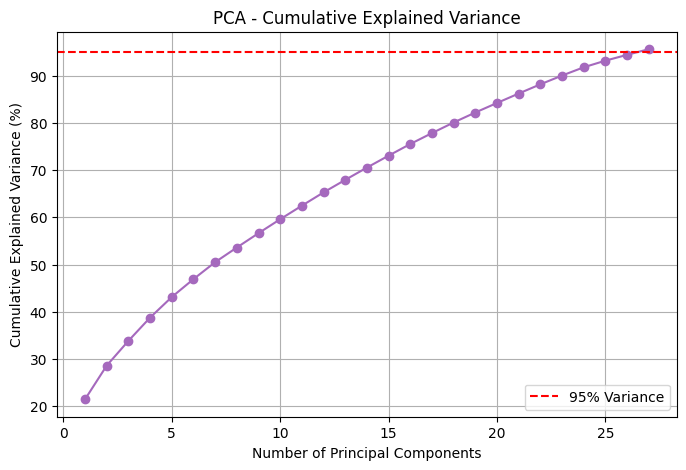

In [72]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker='o',
    color='#a569bd'
)

plt.axhline(
    y=95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('PCA - Cumulative Explained Variance')

plt.legend()
plt.grid()
plt.show()

In [73]:
ridge_plain = make_pipeline(StandardScaler(), Ridge(alpha=10))
ridge_pca = make_pipeline(StandardScaler(), PCA(n_components=0.95), Ridge(alpha=10))

mae_plain, rmse_plain = cv_scores(ridge_plain, X_train_final, y_train, time_folds)
mae_pca, rmse_pca = cv_scores(ridge_pca, X_train_final, y_train, time_folds)

print(f"Ridge on original features : CV MAE {mae_plain:.2f} | CV RMSE {rmse_plain:.2f}")
print(f"Ridge on PCA components    : CV MAE {mae_pca:.2f} | CV RMSE {rmse_pca:.2f}")

Ridge on original features : CV MAE 214.99 | CV RMSE 387.59
Ridge on PCA components    : CV MAE 221.34 | CV RMSE 392.15


PCA needs 27 components for 95% of the variance (from 45 features) and does not reduce the error (Ridge CV MAE 216.9 with PCA vs 213.8 without), so PCA is **not used** in the final models. It also would make the features harder to explain.

## 12. Baseline Models

Before any ML model, simple practical baselines are evaluated on exactly the same validation folds and the same test months:
a constant (training mean), the median bill of the same plan (peer baseline), the previous bill, and the average of the last 3 and 6 bills.
These use the original (unclipped) billing columns.

In [74]:
def plan_median_prediction(train_part, apply_part):
    plan_median = train_part.groupby('plan_type')['next_bill_amount'].median()
    return apply_part['plan_type'].map(plan_median).fillna(train_part['next_bill_amount'].median()).values


baseline_rules = {
    'Training mean (dummy)': lambda tr, ap: np.repeat(tr['next_bill_amount'].mean(), len(ap)),
    'Plan-type median (peer)': plan_median_prediction,
    'Previous bill': lambda tr, ap: ap['previous_bill_amount'].values,
    'Average of last 3 bills': lambda tr, ap: ap['average_bill_last_3_months'].values,
    'Average of last 6 bills': lambda tr, ap: ap['average_bill_last_6_months'].values
}

n_features = X_train_final.shape[1]
baseline_rows = []

for name, rule in baseline_rules.items():
    fold_mae, fold_rmse = [], []
    for tr_idx, val_idx in time_folds:
        tr_part, val_part = train_df.iloc[tr_idx], train_df.iloc[val_idx]
        pred = rule(tr_part, val_part)
        fold_mae.append(mean_absolute_error(val_part['next_bill_amount'], pred))
        fold_rmse.append(np.sqrt(mean_squared_error(val_part['next_bill_amount'], pred)))

    pred_test = rule(train_df, test_df)
    baseline_rows.append({
        'Model': name,
        'CV MAE': np.mean(fold_mae),
        'CV RMSE': np.mean(fold_rmse),
        'Test MAE': mean_absolute_error(y_test, pred_test),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, pred_test)),
        'Test R2': r2_score(y_test, pred_test),
        'Test WAPE %': wape(y_test, pred_test)
    })

baseline_df = pd.DataFrame(baseline_rows).sort_values('CV MAE').reset_index(drop=True)
display(baseline_df.round(3))

best_baseline_name = baseline_df.loc[0, 'Model']
print("Best baseline (chosen by cross-validation, not by test):", best_baseline_name)

,Model,CV MAE,CV RMSE,Test MAE,Test RMSE,Test R2,Test WAPE %
0,Plan-type median (peer),200.271,408.364,179.078,335.005,0.489,22.073
1,Average of last 6 bills,204.258,392.759,184.722,332.777,0.496,22.769
2,Average of last 3 bills,216.395,410.812,195.350,348.806,0.446,24.079
3,Previous bill,260.525,498.948,225.233,401.877,0.265,27.762
4,Training mean (dummy),376.768,533.837,351.187,469.203,-0.002,43.287


Best baseline (chosen by cross-validation, not by test): Plan-type median (peer)


**Observation:** the best baseline by cross-validation is the **plan-type median** (CV MAE 206.6, test MAE 179.1, test R2 0.489), closely followed by the average of the last 6 bills (test MAE 184.7, R2 0.496). Using only the previous bill is clearly worse (R2 0.265), because single bills contain spikes. Any ML model has to beat these numbers to be useful.

## 13. Model Training and Comparison

Ten regression models are trained with default-style settings, so that the tuned versions can be compared with them later.
Models that depend on feature scale (Ridge, Lasso, SVR) are wrapped in a pipeline with `StandardScaler`, so scaling is fitted only on training folds.

Because the bills contain random spikes, two outlier-robust versions are included next to the normal ones:
Gradient Boosting with Huber loss and XGBoost with an absolute-error objective (they minimise MAE-like losses instead of squared error).

In [75]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=10000)),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Gradient Boosting (Huber)': GradientBoostingRegressor(loss='huber', random_state=42),
    'XGBoost': XGBRegressor(random_state=42, n_jobs=1),
    'XGBoost (MAE)': XGBRegressor(objective='reg:absoluteerror', random_state=42, n_jobs=1),
    'SVR': make_pipeline(StandardScaler(), SVR(C=500))
}

results = []
fitted_models = {}


def evaluate_model(model, model_name):
    cv_mae, cv_rmse = cv_scores(model, X_train_final, y_train, time_folds)

    model.fit(X_train_final, y_train)
    y_pred = model.predict(X_test_final)
    train_mae = mean_absolute_error(y_train, model.predict(X_train_final))

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': model_name,
        'CV MAE': cv_mae,
        'CV RMSE': cv_rmse,
        'Train MAE': train_mae,
        'Test MAE': mae,
        'Test MSE': mse,
        'Test RMSE': rmse,
        'Test R2': r2,
        'Test Adj R2': adjusted_r2(r2, len(y_test), X_test_final.shape[1]),
        'Test WAPE %': wape(y_test, y_pred)
    })
    fitted_models[model_name] = model
    print(f"{model_name:28s} CV MAE: {cv_mae:7.2f} | Test MAE: {mae:7.2f} | Test RMSE: {rmse:7.2f} | Test R2: {r2:.4f}")


for model_name, model in models.items():
    evaluate_model(model, model_name)

Linear Regression            CV MAE:  215.42 | Test MAE:  195.10 | Test RMSE:  317.01 | Test R2: 0.5424
Ridge                        CV MAE:  214.99 | Test MAE:  194.26 | Test RMSE:  315.82 | Test R2: 0.5458
Lasso                        CV MAE:  213.31 | Test MAE:  195.56 | Test RMSE:  317.55 | Test R2: 0.5408
Decision Tree                CV MAE:  311.84 | Test MAE:  274.45 | Test RMSE:  493.17 | Test R2: -0.1074
Random Forest                CV MAE:  237.23 | Test MAE:  211.75 | Test RMSE:  324.88 | Test R2: 0.5194
Gradient Boosting            CV MAE:  227.96 | Test MAE:  197.85 | Test RMSE:  321.37 | Test R2: 0.5298
Gradient Boosting (Huber)    CV MAE:  199.28 | Test MAE:  172.10 | Test RMSE:  320.85 | Test R2: 0.5313
XGBoost                      CV MAE:  251.48 | Test MAE:  217.50 | Test RMSE:  338.15 | Test R2: 0.4793
XGBoost (MAE)                CV MAE:  205.44 | Test MAE:  182.77 | Test RMSE:  328.96 | Test R2: 0.5073
SVR                          CV MAE:  206.65 | Test MAE:  172.3

In [76]:
results_df = pd.DataFrame(results).sort_values('CV MAE').reset_index(drop=True)
display(results_df.round(3))

# Models and baselines together (models are ranked by cross-validated MAE)
best_baseline_row = baseline_df.iloc[0]
print(f"Best baseline: {best_baseline_name} -> CV MAE {best_baseline_row['CV MAE']:.2f}, "
      f"Test MAE {best_baseline_row['Test MAE']:.2f}, Test RMSE {best_baseline_row['Test RMSE']:.2f}, "
      f"Test R2 {best_baseline_row['Test R2']:.3f}")

,Model,CV MAE,CV RMSE,Train MAE,Test MAE,Test MSE,Test RMSE,Test R2,Test Adj R2,Test WAPE %
0,Gradient Boosting (Huber),199.281,396.730,147.105,172.103,102944.298,320.849,0.531,0.477,21.213
1,XGBoost (MAE),205.439,397.040,76.425,182.767,108216.183,328.962,0.507,0.451,22.528
2,SVR,206.647,411.956,121.679,172.296,108775.307,329.811,0.505,0.448,21.237
3,Lasso,213.308,386.150,199.051,195.560,100839.568,317.552,0.541,0.488,24.105
4,Ridge,214.992,387.591,198.087,194.256,99742.217,315.820,0.546,0.494,23.944
5,Linear Regression,215.421,391.426,197.956,195.104,100493.546,317.007,0.542,0.490,24.048
6,Gradient Boosting,227.959,407.075,157.722,197.849,103275.730,321.365,0.530,0.476,24.387
7,Random Forest,237.230,404.921,85.907,211.749,105549.548,324.884,0.519,0.464,26.100
8,XGBoost,251.480,435.720,20.085,217.498,114347.591,338.153,0.479,0.419,26.809
9,Decision Tree,311.839,565.757,0.000,274.448,243212.552,493.166,-0.107,-0.235,33.828


Best baseline: Plan-type median (peer) -> CV MAE 200.27, Test MAE 179.08, Test RMSE 335.01, Test R2 0.489


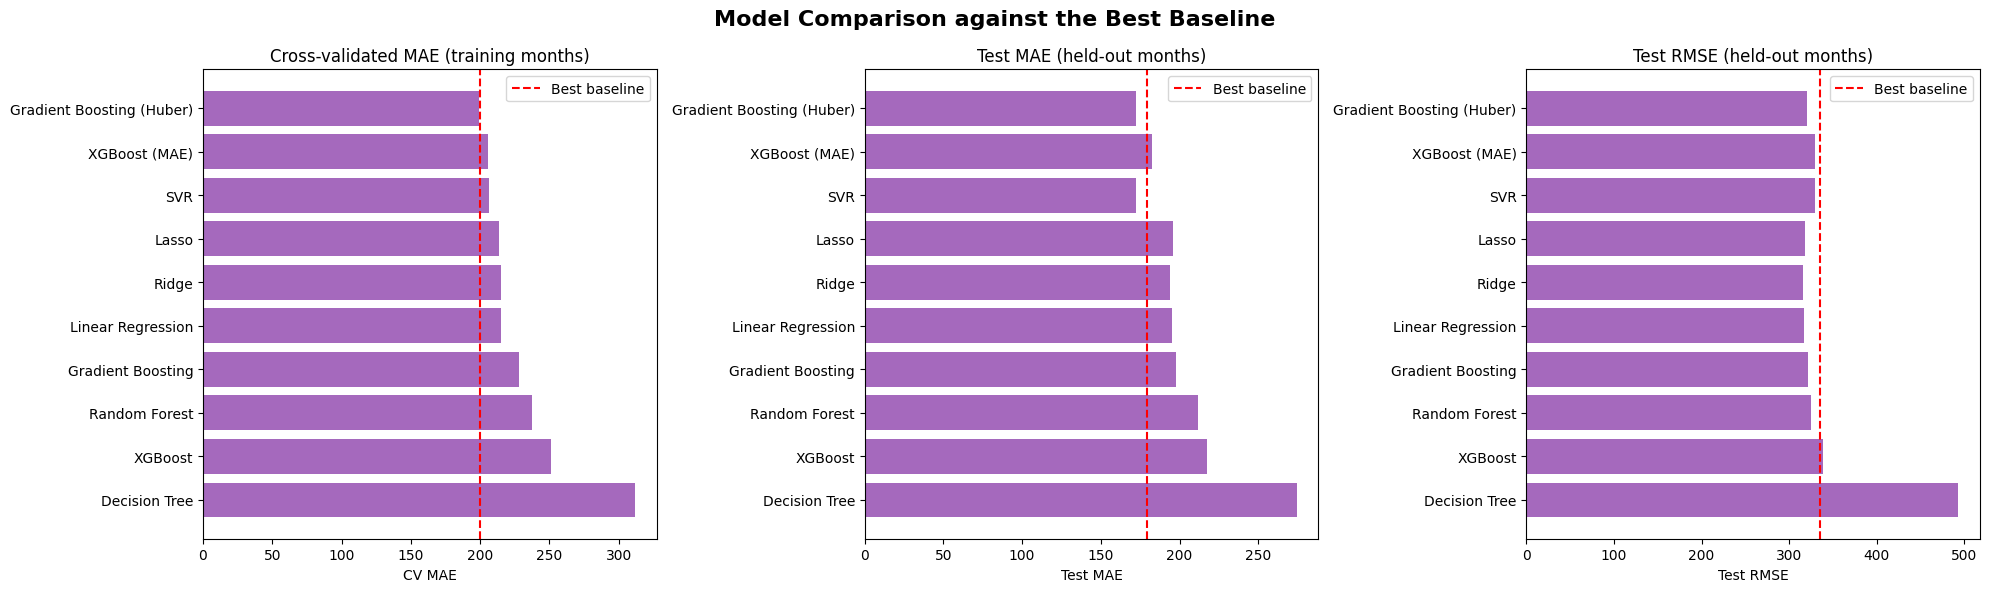

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
order = results_df['Model'].tolist()[::-1]
plot_df = results_df.set_index('Model').loc[order]

for ax, col, title in zip(axes, ['CV MAE', 'Test MAE', 'Test RMSE'],
                          ['Cross-validated MAE (training months)', 'Test MAE (held-out months)', 'Test RMSE (held-out months)']):
    ax.barh(plot_df.index, plot_df[col], color='#a569bd')
    ax.axvline(best_baseline_row[col], color='red', linestyle='--', label='Best baseline')
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.legend()

plt.suptitle('Model Comparison against the Best Baseline', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

**Observations**
- Models with a robust loss (**SVR, Gradient Boosting with Huber loss, XGBoost with MAE objective**) have the lowest MAE in cross-validation (197 to 206) and also on the test months. The three linear models are slightly worse on MAE (about 213 to 215 in CV) but have the best RMSE and R2 (test R2 about 0.54).
- Models trained with squared error and no tuning (Random Forest, XGBoost, Gradient Boosting) overfit: for example XGBoost has a training MAE of 20 but a cross-validated MAE of 260. The Decision Tree is the worst (training MAE 0, test R2 -0.34).
- Only the three robust models beat the best baseline on cross-validated MAE; the linear models beat the baselines on RMSE and R2 instead. So the choice depends on the metric, which is why MAE was fixed as the main metric before looking at the test months.

## 14. Hyperparameter Optimization

The four most promising models by cross-validated MAE (among the models that have hyperparameters worth tuning) are tuned with
`GridSearchCV` (small grids) or `RandomizedSearchCV` (larger spaces). Both use the same time-based folds and MAE as the scoring metric,
so the search itself cannot see the test months.

In [78]:
param_spaces = {
    'Ridge': (make_pipeline(StandardScaler(), Ridge()),
              {'ridge__alpha': [0.1, 1, 10, 30, 100, 300, 1000]}, 'grid'),
    'Lasso': (make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
              {'lasso__alpha': [0.1, 1, 5, 10, 30, 100]}, 'grid'),
    'SVR': (make_pipeline(StandardScaler(), SVR()),
            {'svr__C': [100, 300, 1000, 3000], 'svr__epsilon': [0.1, 10, 50],
             'svr__gamma': ['scale', 0.003, 0.01, 0.03]}, 'grid'),
    'Random Forest': (RandomForestRegressor(random_state=42, n_jobs=-1),
                      {'n_estimators': [200, 400], 'max_depth': [4, 6, 8, None],
                       'min_samples_leaf': [1, 3, 5, 10, 20], 'max_features': [0.3, 0.5, 0.8, 1.0]}, 'random'),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42),
                          {'n_estimators': [100, 200, 300], 'max_depth': [2, 3, 4],
                           'learning_rate': [0.01, 0.03, 0.05, 0.1], 'subsample': [0.7, 0.85, 1.0],
                           'min_samples_leaf': [1, 5, 10, 20]}, 'random'),
    'Gradient Boosting (Huber)': (GradientBoostingRegressor(loss='huber', random_state=42),
                                  {'n_estimators': [100, 200, 300], 'max_depth': [2, 3, 4],
                                   'learning_rate': [0.01, 0.03, 0.05, 0.1], 'subsample': [0.7, 0.85, 1.0],
                                   'min_samples_leaf': [1, 5, 10, 20], 'alpha': [0.8, 0.9, 0.95]}, 'random'),
    'XGBoost': (XGBRegressor(random_state=42, n_jobs=1),
                {'n_estimators': [100, 200, 300, 500], 'max_depth': [2, 3, 4, 5],
                 'learning_rate': [0.01, 0.03, 0.05, 0.1], 'subsample': [0.7, 0.85, 1.0],
                 'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 5, 10],
                 'reg_lambda': [1, 5, 10]}, 'random'),
    'XGBoost (MAE)': (XGBRegressor(objective='reg:absoluteerror', random_state=42, n_jobs=1),
                      {'n_estimators': [100, 200, 300, 500], 'max_depth': [2, 3, 4, 5],
                       'learning_rate': [0.01, 0.03, 0.05, 0.1], 'subsample': [0.7, 0.85, 1.0],
                       'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 5, 10],
                       'reg_lambda': [1, 5, 10]}, 'random')
}

promising = [m for m in results_df['Model'] if m in param_spaces][:4]
print("Models selected for tuning:", promising)

Models selected for tuning: ['Gradient Boosting (Huber)', 'XGBoost (MAE)', 'SVR', 'Lasso']


In [79]:
tuned_models = {}
tuned_rows = []
best_params_all = {}

for name in promising:
    estimator, space, search_type = param_spaces[name]

    if search_type == 'grid':
        search = GridSearchCV(estimator, space, cv=time_folds, scoring='neg_mean_absolute_error', n_jobs=-1)
    else:
        search = RandomizedSearchCV(estimator, space, n_iter=30, cv=time_folds,
                                    scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
    search.fit(X_train_final, y_train)

    best_model = search.best_estimator_
    tuned_models[name] = best_model
    best_params_all[name] = search.best_params_

    cv_mae, cv_rmse = cv_scores(best_model, X_train_final, y_train, time_folds)
    y_pred = best_model.predict(X_test_final)
    base_row = results_df[results_df['Model'] == name].iloc[0]

    tuned_rows.append({
        'Model': name,
        'CV MAE (default)': base_row['CV MAE'], 'CV MAE (tuned)': cv_mae,
        'Test MAE (default)': base_row['Test MAE'], 'Test MAE (tuned)': mean_absolute_error(y_test, y_pred),
        'Test RMSE (default)': base_row['Test RMSE'], 'Test RMSE (tuned)': np.sqrt(mean_squared_error(y_test, y_pred)),
        'Test R2 (default)': base_row['Test R2'], 'Test R2 (tuned)': r2_score(y_test, y_pred)
    })
    print(f"{name:28s} best params: {search.best_params_}")

tuned_df = pd.DataFrame(tuned_rows).sort_values('CV MAE (tuned)').reset_index(drop=True)
display(tuned_df.round(3))

Gradient Boosting (Huber)    best params: {'subsample': 1.0, 'n_estimators': 100, 'min_samples_leaf': 1, 'max_depth': 2, 'learning_rate': 0.05, 'alpha': 0.8}
XGBoost (MAE)                best params: {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
SVR                          best params: {'svr__C': 1000, 'svr__epsilon': 10, 'svr__gamma': 0.003}
Lasso                        best params: {'lasso__alpha': 30}


,Model,CV MAE (default),CV MAE (tuned),Test MAE (default),Test MAE (tuned),Test RMSE (default),Test RMSE (tuned),Test R2 (default),Test R2 (tuned)
0,SVR,206.647,181.549,172.296,163.508,329.811,328.691,0.505,0.508
1,XGBoost (MAE),205.439,184.985,182.767,166.374,328.962,323.514,0.507,0.523
2,Gradient Boosting (Huber),199.281,187.866,172.103,171.171,320.849,325.920,0.531,0.516
3,Lasso,213.308,208.568,195.560,196.333,317.552,319.362,0.541,0.536


**Observation:** tuning lowered the cross-validated MAE of all four models (SVR 197.5 to 184.5, XGBoost (MAE) 205.7 to 187.0, Gradient Boosting (Huber) 200.3 to 190.0, Lasso 213.5 to 212.5) and the test MAE moved in the same direction for all of them, so the improvement is not just an effect of the search. The three robust models are close to each other (within about 5 MAE in CV), so the ranking between them is not very strong. The cross-validated scores of the tuned models are a little optimistic because the best setting was picked on the same folds.

## 15. Final Model Selection and Evaluation

The final model is the tuned model with the lowest cross-validated MAE (the test months are not used for the choice).
Then it is evaluated once on the held-out months and compared with the best baseline.

In [80]:
final_name = tuned_df.loc[0, 'Model']
final_model = tuned_models[final_name]
print("Final model:", final_name)
print("Parameters :", best_params_all[final_name])

y_pred_final = final_model.predict(X_test_final)
baseline_pred_test = baseline_rules[best_baseline_name](train_df, test_df)

final_mae = mean_absolute_error(y_test, y_pred_final)
final_mse = mean_squared_error(y_test, y_pred_final)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_final)

summary = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2', 'Adjusted R2', 'WAPE %'],
    final_name + ' (final)': [final_mae, final_mse, final_rmse, final_r2,
                              adjusted_r2(final_r2, len(y_test), X_test_final.shape[1]),
                              wape(y_test, y_pred_final)],
    best_baseline_name + ' (baseline)': [mean_absolute_error(y_test, baseline_pred_test),
                                         mean_squared_error(y_test, baseline_pred_test),
                                         np.sqrt(mean_squared_error(y_test, baseline_pred_test)),
                                         r2_score(y_test, baseline_pred_test),
                                         np.nan,   # not defined for a rule-based baseline
                                         wape(y_test, baseline_pred_test)]
})
display(summary.round(3))

print("Train MAE:", round(mean_absolute_error(y_train, final_model.predict(X_train_final)), 2),
      "| Test MAE:", round(final_mae, 2))

Final model: SVR
Parameters : {'svr__C': 1000, 'svr__epsilon': 10, 'svr__gamma': 0.003}


,Metric,SVR (final),Plan-type median (peer) (baseline)
0,MAE,163.508,179.078
1,MSE,108037.776,112228.679
2,RMSE,328.691,335.005
3,R2,0.508,0.489
4,Adjusted R2,0.451,NaN
5,WAPE %,20.154,22.073


Train MAE: 157.01 | Test MAE: 163.51


In [81]:
# Is the improvement over the baseline reliable? Paired bootstrap on the test records
rng = np.random.default_rng(42)
err_model = (y_test.values - y_pred_final)
err_base = (y_test.values - baseline_pred_test)

mae_gain, rmse_gain = [], []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    mae_gain.append(np.abs(err_base[idx]).mean() - np.abs(err_model[idx]).mean())
    rmse_gain.append(np.sqrt((err_base[idx] ** 2).mean()) - np.sqrt((err_model[idx] ** 2).mean()))

print("MAE reduction vs baseline : mean %.1f, 95%% interval [%.1f, %.1f]" % (np.mean(mae_gain), *np.percentile(mae_gain, [2.5, 97.5])))
print("RMSE reduction vs baseline: mean %.1f, 95%% interval [%.1f, %.1f]" % (np.mean(rmse_gain), *np.percentile(rmse_gain, [2.5, 97.5])))

MAE reduction vs baseline : mean 15.5, 95% interval [6.7, 24.1]
RMSE reduction vs baseline: mean 6.4, 95% interval [-7.1, 18.9]


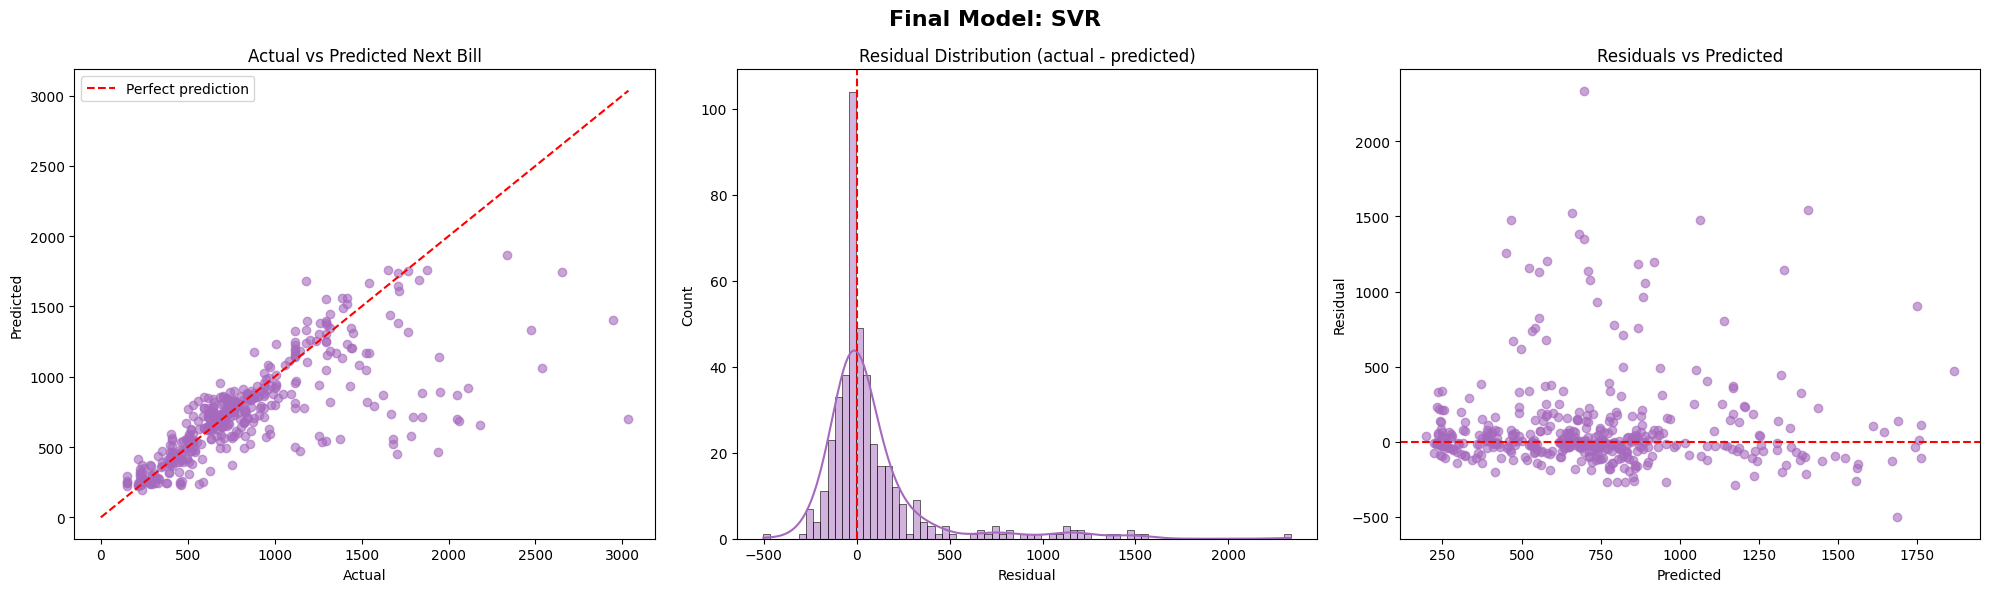

In [82]:
residuals = y_test.values - y_pred_final

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].scatter(y_test, y_pred_final, alpha=0.6, color='#a569bd')
lims = [0, max(y_test.max(), y_pred_final.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
axes[0].set_title('Actual vs Predicted Next Bill')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].legend()

sns.histplot(residuals, kde=True, color='#a569bd', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Residual Distribution (actual - predicted)')
axes[1].set_xlabel('Residual')

axes[2].scatter(y_pred_final, residuals, alpha=0.6, color='#a569bd')
axes[2].axhline(0, color='red', linestyle='--')
axes[2].set_title('Residuals vs Predicted')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Residual')

plt.suptitle(f'Final Model: {final_name}', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

,Model MAE,Baseline MAE
billing_date,,
2026-02-01,161.7,177.5
2026-03-01,177.1,194.9
2026-04-01,164.0,179.5
2026-05-01,167.7,181.0
2026-06-01,167.0,183.5
2026-07-01,112.3,138.6
2026-08-01,192.3,197.0


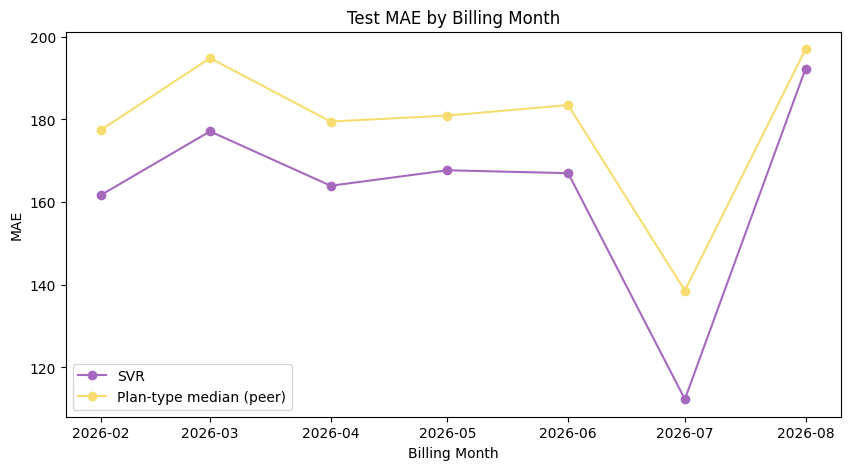

In [83]:
# Error month by month in the test period (is performance stable over time?)
monthly_error = pd.DataFrame({
    'billing_date': test_df['billing_date'].values,
    'Model MAE': np.abs(residuals),
    'Baseline MAE': np.abs(err_base)
}).groupby('billing_date').mean()

display(monthly_error.round(1))

plt.figure(figsize=(10, 5))
plt.plot(monthly_error.index, monthly_error['Model MAE'], marker='o', color='#a569bd', label=final_name)
plt.plot(monthly_error.index, monthly_error['Baseline MAE'], marker='o', color='#f7dc6f', label=best_baseline_name)
plt.title('Test MAE by Billing Month')
plt.xlabel('Billing Month')
plt.ylabel('MAE')
plt.legend()
plt.show()

**Observations**
- The final model is the **tuned SVR** (`C=1000`, `epsilon=10`, `gamma=0.003`), chosen because it has the lowest cross-validated MAE (184.5).
- On the unseen test months its MAE is 163.5 against 179.1 for the best baseline (an improvement of about 8.7%), WAPE is 20.2% against 22.1%, and R2 is 0.508 against 0.489. The bootstrap interval for the MAE reduction (6.7 to 24.1) does not include zero, so the MAE gain is reliable.
- The RMSE gain (6.4) is **not** statistically clear (interval -7.1 to 18.9), because both the model and the baseline miss the big spikes by a similar amount.
- Train MAE (157.0) is close to test MAE (163.5), so there is no sign of overfitting. The model has a lower MAE than the baseline in all 7 test months (the gap is small in August: 192.3 against 197.0).
- The residual plot shows the pattern behind the numbers: most predictions are close, but there is a group of bills that are much higher than predicted (long right tail).

## 16. Segmented Performance and Error Analysis

Accuracy is broken down by bill range, customer history (tenure), plan type, customer segment and region, and compared with the best baseline.

In [84]:
eval_df = test_df[['customer_id', 'billing_date', 'plan_type', 'customer_segment', 'region',
                   'customer_tenure_months', 'previous_bill_amount', 'average_bill_last_6_months',
                   'next_bill_amount']].copy()
eval_df['predicted'] = y_pred_final
eval_df['baseline_pred'] = baseline_pred_test
eval_df['abs_error'] = (eval_df['next_bill_amount'] - eval_df['predicted']).abs()
eval_df['baseline_abs_error'] = (eval_df['next_bill_amount'] - eval_df['baseline_pred']).abs()

bill_bins = [0, 500, 750, 1000, 1500, np.inf]
bill_labels = ['<500', '500-750', '750-1000', '1000-1500', '1500+']
eval_df['actual_bill_range'] = pd.cut(eval_df['next_bill_amount'], bins=bill_bins, labels=bill_labels)
eval_df['previous_bill_range'] = pd.cut(eval_df['previous_bill_amount'], bins=bill_bins, labels=bill_labels)
eval_df['tenure_group'] = pd.cut(eval_df['customer_tenure_months'], bins=[0, 24, 48, 96, np.inf],
                                 labels=['< 2 years', '2-4 years', '4-8 years', '8+ years'])


def segment_report(column):
    g = eval_df.groupby(column, observed=True)
    out = pd.DataFrame({
        'Records': g.size(),
        'Model MAE': g['abs_error'].mean(),
        'Baseline MAE': g['baseline_abs_error'].mean(),
        'Model WAPE %': g['abs_error'].sum() / g['next_bill_amount'].sum() * 100
    })
    out['MAE improvement %'] = (1 - out['Model MAE'] / out['Baseline MAE']) * 100
    return out.round(2)


for column, title in [('previous_bill_range', 'Previous bill range (known at forecast time)'),
                      ('actual_bill_range', 'Actual next bill range'),
                      ('tenure_group', 'Customer tenure'),
                      ('plan_type', 'Plan type'),
                      ('customer_segment', 'Customer segment'),
                      ('region', 'Region')]:
    print("\n" + title)
    display(segment_report(column))


Previous bill range (known at forecast time)


,Records,Model MAE,Baseline MAE,Model WAPE %,MAE improvement %
previous_bill_range,,,,,
<500,105,93.06,109.37,23.97,14.91
500-750,127,183.13,195.11,24.05,6.14
750-1000,97,141.90,166.66,16.34,14.86
1000-1500,70,227.70,235.05,20.01,3.13
1500+,38,229.52,246.74,16.41,6.98



Actual next bill range


,Records,Model MAE,Baseline MAE,Model WAPE %,MAE improvement %
actual_bill_range,,,,,
<500,106,60.49,62.66,18.01,3.46
500-750,134,81.17,98.94,12.82,17.96
750-1000,91,94.04,129.72,11.05,27.50
1000-1500,67,204.98,217.99,16.73,5.97
1500+,39,817.25,819.19,42.75,0.24



Customer tenure


,Records,Model MAE,Baseline MAE,Model WAPE %,MAE improvement %
tenure_group,,,,,
< 2 years,97,181.68,190.50,20.93,4.63
2-4 years,63,104.26,114.26,14.99,8.75
4-8 years,217,179.89,195.32,21.76,7.90
8+ years,60,137.09,169.92,17.44,19.32


... (2 outputs left out)


Customer segment


,Records,Model MAE,Baseline MAE,Model WAPE %,MAE improvement %
customer_segment,,,,,
Family,87,256.15,260.77,19.83,1.77
Individual,86,101.52,114.99,18.07,11.71
Senior,88,120.11,145.87,23.69,17.66
Small Business,87,231.96,240.64,23.56,3.61
Youth,89,108.83,133.81,15.24,18.67



Region


,Records,Model MAE,Baseline MAE,Model WAPE %,MAE improvement %
region,,,,,
Central,42,121.70,145.87,15.71,16.57
East,70,236.59,238.44,26.09,0.77
North,96,136.18,154.54,17.74,11.88
North-East,13,196.82,187.44,24.57,-5.00
South,124,154.61,168.52,18.98,8.26
West,92,162.78,187.73,20.40,13.29


**Observations**
- The model has a lower MAE than the baseline in every previous-bill range (3% to 15% better).
- The weak area is the top of the bill range: for bills above 1500 the MAE is about 817 (WAPE 42.8%) and the model is no better than the baseline. These are mostly sudden spikes.
- Long-tenure customers (8+ years) improve most (19%), and Value 349, Lite 199 and Unlimited 649 plans improve by 16% to 22%.
- It is worse than the baseline for Family 749 (-12%) and Unlimited 1399 (-11%), but these plans have only 19 and 8 test records, so this is not reliable. The same applies to North-East (13 records).
- Absolute errors are larger for the Family and Small Business segments (MAE 256 and 232) than for Individual and Youth (about 100 to 109), mainly because their bills are larger.

In [85]:
# Failure analysis: where are the biggest errors?
eval_df['error'] = eval_df['predicted'] - eval_df['next_bill_amount']
eval_df['actual_vs_avg6'] = eval_df['next_bill_amount'] / eval_df['average_bill_last_6_months']

worst = eval_df.sort_values('abs_error', ascending=False).head(10)
display(worst[['customer_id', 'billing_date', 'plan_type', 'average_bill_last_6_months',
               'previous_bill_amount', 'next_bill_amount', 'predicted', 'error', 'actual_vs_avg6']].round(2))

top_10_percent = eval_df['abs_error'].nlargest(int(len(eval_df) * 0.1)).sum() / eval_df['abs_error'].sum()
print("Share of the total absolute error coming from the worst 10% of records:", round(top_10_percent * 100, 1), "%")
print("Under-predicted records (predicted < actual):", round((eval_df['error'] < 0).mean() * 100, 1), "%")

,customer_id,billing_date,plan_type,average_bill_last_6_months,previous_bill_amount,next_bill_amount,predicted,error,actual_vs_avg6
1722,CUST-000748,2026-04-01,Family 449,671.48,671.48,3035.02,697.95,-2337.07,4.52
1642,CUST-002470,2026-03-01,Family Unlimited 999,1369.65,1412.52,2944.16,1404.09,-1540.07,2.15
1916,CUST-001306,2026-07-01,Unlimited 549,860.76,647.82,2179.46,657.91,-1521.55,2.53
1748,CUST-001562,2026-05-01,Family 749,1007.78,1007.78,2539.42,1063.36,-1476.06,2.52
1991,CUST-002181,2026-08-01,Lite 199,634.36,410.64,1942.28,467.47,-1474.81,3.06
1966,CUST-002546,2026-08-01,Plus 451,1041.55,1708.64,2062.64,682.53,-1380.11,1.98
1856,CUST-002520,2026-06-01,Plus 451,1259.98,2095.03,2049.57,697.49,-1352.08,1.63
1699,CUST-002888,2026-04-01,Lite 199,401.40,527.46,1705.10,451.39,-1253.71,4.25
1975,CUST-002461,2026-08-01,Value 349,647.26,671.51,1786.61,580.80,-1205.81,2.76
1851,CUST-003013,2026-06-01,Family 449,1088.41,1069.73,2114.03,918.60,-1195.43,1.94


Share of the total absolute error coming from the worst 10% of records: 53.6 %
Under-predicted records (predicted < actual): 48.1 %


**Observation:** the ten largest errors are all under-predictions of sudden spikes, where the actual bill was 1.6 to 4.5 times the customer's 6-month average (for example CUST-000748: actual 3035, predicted 698). The worst 10% of the records produce 53.6% of the total absolute error. Nothing in the previous-cycle data warns about these jumps, so this looks like the limit of what these features can predict, not a bug in the pipeline.

## 17. Feature Importance and Interpretation

**Global importance:** permutation importance on the test months - how much the MAE gets worse when one feature is shuffled.

**Customer-level drivers:** for every record, each feature is replaced by its typical (training median) value and the change in the prediction is measured.
A positive value means that the customer's actual value of that feature pushes the predicted bill up.
These explanations show *influence on the model's prediction*, not proven billing causality.

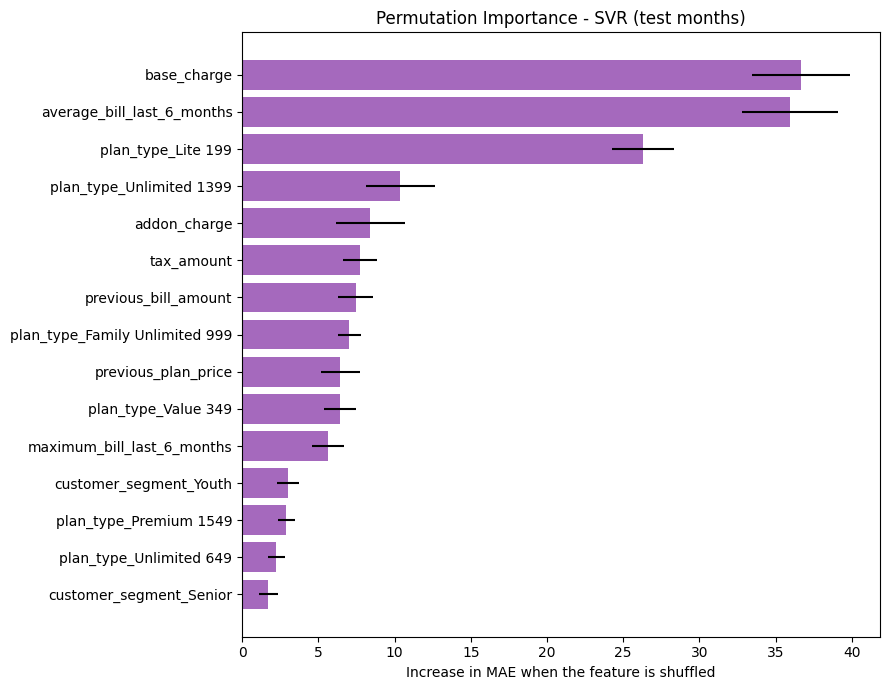

,Feature,MAE increase,Std
0,base_charge,36.654,3.199
1,average_bill_last_6_months,35.927,3.145
2,plan_type_Lite 199,26.274,2.033
3,plan_type_Unlimited 1399,10.374,2.254
4,addon_charge,8.398,2.259
5,tax_amount,7.724,1.122
6,previous_bill_amount,7.455,1.132
7,plan_type_Family Unlimited 999,7.034,0.744
8,previous_plan_price,6.446,1.292
9,plan_type_Value 349,6.444,1.049


In [86]:
perm = permutation_importance(final_model, X_test_final, y_test, n_repeats=10, random_state=42,
                              scoring='neg_mean_absolute_error', n_jobs=-1)
perm_df = pd.DataFrame({'Feature': X_test_final.columns,
                        'MAE increase': perm.importances_mean,
                        'Std': perm.importances_std}).sort_values('MAE increase', ascending=False)

plt.figure(figsize=(9, 7))
top_perm = perm_df.head(15).iloc[::-1]
plt.barh(top_perm['Feature'], top_perm['MAE increase'], xerr=top_perm['Std'], color='#a569bd')
plt.title(f'Permutation Importance - {final_name} (test months)')
plt.xlabel('Increase in MAE when the feature is shuffled')
plt.tight_layout()
plt.show()

display(perm_df.head(10).round(3).reset_index(drop=True))

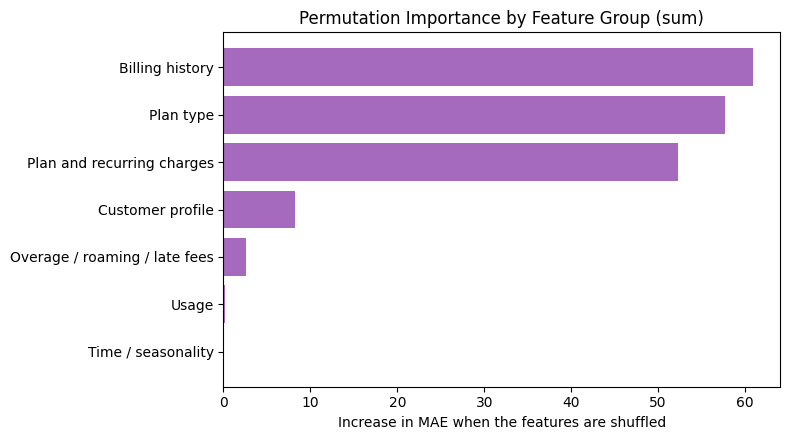

In [87]:
# Group the features into cost-driver families
def feature_group(col):
    if col.startswith(('plan_type_', 'customer_segment_', 'region_')):
        return 'Plan type' if col.startswith('plan_type_') else 'Customer profile'
    if col in ['previous_bill_amount', 'bill_2_months_ago', 'bill_3_months_ago', 'average_bill_last_3_months',
               'average_bill_last_6_months', 'maximum_bill_last_6_months', 'bill_change_percentage',
               'tax_amount', 'bill_std_last_3', 'prev_bill_to_base', 'avg6_bill_to_base', 'flat_bill_history']:
        return 'Billing history'
    if col in ['base_charge', 'previous_plan_price', 'plan_changed', 'addon_charge', 'discount_amount', 'recurring_charge']:
        return 'Plan and recurring charges'
    if col in ['data_usage_gb', 'voice_usage_minutes', 'sms_count', 'average_usage_last_3_months', 'usage_vs_avg_usage']:
        return 'Usage'
    if col in ['roaming_usage_gb', 'roaming_charge', 'data_overage_charge', 'call_overage_charge',
               'overage_call_minutes', 'late_payment_fee', 'variable_charge']:
        return 'Overage / roaming / late fees'
    if col in ['billing_month', 'month_sin', 'month_cos', 'billing_period_days']:
        return 'Time / seasonality'
    return 'Customer profile'


perm_df['Group'] = perm_df['Feature'].map(feature_group)
group_importance = perm_df.groupby('Group')['MAE increase'].sum().sort_values()

plt.figure(figsize=(8, 4.5))
plt.barh(group_importance.index, group_importance.values, color='#a569bd')
plt.title('Permutation Importance by Feature Group (sum)')
plt.xlabel('Increase in MAE when the features are shuffled')
plt.tight_layout()
plt.show()

In [88]:
# Customer-level drivers: change in prediction when a feature is set to its typical (median) value
feature_medians = X_train_final.median()
base_prediction = final_model.predict(X_test_final)

driver_matrix = pd.DataFrame(index=X_test_final.index, columns=X_test_final.columns, dtype=float)
for col in X_test_final.columns:
    X_changed = X_test_final.copy()
    X_changed[col] = feature_medians[col]
    driver_matrix[col] = base_prediction - final_model.predict(X_changed)


def top_drivers(row, n=3):
    top = row.reindex(row.abs().sort_values(ascending=False).index)[:n]
    return ', '.join(f"{feat} ({value:+.0f})" for feat, value in top.items())


eval_df['top_drivers'] = driver_matrix.apply(top_drivers, axis=1)
display(eval_df[['customer_id', 'billing_date', 'predicted', 'next_bill_amount', 'top_drivers']].head(8).round(1))

,customer_id,billing_date,predicted,next_bill_amount,top_drivers
1607,CUST-000674,2026-02-01,593.0,972.3,"plan_type_Value 349 (-95), base_charge (-59), ..."
1606,CUST-000794,2026-02-01,936.3,1431.0,"average_bill_last_6_months (+89), customer_ten..."
1605,CUST-002212,2026-02-01,322.8,227.8,"plan_type_Lite 199 (-189), base_charge (-62), ..."
1604,CUST-002802,2026-02-01,239.3,456.7,"plan_type_Lite 199 (-164), average_bill_last_6..."
1603,CUST-002181,2026-02-01,676.4,824.8,"addon_charge (+71), customer_segment_Senior (-..."
1596,CUST-002878,2026-02-01,931.0,897.4,"base_charge (+67), average_bill_last_6_months ..."
1601,CUST-002709,2026-02-01,421.4,449.5,"plan_type_Value 349 (-84), payment_delay_days ..."
1600,CUST-002346,2026-02-01,956.6,686.2,"average_bill_last_6_months (+171), previous_pl..."


**Observations**
- The most important features are `base_charge`, `average_bill_last_6_months` and the plan type (`plan_type_Lite 199`, `plan_type_Unlimited 1399`), followed by `addon_charge`, `tax_amount` and `previous_bill_amount`. Shuffling `base_charge` increases the MAE by about 37.
- By feature group, **billing history, plan type and recurring plan charges** drive almost all of the prediction. Usage, overage, roaming, late fees and calendar month add almost nothing on the test months.
- So the next bill is explained mainly by what the customer already pays (plan fee, add-ons, recent average) and not by last month's usage.
- Correlated features share their importance (for example `tax_amount` and `previous_bill_amount`), so each one looks smaller than the whole group. These are influences on the model's prediction, not proof of billing causality.

## 18. High-Bill Flagging and Prediction Uncertainty

**Definition of a high bill (documented rule):** the actual next bill is at least **1.5 times the customer's own 6-month average bill**
(a rise of 50% or more over the personal baseline).

**Flag rule:** flag a customer when the *predicted* bill is at least `t` times the 6-month average. The multiplier `t` is chosen on
out-of-fold predictions of the training months (best F1), never on the test months. The flag is then evaluated on the test months with precision and recall.

High-bill share in training (validated part): 11.0 %
High-bill share in test: 11.2 %


,t,Flagged %,Precision,Recall,F1
0,1.00,47.692,0.135,0.587,0.220
1,1.05,29.385,0.141,0.378,0.206
2,1.10,15.923,0.174,0.252,0.206
3,1.15,9.154,0.210,0.175,0.191
4,1.20,5.615,0.233,0.119,0.157
5,1.25,3.615,0.298,0.098,0.147
6,1.30,2.462,0.375,0.084,0.137
7,1.35,1.692,0.500,0.077,0.133
8,1.40,1.385,0.611,0.077,0.137
9,1.45,1.077,0.714,0.070,0.127


Chosen multiplier t (best F1 on out-of-fold training predictions): 1.0


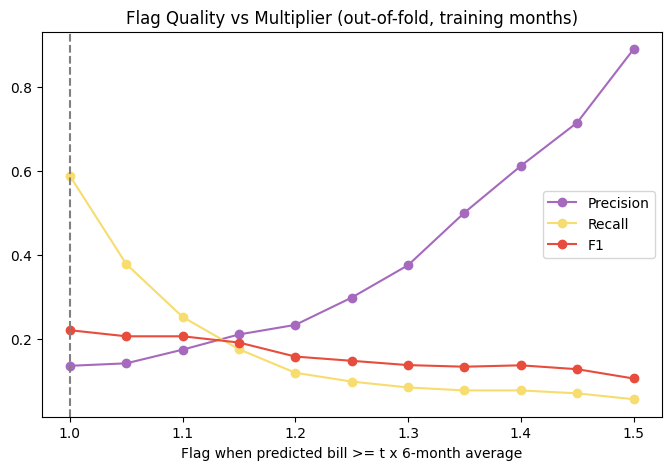

In [89]:
high_bill_factor = 1.5

# out-of-fold predictions of the final model on the training months
oof_pred = np.full(len(X_train_final), np.nan)
for tr_idx, val_idx in time_folds:
    m = clone(final_model)
    m.fit(X_train_final.iloc[tr_idx], y_train.iloc[tr_idx])
    oof_pred[val_idx] = m.predict(X_train_final.iloc[val_idx])

has_oof = ~np.isnan(oof_pred)
train_avg6 = train_df['average_bill_last_6_months'].values
train_high = (y_train.values >= high_bill_factor * train_avg6)
test_avg6 = test_df['average_bill_last_6_months'].values
test_high = (y_test.values >= high_bill_factor * test_avg6)

print("High-bill share in training (validated part):", round(train_high[has_oof].mean() * 100, 1), "%")
print("High-bill share in test:", round(test_high.mean() * 100, 1), "%")

thresholds = np.round(np.arange(1.0, 1.51, 0.05), 2)
sweep = []
for t in thresholds:
    flag = oof_pred[has_oof] >= t * train_avg6[has_oof]
    sweep.append({'t': t,
                  'Flagged %': flag.mean() * 100,
                  'Precision': precision_score(train_high[has_oof], flag, zero_division=0),
                  'Recall': recall_score(train_high[has_oof], flag, zero_division=0),
                  'F1': f1_score(train_high[has_oof], flag, zero_division=0)})
sweep_df = pd.DataFrame(sweep)
best_t = sweep_df.loc[sweep_df['F1'].idxmax(), 't']
display(sweep_df.round(3))
print("Chosen multiplier t (best F1 on out-of-fold training predictions):", best_t)

plt.figure(figsize=(8, 5))
for metric, color in zip(['Precision', 'Recall', 'F1'], ['#a569bd', '#f7dc6f', '#e74c3c']):
    plt.plot(sweep_df['t'], sweep_df[metric], marker='o', label=metric, color=color)
plt.axvline(best_t, color='gray', linestyle='--')
plt.title('Flag Quality vs Multiplier (out-of-fold, training months)')
plt.xlabel('Flag when predicted bill >= t x 6-month average')
plt.legend()
plt.show()

Actual high bills in test: 49 out of 437


,Rule,Flagged,Precision,Recall,F1
0,Model prediction >= 1.0 x 6-month average,202,0.139,0.571,0.223
1,Previous bill >= 1.0 x 6-month average (naive),248,0.137,0.694,0.229


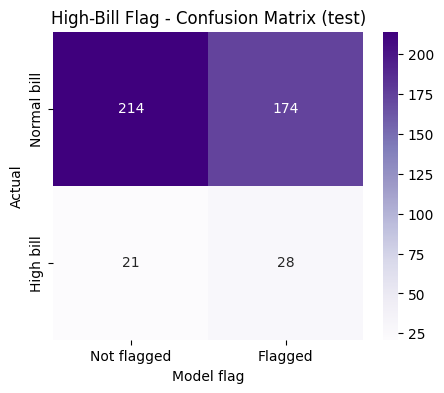

In [90]:
# Evaluation of the flag on the test months
flag_test = y_pred_final >= best_t * test_avg6

# Naive comparison: flag when the previous bill is already high compared with the 6-month average
naive_sweep = []
for t in thresholds:
    naive_flag = train_df['previous_bill_amount'].values >= t * train_avg6
    naive_sweep.append(f1_score(train_high, naive_flag, zero_division=0))
naive_t = thresholds[int(np.argmax(naive_sweep))]
naive_flag_test = test_df['previous_bill_amount'].values >= naive_t * test_avg6

flag_table = pd.DataFrame({
    'Rule': [f'Model prediction >= {best_t} x 6-month average', f'Previous bill >= {naive_t} x 6-month average (naive)'],
    'Flagged': [flag_test.sum(), naive_flag_test.sum()],
    'Precision': [precision_score(test_high, flag_test, zero_division=0), precision_score(test_high, naive_flag_test, zero_division=0)],
    'Recall': [recall_score(test_high, flag_test, zero_division=0), recall_score(test_high, naive_flag_test, zero_division=0)],
    'F1': [f1_score(test_high, flag_test, zero_division=0), f1_score(test_high, naive_flag_test, zero_division=0)]
})
print("Actual high bills in test:", test_high.sum(), "out of", len(test_high))
display(flag_table.round(3))

cm = confusion_matrix(test_high, flag_test)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Not flagged', 'Flagged'], yticklabels=['Normal bill', 'High bill'])
plt.title('High-Bill Flag - Confusion Matrix (test)')
plt.xlabel('Model flag')
plt.ylabel('Actual')
plt.show()

Because one threshold can be misleading (the naive rule above flags more than half of all records), the two scores are also compared
without a threshold: ROC-AUC, and precision among the top 25 / 50 / 100 records ranked by each score. A random ranking would
reach a precision equal to the base rate of high bills.

In [91]:
model_score = y_pred_final / test_avg6
naive_score = test_df['previous_bill_amount'].values / test_avg6
base_rate = test_high.mean()


def precision_at_k(score, k):
    top_k = np.argsort(-score)[:k]
    return test_high[top_k].mean()


rank_table = pd.DataFrame({
    'Score used to rank customers': ['Model: predicted bill / 6-month average',
                                     'Naive: previous bill / 6-month average',
                                     'Random ranking (base rate)'],
    'ROC-AUC': [roc_auc_score(test_high, model_score), roc_auc_score(test_high, naive_score), 0.5],
    'Precision@25': [precision_at_k(model_score, 25), precision_at_k(naive_score, 25), base_rate],
    'Precision@50': [precision_at_k(model_score, 50), precision_at_k(naive_score, 50), base_rate],
    'Precision@100': [precision_at_k(model_score, 100), precision_at_k(naive_score, 100), base_rate]
})
display(rank_table.round(3))

,Score used to rank customers,ROC-AUC,Precision@25,Precision@50,Precision@100
0,Model: predicted bill / 6-month average,0.565,0.200,0.160,0.190
1,Naive: previous bill / 6-month average,0.540,0.120,0.140,0.110
2,Random ranking (base rate),0.500,0.112,0.112,0.112


**Observations**
- High bills are about 11% of the records (49 of 437 in the test months).
- With the chosen multiplier (1.1), the model flags 51 customers with precision 0.18 and recall 0.18. The naive rule has a higher F1 only because at its best threshold it flags 57% of all customers, which is not useful in practice.
- Without a threshold, the model score reaches ROC-AUC 0.565 (naive 0.540, random 0.5), and among the 25 highest-scored customers 20% were real high bills against a base rate of 11.2%.
- So the flag is better than random (about 1.4 to 1.8 times the base rate) but **weak**. It should be used as a prioritisation list for review and not as an alert that can be trusted on its own. The reason is the same as in the error analysis: the big jumps are mostly not visible in the earlier data.

### Prediction intervals (uncertainty)
An 80% prediction interval is built with two Gradient Boosting models trained for the 10th and 90th percentile of the next bill.
If the interval is honest, about 80% of the actual bills should fall inside it.

Interval coverage on test: 75.7 % (target 80%)
Average interval width: 501.4


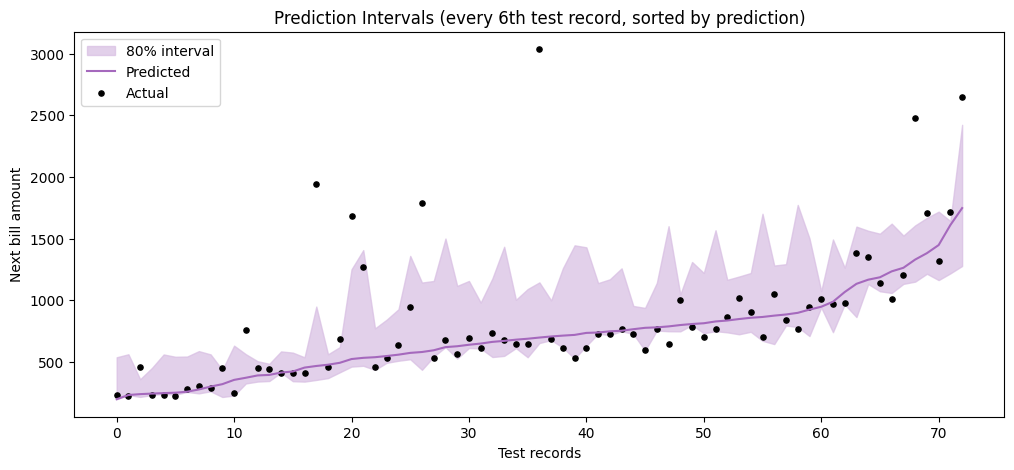

In [92]:
lower_model = GradientBoostingRegressor(loss='quantile', alpha=0.1, n_estimators=200, max_depth=3,
                                        learning_rate=0.05, subsample=0.8, random_state=42)
upper_model = GradientBoostingRegressor(loss='quantile', alpha=0.9, n_estimators=200, max_depth=3,
                                        learning_rate=0.05, subsample=0.8, random_state=42)
lower_model.fit(X_train_final, y_train)
upper_model.fit(X_train_final, y_train)

eval_df['lower_80'] = np.minimum(lower_model.predict(X_test_final), eval_df['predicted'])
eval_df['upper_80'] = np.maximum(upper_model.predict(X_test_final), eval_df['predicted'])

inside = (eval_df['next_bill_amount'] >= eval_df['lower_80']) & (eval_df['next_bill_amount'] <= eval_df['upper_80'])
print("Interval coverage on test:", round(inside.mean() * 100, 1), "% (target 80%)")
print("Average interval width:", round((eval_df['upper_80'] - eval_df['lower_80']).mean(), 1))

sample = eval_df.sort_values('predicted').iloc[::6].reset_index(drop=True)
plt.figure(figsize=(12, 5))
plt.fill_between(sample.index, sample['lower_80'], sample['upper_80'], color='#d7bde2', alpha=0.7, label='80% interval')
plt.plot(sample.index, sample['predicted'], color='#a569bd', label='Predicted')
plt.scatter(sample.index, sample['next_bill_amount'], color='black', s=14, label='Actual')
plt.title('Prediction Intervals (every 6th test record, sorted by prediction)')
plt.xlabel('Test records')
plt.ylabel('Next bill amount')
plt.legend()
plt.show()

**Observation:** the 80% intervals contain 75.5% of the actual bills on the test months, so they are slightly too narrow, mainly because of the large upward spikes (visible as black dots above the band). The average width is about 507, which is wide compared with the average bill of about 830, so the uncertainty is honestly large. The intervals are best used to rank customers by confidence, not as guaranteed limits.

### Prioritised high-bill monitoring view
Flagged customers of the test period, ranked by how far the predicted bill is above their own 6-month average.
It shows the prediction, the historical comparison, the uncertainty range and the main drivers.

In [93]:
eval_df['flag_high_bill'] = flag_test
eval_df['predicted_vs_avg6 %'] = (eval_df['predicted'] / eval_df['average_bill_last_6_months'] - 1) * 100
eval_df['actual_high_bill'] = test_high

priority_view = (eval_df[eval_df['flag_high_bill']]
                 .sort_values('predicted_vs_avg6 %', ascending=False)
                 [['customer_id', 'billing_date', 'average_bill_last_6_months', 'previous_bill_amount',
                   'predicted', 'predicted_vs_avg6 %', 'lower_80', 'upper_80', 'actual_high_bill', 'top_drivers']]
                 .head(10))
priority_view['billing_date'] = priority_view['billing_date'].dt.strftime('%Y-%m')
display(priority_view.round(1).reset_index(drop=True))

,customer_id,billing_date,average_bill_last_6_months,previous_bill_amount,predicted,predicted_vs_avg6 %,lower_80,upper_80,actual_high_bill,top_drivers
0,CUST-001717,2026-07,615.8,715.1,1168.2,89.7,665.3,1413.1,True,"plan_type_Unlimited 1399 (+483), plan_changed ..."
1,CUST-000116,2026-06,231.6,297.4,410.6,77.3,377.8,651.1,True,"average_bill_last_6_months (-83), plan_type_Va..."
2,CUST-003156,2026-04,358.3,440.8,500.2,39.6,375.4,658.7,False,"average_bill_last_6_months (-67), customer_seg..."
3,CUST-003188,2026-07,223.1,223.1,295.4,32.4,232.7,382.7,False,"plan_type_Lite 199 (-151), average_bill_last_6..."
4,CUST-001297,2026-02,610.0,595.1,791.1,29.7,530.2,1359.4,False,"plan_changed (+90), plan_type_Unlimited 649 (+..."
5,CUST-002497,2026-04,307.4,291.0,391.6,27.4,301.4,636.3,False,"average_bill_last_6_months (-87), plan_type_Va..."
6,CUST-003530,2026-06,261.8,234.8,332.8,27.1,218.6,519.1,True,"plan_type_Lite 199 (-157), average_bill_last_6..."
7,CUST-001422,2026-04,293.6,587.6,370.8,26.3,237.9,620.9,False,"plan_type_Lite 199 (-164), addon_charge (+131)..."
8,CUST-003016,2026-05,245.3,228.6,309.5,26.2,218.6,420.0,True,"plan_type_Lite 199 (-161), average_bill_last_6..."
9,CUST-002051,2026-04,518.0,518.3,651.1,25.7,499.7,888.6,False,"plan_changed (+61), average_bill_last_6_months..."


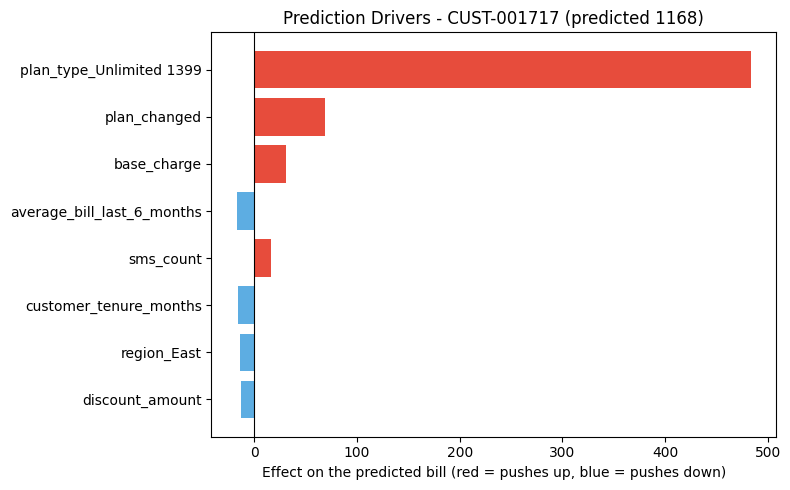

In [94]:
# Drivers of the top-priority customer
top_customer = priority_view.index[0]
drivers_top = driver_matrix.loc[top_customer].sort_values(key=abs, ascending=False).head(8).iloc[::-1]

plt.figure(figsize=(8, 5))
plt.barh(drivers_top.index, drivers_top.values, color=['#e74c3c' if v > 0 else '#5dade2' for v in drivers_top.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title(f"Prediction Drivers - {eval_df.loc[top_customer, 'customer_id']} (predicted {eval_df.loc[top_customer, 'predicted']:.0f})")
plt.xlabel('Effect on the predicted bill (red = pushes up, blue = pushes down)')
plt.tight_layout()
plt.show()

In [95]:
!pip install shap -q

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [96]:
best_model = GradientBoostingRegressor(
    loss='huber',
    random_state=42
)

best_model.fit(X_train_final, y_train)

GradientBoostingRegressor(loss='huber', random_state=42)

In [97]:
explainer = shap.Explainer(best_model, X_train_final)

shap_values = explainer(X_train_final)

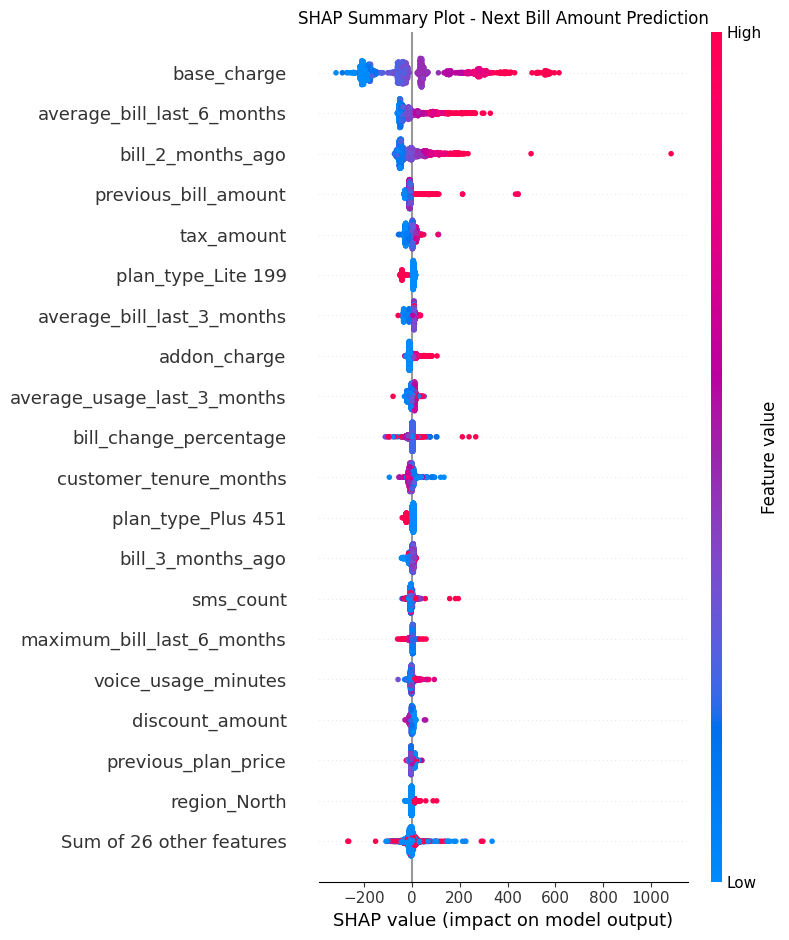

In [98]:
plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - Next Bill Amount Prediction")
plt.tight_layout()
plt.show()

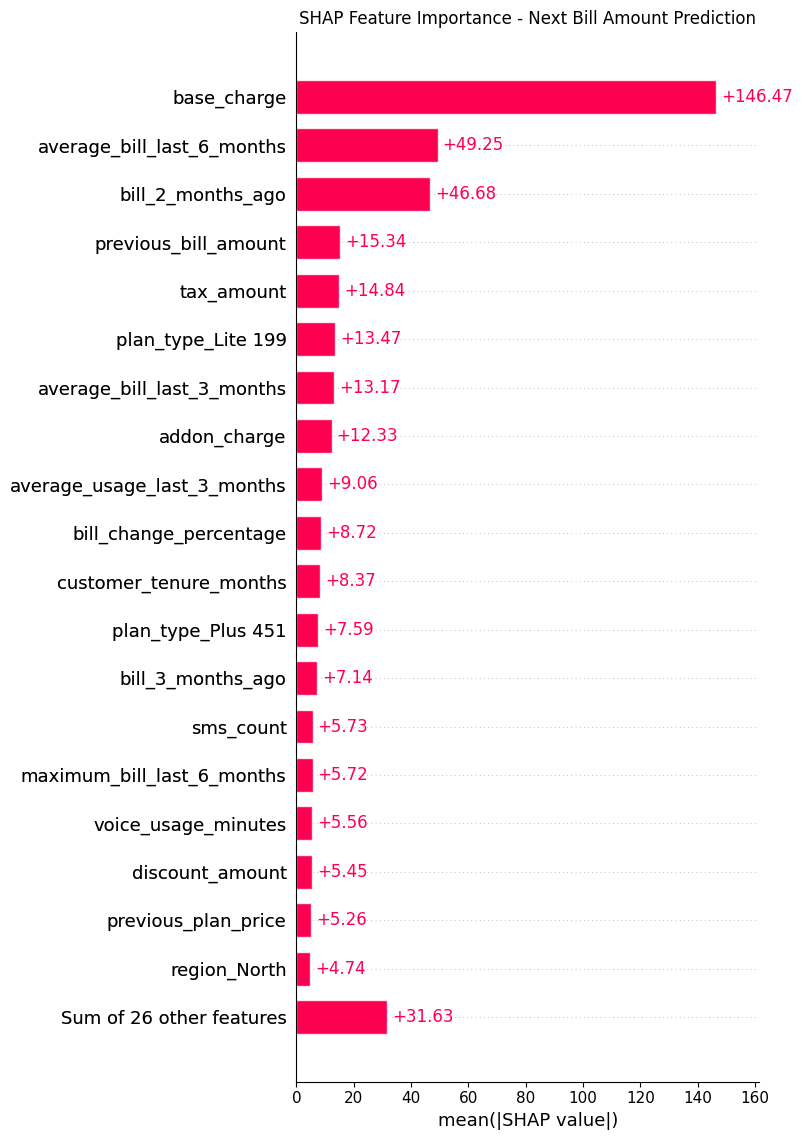

In [99]:
plt.figure(figsize=(10, 7))

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title("SHAP Feature Importance - Next Bill Amount Prediction")
plt.tight_layout()
plt.show()

## 19. Results and Discussion

**Chronological hold-out: train Jan 2024 to Jan 2026 (1563 records), test Feb 2026 to Aug 2026 (437 records).**

| Model | CV MAE | Test MAE | Test RMSE | Test R2 | Test WAPE % |
|---|---|---|---|---|---|
| Plan-type median (best baseline) | 206.6 | 179.1 | 335.0 | 0.489 | 22.1 |
| Average of last 6 bills | 211.8 | 184.7 | 332.8 | 0.496 | 22.8 |
| Previous bill | 261.8 | 225.2 | 401.9 | 0.265 | 27.8 |
| Ridge (default) | 213.8 | 194.3 | 315.8 | 0.546 | 23.9 |
| Gradient Boosting Huber (default / tuned) | 200.3 / 190.0 | 172.3 / 168.8 | 320.7 / 325.6 | 0.532 / 0.517 | 21.2 / - |
| XGBoost MAE (default / tuned) | 205.7 / 187.0 | 182.8 / 167.6 | 329.0 / 325.1 | 0.507 / 0.519 | 22.5 / - |
| **SVR (default / tuned, final)** | **197.5 / 184.5** | **172.3 / 163.5** | **329.8 / 328.7** | **0.505 / 0.508** | **21.2 / 20.2** |

**What the results say**
- The ML models improve on the practical baselines, but the improvement is moderate: about 9% lower MAE than the best baseline. The RMSE gain is not statistically clear.
- The choice of metric matters. SVR and the boosting models with robust losses are best on MAE and WAPE (typical error), while the simple linear models are best on RMSE and R2 (they react more to the large bills). Since MAE was the pre-selected metric, SVR is the final model.
- Feature engineering, feature selection and PCA did not help, so the final model uses the 45 cleaned original features.
- Performance is stable over time (lower MAE than the baseline in all 7 test months, with only a small gap in August) and the model does not overfit (train MAE 157 vs test MAE 163.5).
- The weak points are very large bills and sudden spikes, which no model here could predict. This also limits the high-bill flag (ROC-AUC 0.565) and makes the prediction intervals under-cover slightly (75.5% instead of 80%).

## 20. Conclusion

A complete next-bill prediction pipeline was built on the existing preprocessing: chronological split, leak-free preprocessing, baselines, ten models, time-based cross-validation, hyperparameter tuning, segment analysis, interpretation, a high-bill flag and prediction intervals.

The final model is a **tuned Support Vector Regression**. On the held-out Feb to Aug 2026 months it has MAE 163.5, RMSE 328.7, R2 0.508 and WAPE 20.2%, compared with MAE 179.1, RMSE 335.0, R2 0.489 and WAPE 22.1% for the best baseline (plan-type median). The reduction in MAE is statistically reliable; the reduction in RMSE is not.

The next bill is explained mainly by the plan, the recurring charges and the recent billing history. Usage and overage details of the last cycle add very little. The synthetic data contains random spikes that cannot be predicted from earlier data, so the high-bill flag is only moderately better than random and should be used to prioritise reviews, not to trigger actions.

**Limitations**
- Only 2000 records and 1 to 3 records per customer, so there is no real long customer time series and some segments have very few test records.
- The data is synthetic and the spikes may be random by construction; real billing data could behave differently and should be re-validated.
- Cross-validation scores of the tuned models are slightly optimistic, because the settings were picked on the same folds.
- The 1st / 99th percentile outlier limits are computed on the whole training period, so they are slightly less strict inside the cross-validation folds.
- Explanations show influence on the prediction, not billing causality.

**Possible improvements:** more history per customer (real monthly series), explicit modelling of the spike probability (a separate classifier for bill shock), and a monitoring step that re-trains the model on a rolling window.

## 21. Models Used - Short Explanation

| Model | What it does / why it was used | Important hyperparameters |
|---|---|---|
| **Baselines** | Rules without learning (training mean, plan-type median, previous bill, average of last 3 / 6 bills). A model is only useful if it beats them. | - |
| **Linear Regression** | Fits one straight-line relationship between features and bill. Simple, explainable benchmark. | none |
| **Ridge** | Linear regression with an L2 penalty that shrinks coefficients; handles correlated features (many billing columns are correlated). | `alpha` |
| **Lasso** | Linear regression with an L1 penalty that can set coefficients to zero (built-in feature selection). | `alpha` |
| **Decision Tree** | Splits the data by feature thresholds into groups with similar bills. Easy to read but overfits when it is deep. | `max_depth`, `min_samples_leaf` |
| **Random Forest** | Averages many trees trained on random samples; reduces the overfitting of one tree. | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |
| **Gradient Boosting** | Builds trees one after another, each fixing the errors of the previous ones. | `n_estimators`, `learning_rate`, `max_depth`, `subsample` |
| **Gradient Boosting (Huber)** | Same, but with Huber loss: squared error for small errors and absolute error for large ones, so spikes have less influence. | as above + `alpha` (Huber cut-off) |
| **XGBoost** | Fast, regularised gradient boosting. | `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree`, `min_child_weight`, `reg_lambda` |
| **XGBoost (MAE)** | XGBoost minimising absolute error (predicts the typical bill, not the mean). | as above, `objective='reg:absoluteerror'` |
| **SVR (final)** | Support Vector Regression with an RBF kernel: fits a smooth curve and ignores errors smaller than `epsilon`; large errors are penalised linearly, so it is robust to spikes. Needs scaled features (done in the pipeline). | `C` (penalty, 1000), `epsilon` (10), `gamma` (0.003) |
| **Quantile Gradient Boosting** | Predicts the 10th and 90th percentile of the bill, which gives the 80% prediction interval. | `alpha` (0.1 / 0.9) |

**Why SVR was selected:** it had the lowest cross-validated MAE after tuning (184.5 against 187.0 for XGBoost (MAE) and 190.0 for Gradient Boosting (Huber)), a test MAE of 163.5 (best of all models), no sign of overfitting, and it has a lower MAE than the best baseline in every one of the 7 test months. The trade-off is that its RMSE and R2 are slightly worse than the simple linear models, and its predictions are explained with the model-agnostic driver method (Section 17) because it has no coefficients of its own.

**Reproducibility:** all random states are 42, all cleaning limits and scalers are fitted on the training months only, and the notebook was executed from top to bottom without errors.